# **Importing Libraries and  Dataset**

In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 18.7 MB/s eta 0:00:00a 0:00:01


In [2]:
import os
import re
import csv
import cv2
import yaml
import glob
import random
import shutil
import hashlib
import tempfile
import numpy as np
import pandas as pd
from tqdm import tqdm
import seaborn as sns
from PIL import Image
from pathlib import Path
import albumentations as A
from ultralytics import YOLO
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from urllib.parse import unquote
import matplotlib.patches as patches
from sklearn.model_selection import train_test_split

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
# Get the data: place the PlantDoc 416x416 dataset (Roboflow export) and a folder of
# background-only images as zip files in Plantdoc-image-processing/Dataset/
# (see the README for dataset links). The next two cells unzip them.
import os
os.makedirs('/kaggle/working/Plantdoc-image-processing/Dataset', exist_ok=True)

In [4]:
!unzip /kaggle/working/Plantdoc-image-processing/Dataset/PlantDoc\ 416x416.zip

Archive:  /kaggle/working/Plantdoc-image-processing/Dataset/PlantDoc 416x416.zip
 extracting: train/Faske%20Southern%20rust%20of%20corn_jpg.rf.016116db58617610bb259b2965f41589.jpg  
 extracting: train/Slide1_preview_jpg.rf.00f57cfc188631c10e10e2b93a38d296.jpg  
 extracting: train/2017-08-27%2B-%2BLate%2BBlight%2Bon%2BGypsy%2B1_jpg.rf.00584c9d14b6fda3086f9a482675d610.jpg  
 extracting: train/Apple-Scab-image-02_jpg.rf.00cbc9a108dbdaadf4232b5392e3d3c8.jpg  
 extracting: train/24154194959_fd4b42edde_b_jpg.rf.0012f9978a300c5635840700fa784280.jpg  
 extracting: train/2-3%20Gray%20leaf%20spot%20BRUCE_jpg.rf.0040c2e382cf11216938e6f49b7d65ed.jpg  
 extracting: train/Septoria_tomato_Margaret%20B_p8170755_0002_25004_jpg.rf.00ddfef2668a53da256f207f9b844782.jpg  
 extracting: train/d-to-tylv-fo005-14496A31BE70553130A_jpg.rf.017e4558f1b4baeadc32a13beb178a6e.jpg  
 extracting: train/Bacterial-spot-symptoms-on-pepper-leaves-for-web_jpg.rf.01bc16f3b7ba0e4c9fa8c07133a723c6.jpg  
 extracting: train/IMG_

In [5]:
!unzip /kaggle/working/Plantdoc-image-processing/Dataset/Background\ 416x416.zip

Archive:  /kaggle/working/Plantdoc-image-processing/Dataset/Background 416x416.zip
   creating: Background/
  inflating: Background/1.jpg        
  inflating: Background/10 (2).jpg   
  inflating: Background/10.jpg       
  inflating: Background/11.jpg       
  inflating: Background/15.jpg       
  inflating: Background/2.jpg        
  inflating: Background/20250504_080339_jpg.rf.bff0cb17b3a127d50842d0f47d599c8e.jpg  
  inflating: Background/20250504_081040_jpg.rf.9ed9045b8a637e0a16fcfe64d1e589b2.jpg  
  inflating: Background/20250504_084855_jpg.rf.34516d6f3b6afeb6ce9ae93c6ed13b9a.jpg  
  inflating: Background/20250504_085243_jpg.rf.bc86a6654f7c0cf3f4fc8ea499e5b197.jpg  
  inflating: Background/20250506_122814_jpg.rf.7a11c347ceb508eb8dcdbfc5eec1b8fc.jpg  
  inflating: Background/20250506_122825_jpg.rf.1ee071d89cf827f6df82f6f5f72d4318.jpg  
  inflating: Background/20250506_122908_jpg.rf.fcf05c73cfdb4d6e40f7d877caf20d35.jpg  
  inflating: Background/20250506_123001_jpg.rf.8b5606e933705cc

# **Data Preparation**

## **Defs for Fixing and updating both csv and images**

**Some lines have problem in their names so before reading csv should repair them**

In [6]:
def find_problematic_lines(path):
    expected_cols = 8
    with open(path, 'r') as f:
        reader = csv.reader(f)
        next(reader) # Skip header
        # Condensed finding logic using list comprehension
        problematic_lines = [(i + 2, row) for i, row in enumerate(reader) if len(row) != expected_cols]

    problematic_root = path.replace('_annotations.csv', '')

    if problematic_lines:
        with open(problematic_root + '_problematic_lines.csv', 'w', newline='') as outfile:
            writer = csv.writer(outfile)
            writer.writerow(['Line Number', 'Problematic Row Content'])
            # Writing rows in a single loop
            [writer.writerow([num, ','.join(content)]) for num, content in problematic_lines]

        print(f"Found {len(problematic_lines)} problematic lines. Details saved to '{problematic_root}_problematic_lines.csv'.")
        print(f"Please review '{problematic_root}problematic_lines_train.csv' and fix the data in the original file.")
    else:
        print("No problematic lines found in the annotation file.")

**All the rows was fixed but just 10 of them was the emtpy and they didnt have considrable informations**

In [7]:
def repair_csv(csv_path):
    ANNOTATIONS, ENCODING = Path(csv_path), "utf-8-sig"
    OUT_CLEAN = ANNOTATIONS.with_name(ANNOTATIONS.stem + "_clean.csv")
    OUT_BAD = ANNOTATIONS.with_name(ANNOTATIONS.stem + "_unfixable.csv")
    EXPECTED_HEADER = ["filename","width","height","class","xmin","ymin","xmax","ymax"]

    def is_int_token(s: str) -> bool:
        s = s.strip()
        return s[1:].isdigit() if s.startswith(("+","-")) else s.isdigit()

    def first_consecutive_int_pair(tokens):
        for i in range(len(tokens) - 1):
            if is_int_token(tokens[i]) and is_int_token(tokens[i+1]): return i
        return None

    def rebuild_row(tokens):
        toks = [t.strip() for t in tokens if t is not None]
        w_idx = first_consecutive_int_pair(toks)
        if w_idx is None: return False, "no consecutive width,height integers found"

        filename, width, height, rest = ",".join(toks[:w_idx]).strip('"'), toks[w_idx], toks[w_idx + 1], toks[w_idx + 2:]
        if len(rest) < 5: return False, "not enough fields after height"

        bbox_indices = [j for j in range(len(rest)-1, -1, -1) if is_int_token(rest[j])][:4]
        if len(bbox_indices) < 4: return False, "could not find 4 bbox integers in tail"

        bbox_indices.sort()
        xmin, ymin, xmax, ymax = [rest[k] for k in bbox_indices]
        class_tokens = rest[:bbox_indices[0]]
        if not class_tokens: return False, "class field missing"

        return True, [filename, width, height, ",".join(class_tokens).strip('"'), xmin, ymin, xmax, ymax]

    def main():
        fixed, bad = [], []
        with ANNOTATIONS.open(encoding=ENCODING, newline="") as f:
            rdr = csv.reader(f)
            next(rdr, None)
            for row in rdr:
                ok, out = rebuild_row(row)
                fixed.append(out) if ok else bad.append({"reason": out, "raw": ",".join(row)})

        with OUT_CLEAN.open("w", newline="", encoding=ENCODING) as f:
            w = csv.writer(f)
            w.writerow(EXPECTED_HEADER)
            w.writerows(fixed)

        with OUT_BAD.open("w", newline="", encoding=ENCODING) as f:
            w = csv.writer(f)
            w.writerow(["reason","raw_line"])
            [w.writerow([br["reason"], br["raw"]]) for br in bad]

        print(f" Clean rows: {len(fixed)} -> {OUT_CLEAN}\n Unfixable: {len(bad)} -> {OUT_BAD}")

    if __name__ == "__main__": main()

**Put all images in train fodler to train/images**

In [8]:
def move_images_to_correct_folder(source_dir, destination_dir):
    src, dst = Path(source_dir), Path(destination_dir)
    dst.mkdir(parents=True, exist_ok=True)

    moved_count = 0
    # Iterating directly over .jpg files
    for f in (p for p in src.iterdir() if p.is_file() and p.suffix.lower() == '.jpg'):
        try:
            shutil.move(str(f), str(dst / f.name))
            moved_count += 1
        except Exception as e:
            print(f"Error moving {f.name}: {e}")

    print(f"Moved {moved_count} image files from {source_dir} to {destination_dir}")

**Check all unique names in annotation file to be in train folder**

In [9]:
def check_unique_annotation_image(annotation_path, images_path):
    # Load unique filenames directly from CSV
    csv_filenames = set(pd.read_csv(annotation_path)['filename'])

    # Use pathlib to get files in one line
    img_dir = Path(images_path)
    image_files = {f.name for f in img_dir.iterdir() if f.is_file()}

    # Find filenames in CSV but not in directory
    missing = list(csv_filenames - image_files)

    if missing:
        print(f"Found {len(missing)} filenames in '{annotation_path}' NOT in '{images_path}':")
        [print(filename) for filename in missing]
    else:
        print("All unique filenames in the CSV have corresponding image files in the directory.")

**Check all the images in train folder to be in csv file then delete them**

In [10]:
def check_unique_image_annotation(annotation_path, images_path):
    # Load sets using sets directly
    csv_filenames = set(pd.read_csv(annotation_path)['filename'])
    img_dir = Path(images_path)
    image_files = {f.name for f in img_dir.iterdir() if f.is_file()}

    # Calculate matches using set intersection
    matching_files_count = len(image_files & csv_filenames)
    images_only_in_directory = list(image_files - csv_filenames)

    print(f"Number of matching image files: {matching_files_count}")

    if images_only_in_directory:
        print(f"\nFound {len(images_only_in_directory)} images NOT in '{annotation_path}':")

        deleted_count = 0
        for filename in images_only_in_directory:
            f_path = img_dir / filename
            if f_path.exists():
                try:
                    f_path.unlink()
                    deleted_count += 1
                    print(f"Deleted: {filename}")
                except Exception as e:
                    print(f"Error deleting {filename}: {e}")
            else:
                print(f"File not found, skipping: {filename}")

        print(f"Finished deleting images. Successfully deleted {deleted_count} files.")
    else:
        print("All image files in the directory have corresponding unique filenames in the CSV.")

    print(f"\nTotal matching count: {matching_files_count}")

**Checking duplicate items in both train image folder and also csv annotation file**

In [11]:
def check_duplicate_images_rows(imgaes_path, csv_path):
    def hash_file(filepath):
        hasher = hashlib.sha256()
        with open(filepath, 'rb') as f:
            while chunk := f.read(4096): hasher.update(chunk)
        return hasher.hexdigest()

    img_dir, hashes, duplicates = Path(imgaes_path), {}, []
    print(f"Checking for duplicate images in {imgaes_path}...")

    for f_path in (p for p in img_dir.iterdir() if p.is_file()):
        try:
            h = hash_file(f_path)
            duplicates.append((f_path, hashes[h])) if h in hashes else hashes.update({h: f_path})
        except Exception as e:
            print(f"Error processing {f_path}: {e}")

    if duplicates:
        [print(f"- {f1} is a duplicate of {f2}") for f1, f2 in duplicates]
    else:
        print("No duplicate images found.")

    df = pd.read_csv(csv_path)
    print(f"\nChecking for duplicate rows in {imgaes_path}...\nNumber of duplicate rows: {df.duplicated().sum()}")

**Cleaning images name in both CSV file sake of preprocessing step**

In [12]:
def clean_image_csv_names(image_path, csv_path):
    def sanitize_name(name):
        base, ext = os.path.splitext(name)
        # Chained replacements for brevity
        base = base.strip().replace("%20", "_").replace("%", "pct").replace("#", "num").replace("&", "and").lower()
        base = re.sub(r"[\s\-]+", "_", base)
        base = re.sub(r"[^\w]", "", base)
        base = re.sub(r"_+", "_", base).strip("_")
        return base + ext

    df = pd.read_csv(csv_path)
    img_dir = Path(image_path)
    # Pre-list all files to avoid repetitive os.listdir calls
    image_files = {f.name.lower(): f.name for f in img_dir.iterdir() if f.is_file()}

    for img_name in df['filename'].dropna().unique():
        # Find match in our pre-built dictionary
        match = next((orig for low, orig in image_files.items() if img_name.lower() in low), None)

        if match:
            sanitized = sanitize_name(match)
            if sanitized != match:
                # Rename file
                try:
                    (img_dir / match).rename(img_dir / sanitized)
                    # Update all rows in CSV for this specific match
                    df.loc[df['filename'] == img_name, 'filename'] = sanitized
                except Exception as e:
                    print(f"Error renaming {match}: {e}")

    out_path = csv_path.replace('_annotations_clean.csv', '') + "_annotations_clean.csv"
    df.to_csv(out_path, index=False)
    print("Image names and CSV file have been updated.")

## **Train Data (Checking and fixing)**

In [13]:
old_path = '/kaggle/working/train/_annotations.csv'
new_path = '/kaggle/working/train/train_annotations.csv'

if os.path.exists(old_path):
    os.rename(old_path, new_path)
    print(f"Renamed '{old_path}' to '{new_path}'")
else:
    print(f"File '{old_path}' does not exist.")

Renamed '/kaggle/working/train/_annotations.csv' to '/kaggle/working/train/train_annotations.csv'


In [14]:
find_problematic_lines('/kaggle/working/train/train_annotations.csv')

Found 34 problematic lines. Details saved to '/kaggle/working/train/train_problematic_lines.csv'.
Please review '/kaggle/working/train/trainproblematic_lines_train.csv' and fix the data in the original file.


In [15]:
repair_csv('/kaggle/working/train/train_annotations.csv')

 Clean rows: 8353 -> /kaggle/working/train/train_annotations_clean.csv
 Unfixable: 10 -> /kaggle/working/train/train_annotations_unfixable.csv


In [16]:
annotation = pd.read_csv('/kaggle/working/train/train_annotations_clean.csv')
annotation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8353 entries, 0 to 8352
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   filename  8353 non-null   object
 1   width     8353 non-null   int64 
 2   height    8353 non-null   int64 
 3   class     8353 non-null   object
 4   xmin      8353 non-null   int64 
 5   ymin      8353 non-null   int64 
 6   xmax      8353 non-null   int64 
 7   ymax      8353 non-null   int64 
dtypes: int64(6), object(2)
memory usage: 522.2+ KB


In [17]:
check_duplicate_images_rows('/kaggle/working/train', '/kaggle/working/train/train_annotations_clean.csv')

Checking for duplicate images in /kaggle/working/train...
No duplicate images found.

Checking for duplicate rows in /kaggle/working/train...
Number of duplicate rows: 0


In [18]:
move_images_to_correct_folder('/kaggle/working/train', '/kaggle/working/train/images')

Moved 2328 image files from /kaggle/working/train to /kaggle/working/train/images


In [19]:
check_unique_annotation_image('/kaggle/working/train/train_annotations_clean.csv', '/kaggle/working/train/images' )

All unique filenames in the CSV have corresponding image files in the directory.


In [20]:
check_unique_image_annotation('/kaggle/working/train/train_annotations_clean.csv', '/kaggle/working/train/images' )

Number of matching image files: 2318

Found 10 images NOT in '/kaggle/working/train/train_annotations_clean.csv':
Deleted: raspberry-db_jpg.rf.b3eabfd7a40d314ed0bd68e867f3bf6b.jpg
Deleted: aquilegia-powdery-mildew-erysiphe-aquilegiae-on-columbine-leaves-bga5xr_jpg.rf.bd049474ad6eb0ee96506e9b2a2771ac.jpg
Deleted: pm1_600px_jpg.rf.cd599fa610030885978e3f8741b8eba8.jpg
Deleted: Hydrangea+%2527Claudie%2527%252C+Powdery+Mildew_JPG_jpg.rf.241a2ba81fae4dd8f4d42a639bf4c542.jpg
Deleted: tomato_D4a-TobRingspotVirus-1000077_zoom_jpg.rf.2e3bf56fca79319caad79756a5a3489f.jpg
Deleted: raspberries_jpg.rf.6f265fc0cc6e20357544cda8c1e08794.jpg
Deleted: Black+Raspberry+Leaves+3_jpg.rf.a5118930e06e0d086213803cfdda04b3.jpg
Deleted: powdery-mildew-erysiphe-plantani-on-young-sycamore-leaf-b372wn_jpg.rf.9f2fd157b98d7080ee62fda831e913e9.jpg
Deleted: Downy%20mildew_JPG_jpg.rf.5cd0d81448f536b690c687fe43801ad8.jpg
Deleted: 270412tglr-wild-strawberry-flowers-and-leaf-patch_jpg.rf.11e3d6fa8e0828ac716e6e40f92ebd6b.jpg

In [21]:
clean_image_csv_names('/kaggle/working/train/images', '/kaggle/working/train/train_annotations_clean.csv')

Image names and CSV file have been updated.


## **Test Data (Checking and fixing)**

In [22]:
old_path = '/kaggle/working/test/_annotations.csv'
new_path = '/kaggle/working/test/test_annotations.csv'

if os.path.exists(old_path):
    os.rename(old_path, new_path)
    print(f"Renamed '{old_path}' to '{new_path}'")
else:
    print(f"File '{old_path}' does not exist.")

Renamed '/kaggle/working/test/_annotations.csv' to '/kaggle/working/test/test_annotations.csv'


In [23]:
find_problematic_lines('/kaggle/working/test/test_annotations.csv')

Found 2 problematic lines. Details saved to '/kaggle/working/test/test_problematic_lines.csv'.
Please review '/kaggle/working/test/testproblematic_lines_train.csv' and fix the data in the original file.


In [24]:
repair_csv('/kaggle/working/test/test_annotations.csv')

 Clean rows: 454 -> /kaggle/working/test/test_annotations_clean.csv
 Unfixable: 1 -> /kaggle/working/test/test_annotations_unfixable.csv


In [25]:
annotation_test = pd.read_csv('/kaggle/working/test/test_annotations_clean.csv')
annotation_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 454 entries, 0 to 453
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   filename  454 non-null    object
 1   width     454 non-null    int64 
 2   height    454 non-null    int64 
 3   class     454 non-null    object
 4   xmin      454 non-null    int64 
 5   ymin      454 non-null    int64 
 6   xmax      454 non-null    int64 
 7   ymax      454 non-null    int64 
dtypes: int64(6), object(2)
memory usage: 28.5+ KB


In [26]:
check_duplicate_images_rows('/kaggle/working/test', '/kaggle/working/test/test_annotations_clean.csv')

Checking for duplicate images in /kaggle/working/test...
No duplicate images found.

Checking for duplicate rows in /kaggle/working/test...
Number of duplicate rows: 0


In [27]:
move_images_to_correct_folder('/kaggle/working/test', '/kaggle/working/test/images')

Moved 239 image files from /kaggle/working/test to /kaggle/working/test/images


In [28]:
check_unique_annotation_image('/kaggle/working/test/test_annotations_clean.csv', '/kaggle/working/test/images' )

All unique filenames in the CSV have corresponding image files in the directory.


In [29]:
check_unique_image_annotation('/kaggle/working/test/test_annotations_clean.csv', '/kaggle/working/test/images' )

Number of matching image files: 238

Found 1 images NOT in '/kaggle/working/test/test_annotations_clean.csv':
Deleted: squashsilver2_JPG_jpg.rf.02bdb1c8a5c8bdf6f689f2fda33af990.jpg
Finished deleting images. Successfully deleted 1 files.

Total matching count: 238


In [30]:
clean_image_csv_names('/kaggle/working/test/images', '/kaggle/working/test/test_annotations_clean.csv')

Image names and CSV file have been updated.


## **Adjusting Training and Testing set**

In [31]:
train_annotation_df = pd.read_csv('/kaggle/working/train/train_annotations_clean.csv')

/tmp/ipykernel_99/3745393264.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis')


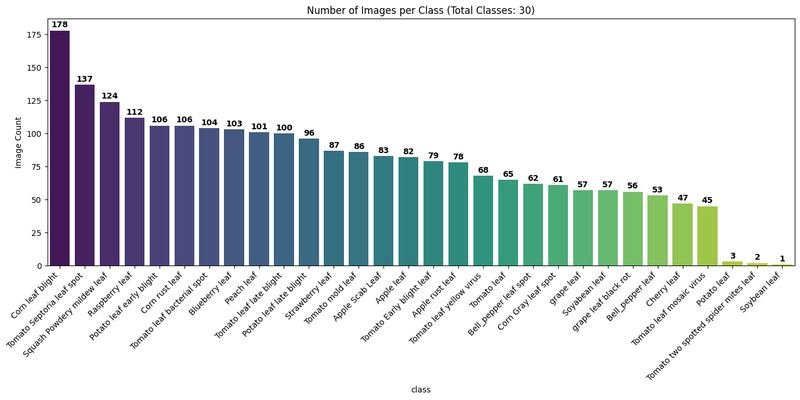

In [32]:
# 1. Calculate unique images per class
counts = train_annotation_df.groupby('class')['filename'].nunique().sort_values(ascending=False)

# 2. Get total number of unique classes
num_classes = train_annotation_df['class'].nunique()

# 3. Plot
plt.figure(figsize=(14, 7))
ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis')

# 4. Add numbers on top of bars
for i, v in enumerate(counts.values):
    ax.text(i, v + 1, str(v), ha='center', va='bottom', fontweight='bold')

# 5. Add the total class count to the title
plt.title(f"Number of Images per Class (Total Classes: {num_classes})")

# Rotate labels to 45 degrees
plt.xticks(rotation=45, ha='right')

plt.ylabel("Image Count")
plt.tight_layout()
plt.show()

In [33]:
test_annotation_df = pd.read_csv('/kaggle/working/test/test_annotations_clean.csv')

/tmp/ipykernel_99/4119573829.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis')


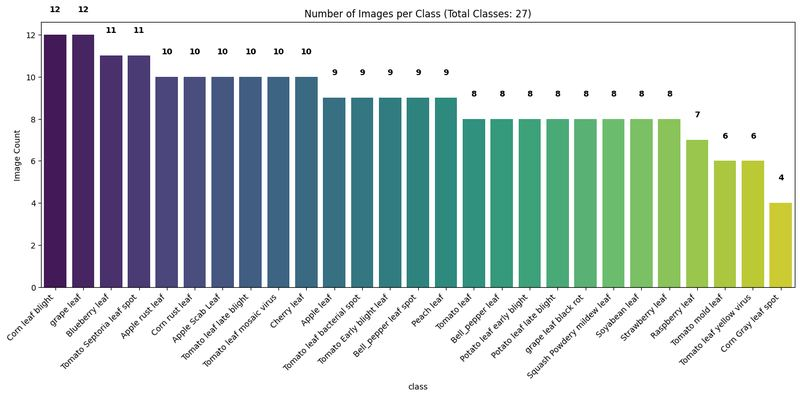

In [34]:
# 1. Calculate unique images per class
counts = test_annotation_df.groupby('class')['filename'].nunique().sort_values(ascending=False)

# 2. Get total number of unique classes
num_classes = test_annotation_df['class'].nunique()

# 3. Plot
plt.figure(figsize=(14, 7))
ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis')

# 4. Add numbers on top of bars
for i, v in enumerate(counts.values):
    ax.text(i, v + 1, str(v), ha='center', va='bottom', fontweight='bold')

# 5. Add the total class count to the title
plt.title(f"Number of Images per Class (Total Classes: {num_classes})")

# Rotate labels to 45 degrees
plt.xticks(rotation=45, ha='right')

plt.ylabel("Image Count")
plt.tight_layout()
plt.show()

**Checking the classes names that should be same in test and train data**

In [35]:
train_annotation_path = '/kaggle/working/train/train_annotations_clean.csv'
test_annotation_path = '/kaggle/working/test/test_annotations_clean.csv'

try:
    train_df = pd.read_csv(train_annotation_path)
    test_df = pd.read_csv(test_annotation_path)

    # Get the set of unique class names from each DataFrame
    train_classes = set(train_df['class'].unique())
    test_classes = set(test_df['class'].unique())

    # Compare the sets of class names
    if train_classes == test_classes:
        print("The unique class names in the train and test annotation files are the same.")
    else:
        print("The unique class names in the train and test annotation files are NOT the same.")
        # print the differences
        if train_classes - test_classes:
            print(f"Classes found in train but not in test: {train_classes - test_classes}")
        if test_classes - train_classes:
            print(f"Classes found in test but not in train: {test_classes - train_classes}")

except FileNotFoundError as e:
    print(f"Error: One of the annotation files was not found. {e}")
except KeyError:
    print("Error: 'class' column not found in one of the CSV files.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

The unique class names in the train and test annotation files are NOT the same.
Classes found in train but not in test: {'Tomato two spotted spider mites leaf', 'Potato leaf', 'Soybean leaf'}


**There is misspling in soybean name soyabean -> soybean**

In [36]:
train_annotation_df['class'] = train_annotation_df['class'].replace('Soybean leaf', 'Soyabean leaf')
print("Changed 'Soybean leaf' to 'Soyabean leaf'")

Changed 'Soybean leaf' to 'Soyabean leaf'


**Changing this photo label to Tomato Early blight leaf**

In [37]:
cell_name = "SpotSpeckBlightMite-1l4v879_jpg.rf.e5e1f97a7071fa00e99d282befc837d3.jpg"
train_annotation_df.loc[
    (train_annotation_df["filename"] == cell_name) &
    (train_annotation_df["class"] == "Tomato two spotted spider mites leaf"),
    "class"
] = "Tomato Early blight leaf"

print(f"Updated class for filename: {cell_name}")

Updated class for filename: SpotSpeckBlightMite-1l4v879_jpg.rf.e5e1f97a7071fa00e99d282befc837d3.jpg


**Deleting two redundent classes due to very small number of images inside of them**

In [38]:
train_annotation_df = train_annotation_df[~train_annotation_df['class'].isin(['Tomato two spotted spider mites leaf', 'Potato leaf'])]

In [39]:
train_annotation_df.to_csv('/kaggle/working/train/train_annotations_clean.csv', index=False)
print("Filtered annotations saved to /kaggle/working/train/train_annotations_clean.csv")

Filtered annotations saved to /kaggle/working/train/train_annotations_clean.csv


## **Making separated foldrs based on Training set**

**Making separate the images on training folder base on their classes**

In [40]:
# Get unique class names
unique_classes = train_annotation_df['class'].unique()

# Define the base output directory within train/images
output_base_dir = '/kaggle/working/train/images_by_class'

# Create the base output directory if it doesn't exist
os.makedirs(output_base_dir, exist_ok=True)

# Create a subdirectory for each unique class
for class_name in unique_classes:
    class_dir = os.path.join(output_base_dir, class_name.replace(" ", "_"))
    os.makedirs(class_dir, exist_ok=True)
    print(f"Created directory: {class_dir}")

print("\nFinished creating class directories within train/images.")

Created directory: /kaggle/working/train/images_by_class/Corn_rust_leaf
Created directory: /kaggle/working/train/images_by_class/Corn_leaf_blight
Created directory: /kaggle/working/train/images_by_class/Tomato_leaf_late_blight
Created directory: /kaggle/working/train/images_by_class/Apple_Scab_Leaf
Created directory: /kaggle/working/train/images_by_class/Tomato_Septoria_leaf_spot
Created directory: /kaggle/working/train/images_by_class/Tomato_mold_leaf
Created directory: /kaggle/working/train/images_by_class/Bell_pepper_leaf_spot
Created directory: /kaggle/working/train/images_by_class/Potato_leaf_early_blight
Created directory: /kaggle/working/train/images_by_class/grape_leaf_black_rot
Created directory: /kaggle/working/train/images_by_class/Tomato_leaf_yellow_virus
Created directory: /kaggle/working/train/images_by_class/Blueberry_leaf
Created directory: /kaggle/working/train/images_by_class/Bell_pepper_leaf
Created directory: /kaggle/working/train/images_by_class/Apple_rust_leaf
Cre

**Moving images in their folders base on their class names**

In [41]:
for _, row in train_annotation_df.iterrows():
    filename = unquote(row['filename'])
    dest_dir = os.path.join('/kaggle/working/train/images_by_class', row['class'].replace(" ", "_"))

    # Create folder and copy
    os.makedirs(dest_dir, exist_ok=True)
    shutil.copy(os.path.join('/kaggle/working/train/images', filename), dest_dir)

print("Finished copying images to class directories.")

Finished copying images to class directories.


# **EDA**

**Number of train images per class**

/tmp/ipykernel_99/3745393264.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis')


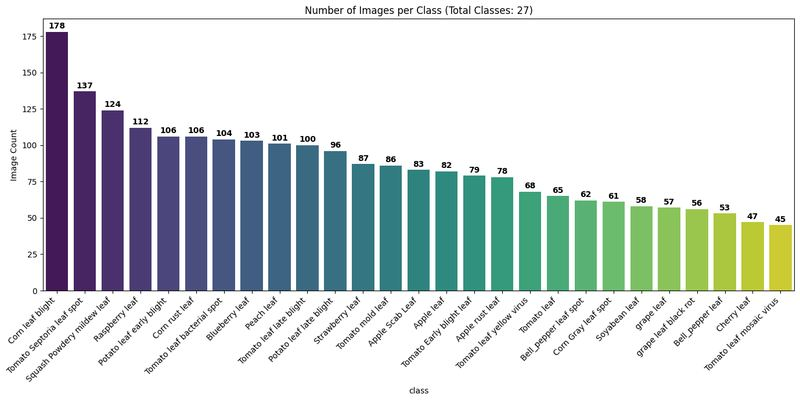

In [42]:
# 1. Calculate unique images per class
counts = train_annotation_df.groupby('class')['filename'].nunique().sort_values(ascending=False)

# 2. Get total number of unique classes
num_classes = train_annotation_df['class'].nunique()

# 3. Plot
plt.figure(figsize=(14, 7))
ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis')

# 4. Add numbers on top of bars
for i, v in enumerate(counts.values):
    ax.text(i, v + 1, str(v), ha='center', va='bottom', fontweight='bold')

# 5. Add the total class count to the title
plt.title(f"Number of Images per Class (Total Classes: {num_classes})")

# Rotate labels to 45 degrees
plt.xticks(rotation=45, ha='right')

plt.ylabel("Image Count")
plt.tight_layout()
plt.show()

**Number of train boundingboxes per class**

/tmp/ipykernel_99/4154669592.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis')


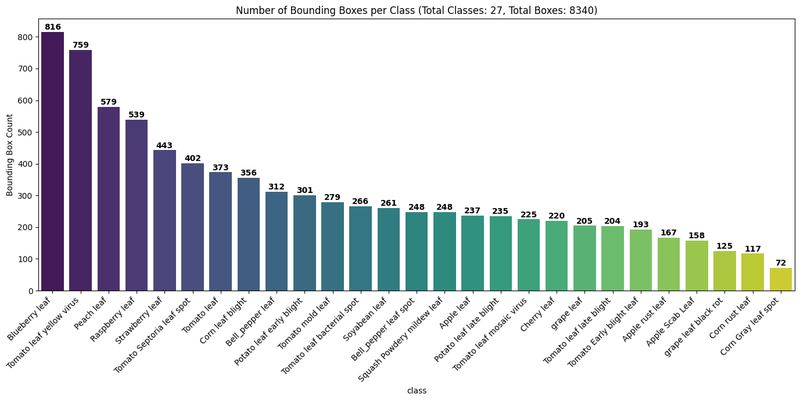

In [43]:
# 1. Count rows per class
counts = train_annotation_df['class'].value_counts()

# 2. Get statistics
num_classes = train_annotation_df['class'].nunique()
total_bboxes = len(train_annotation_df)  # Total rows = Total bounding boxes

# 3. Plot
plt.figure(figsize=(14, 7))
ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis')

# 4. Add numbers on top of bars
for i, v in enumerate(counts.values):
    ax.text(i, v + 1, str(v), ha='center', va='bottom', fontweight='bold')

# 5. Add Total Classes and Total Boxes to the title
plt.title(f"Number of Bounding Boxes per Class (Total Classes: {num_classes}, Total Boxes: {total_bboxes})")

# Rotate labels to 45 degrees
plt.xticks(rotation=45, ha='right')

plt.ylabel("Bounding Box Count")
plt.tight_layout()
plt.show()

**Display one sample of each class**

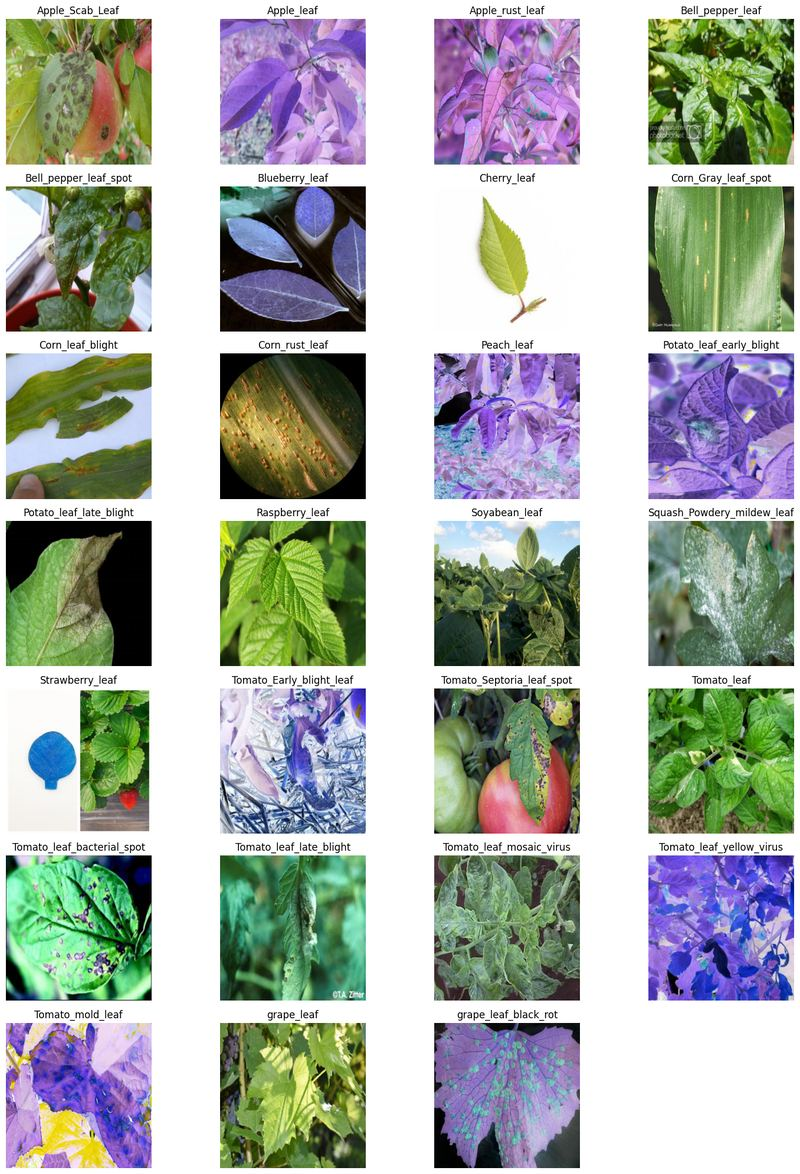

In [44]:
# Get list of directories
class_dirs = sorted(os.listdir('/kaggle/working/train/images_by_class'))

plt.figure(figsize=(15, 20))

for i, class_name in enumerate(class_dirs):
    class_dir = os.path.join('/kaggle/working/train/images_by_class', class_name)

    # Pick the first file directly
    first_image_file = sorted(os.listdir(class_dir))[0]  # Sort images alphabetically
    image_path = os.path.join(class_dir, first_image_file)

    # Load and plot directly
    img = mpimg.imread(image_path)

    plt.subplot(len(class_dirs) // 4 + 1, 4, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis('off')

plt.tight_layout()
plt.show()


**Scatter Plot of Image Sizes in Training Data**

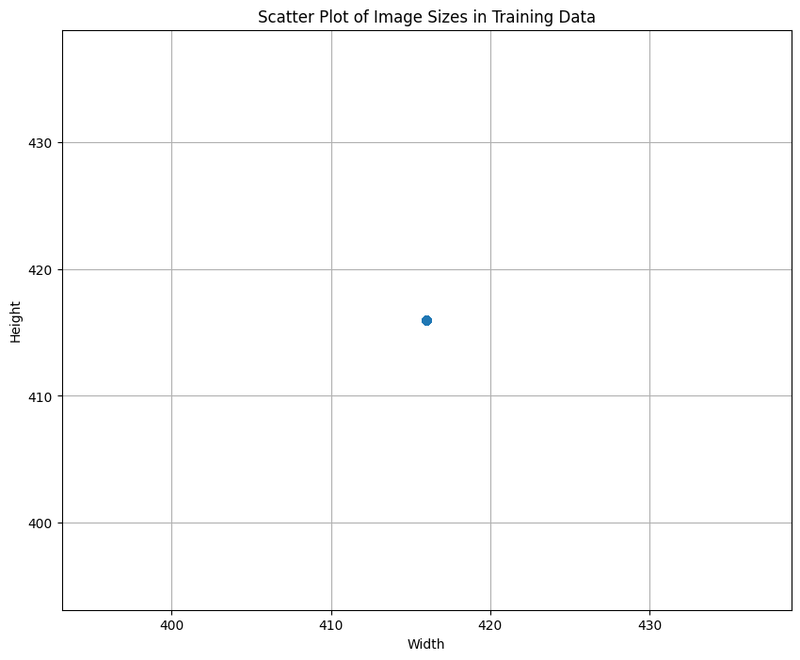

In [45]:
image_dir = "/kaggle/working/train/images"

# 1. Get all sizes directly
image_sizes = [Image.open(os.path.join(image_dir, f)).size for f in os.listdir(image_dir)]

# 2. Extract widths and heights
widths = [s[0] for s in image_sizes]
heights = [s[1] for s in image_sizes]

# 3. Plot
plt.figure(figsize=(10, 8))
plt.scatter(widths, heights, alpha=0.5)
plt.title("Scatter Plot of Image Sizes in Training Data")
plt.xlabel("Width")
plt.ylabel("Height")
plt.grid(True)
plt.show()

**Scatter Plot of Bounding Box Resolutions**

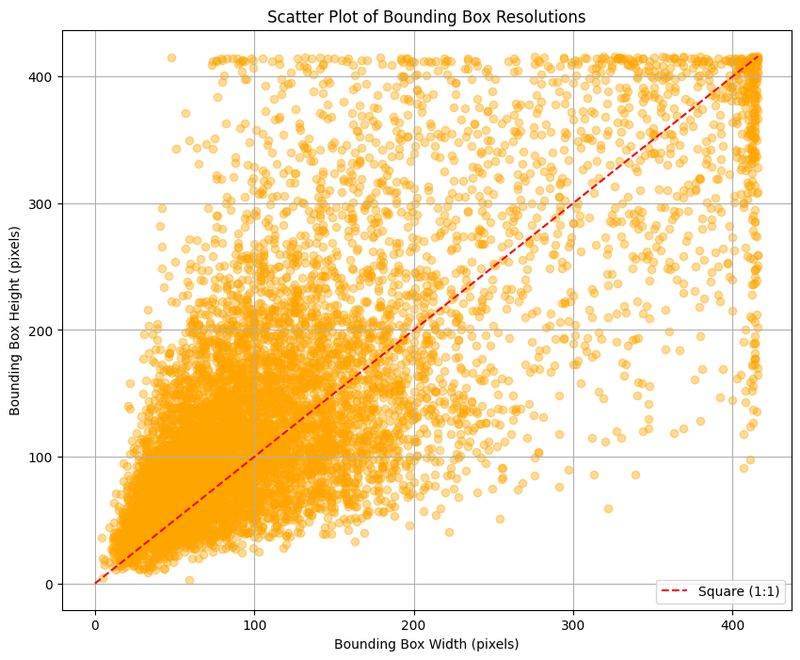

Min width:  4, Max width:  416
Min height: 3, Max height: 416


In [46]:
# Compute bbox width and height
bbox_widths = (train_annotation_df["xmax"] - train_annotation_df["xmin"]).values
bbox_heights = (train_annotation_df["ymax"] - train_annotation_df["ymin"]).values

plt.figure(figsize=(10, 8))

# 1. Changed color to orange
plt.scatter(bbox_widths, bbox_heights, alpha=0.4, color='orange')

# 2. Add diagonal reference line
max_dim = max(bbox_widths.max(), bbox_heights.max())
plt.plot([0, max_dim], [0, max_dim], color='red', linestyle='--', label='Square (1:1)')

plt.title("Scatter Plot of Bounding Box Resolutions")
plt.xlabel("Bounding Box Width (pixels)")
plt.ylabel("Bounding Box Height (pixels)")
plt.legend()
plt.grid(True)
plt.show()

# Print stats
print(f"Min width:  {bbox_widths.min()}, Max width:  {bbox_widths.max()}")
print(f"Min height: {bbox_heights.min()}, Max height: {bbox_heights.max()}")

**Display images with their bounding boxes**

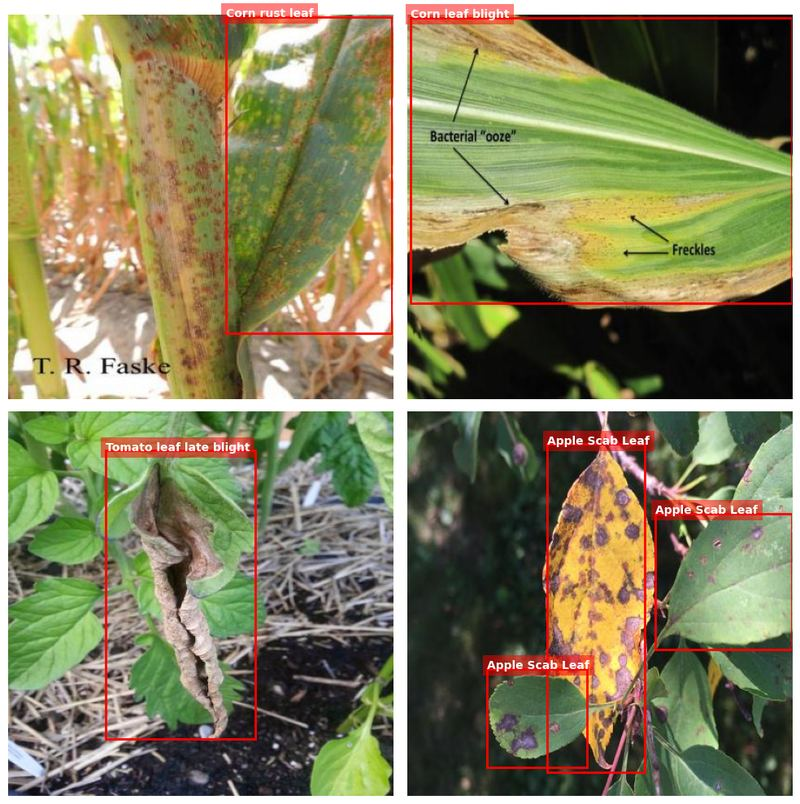

In [47]:
# 1. Select the FIRST 4 unique images
samples = list(train_annotation_df['filename'].unique())[:4]


# 2. Setup grid
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# 3. Plot images, boxes, and labels
for i, filename in enumerate(samples):
    ax = axes[i//2, i%2]
    try:
        ax.imshow(Image.open(f"{'/kaggle/working/train/images'}/{filename}"))
    except FileNotFoundError:
        print(f"File not found: {filename}")
        continue

    # Add boxes and labels
    for _, row in train_annotation_df[train_annotation_df['filename'] == filename].iterrows():
        rect = patches.Rectangle((row['xmin'], row['ymin']), row['xmax']-row['xmin'], row['ymax']-row['ymin'],
                                 linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
        ax.text(row['xmin'], row['ymin'], row['class'], color='white', fontsize=10, weight='bold',
                bbox=dict(facecolor='red', alpha=0.5, edgecolor='none'))

    ax.axis('off')

plt.tight_layout()
plt.show()

**Detecting undersize bounding boxes test and train**

[TRAIN] Number of small bounding boxes (< 10px): 9
[TRAIN] Number of images containing small boxes: 4


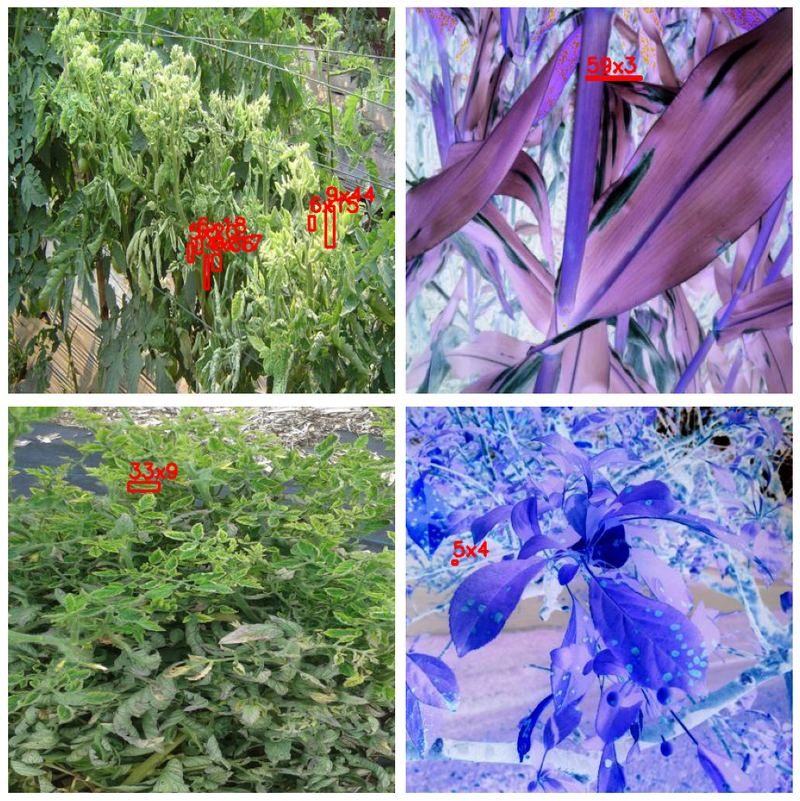

[TEST] Number of small bounding boxes (< 10px): 0
[TEST] Number of images containing small boxes: 0


In [48]:
# CONFIG
MIN_PX = 10

# TRAIN
TRAIN_IMAGE_DIR = "/kaggle/working/train/images"
TRAIN_ANN_DF = train_annotation_df

# TEST
TEST_IMAGE_DIR = "/kaggle/working/test/images"
TEST_ANN_DF = test_annotation_df

def get_bbox_sizes(df, img_dir):
    df = df.copy()

    # Support for xmin/xmax or width/height columns
    if 'xmin' in df.columns and 'xmax' in df.columns:
        df['bbox_w_px'] = (df['xmax'] - df['xmin']).abs()
        df['bbox_h_px'] = (df['ymax'] - df['ymin']).abs()
    elif 'width' in df.columns and 'height' in df.columns:
        df['bbox_w_px'] = df['width'].abs()
        df['bbox_h_px'] = df['height'].abs()
    else:
        raise ValueError("No supported bbox columns found (need xmin/ymin/xmax/ymax OR width/height).")

    # Handle normalized coordinates (0..1)
    if df['bbox_w_px'].max() <= 1.1:
        for idx, row in df.iterrows():
            img_path = os.path.join(img_dir, str(row['filename']))
            img = cv2.imread(img_path)
            if img is not None:
                h, w = img.shape[:2]
                df.at[idx, 'bbox_w_px'] *= w
                df.at[idx, 'bbox_h_px'] *= h

    return df

def show_grid_examples(df, img_dir, split_name=""):
    tiny = df[(df['bbox_w_px'] < MIN_PX) | (df['bbox_h_px'] < MIN_PX)]

    # stats
    num_tiny_boxes = len(tiny)
    num_tiny_images = tiny['filename'].nunique()
    print(f"[{split_name}] Number of small bounding boxes (< {MIN_PX}px): {num_tiny_boxes}")
    print(f"[{split_name}] Number of images containing small boxes: {num_tiny_images}")

    if tiny.empty:
        return

    example_files = tiny['filename'].unique()[:4]
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))
    axes = axes.flatten()

    for i in range(4):
        if i < len(example_files):
            fname = example_files[i]
            img = cv2.imread(os.path.join(img_dir, fname))
            if img is None:
                axes[i].axis('off')
                continue

            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            boxes = tiny[tiny['filename'] == fname]

            for _, row in boxes.iterrows():
                x, y = int(row.get('xmin', 0)), int(row.get('ymin', 0))
                w, h = int(row['bbox_w_px']), int(row['bbox_h_px'])
                cv2.rectangle(img, (x, y), (x+w, y+h), (255, 0, 0), 2)
                cv2.putText(img, f"{int(w)}x{int(h)}", (x, max(0, y-5)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,0,0), 2)

            axes[i].imshow(img)
        axes[i].axis('off')  # Remove names and axes

    plt.tight_layout()
    plt.show()

# RUN: TRAIN
train_ann_with_sizes = get_bbox_sizes(TRAIN_ANN_DF, TRAIN_IMAGE_DIR)
show_grid_examples(train_ann_with_sizes, TRAIN_IMAGE_DIR, split_name="TRAIN")

# RUN: TEST
test_ann_with_sizes = get_bbox_sizes(TEST_ANN_DF, TEST_IMAGE_DIR)
show_grid_examples(test_ann_with_sizes, TEST_IMAGE_DIR, split_name="TEST")

**Bounding boxes aspect ratios**

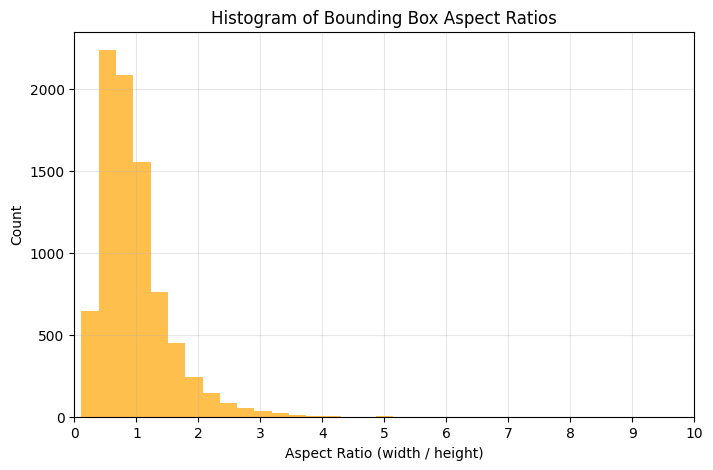

In [49]:
# Compute aspect ratios
widths = (train_annotation_df["xmax"] - train_annotation_df["xmin"]).values
heights = (train_annotation_df["ymax"] - train_annotation_df["ymin"]).values
aspect_ratios = widths / np.maximum(heights, 1e-6)

# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(aspect_ratios, bins=70, color='orange', alpha=0.7)
plt.title("Histogram of Bounding Box Aspect Ratios")
plt.xlabel("Aspect Ratio (width / height)")
plt.ylabel("Count")
plt.xlim(0, 10)

# Set x-axis intervals to 1
plt.xticks(np.arange(0, 11, 1))

plt.grid(alpha=0.3)
plt.show()


**Box plot of brightness of each class**

/tmp/ipykernel_99/1527138323.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([brightness_by_class[c] for c in classes], labels=classes, showfliers=False)


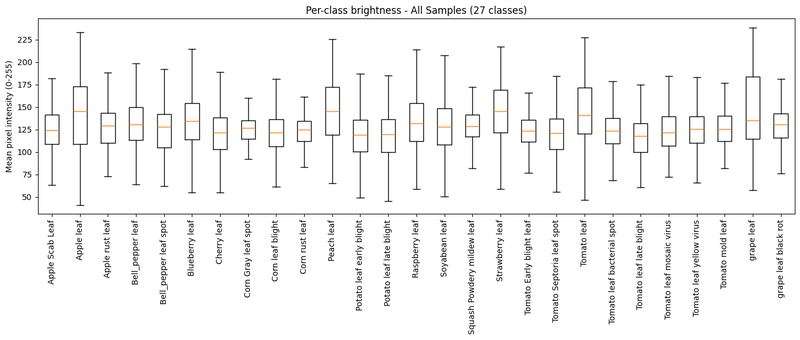

In [50]:
classes = sorted(train_annotation_df["class"].unique())
brightness_by_class = {c: [] for c in classes}
# Removed max_samples limitation

for img_name, group in train_annotation_df.groupby("filename"):
    img_path = os.path.join('/kaggle/working/train/images', img_name)
    img = cv2.imread(img_path)
    if img is None: continue

    # Speed optimization convert full image to gray once per file
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h, w = gray_img.shape

    for _, row in group.iterrows():
        # Clip coordinates to image boundaries
        x1, x2 = np.clip([int(row["xmin"]), int(row["xmax"])], 0, w)
        y1, y2 = np.clip([int(row["ymin"]), int(row["ymax"])], 0, h)

        if x2 > x1 and y2 > y1:
            # Extract mean from the already-grayscale image
            brightness_by_class[row["class"]].append(float(gray_img[y1:y2, x1:x2].mean()))

# Prepare and plot
plt.figure(figsize=(14,6))
plt.boxplot([brightness_by_class[c] for c in classes], labels=classes, showfliers=False)
plt.xticks(rotation=90)
plt.ylabel("Mean pixel intensity (0-255)")
plt.title(f"Per-class brightness - All Samples ({len(classes)} classes)")
plt.tight_layout()
plt.show()

**Box plot of contrast of each class**

/tmp/ipykernel_99/2915137678.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([contrast_by_class[c] for c in classes], labels=classes, showfliers=False)


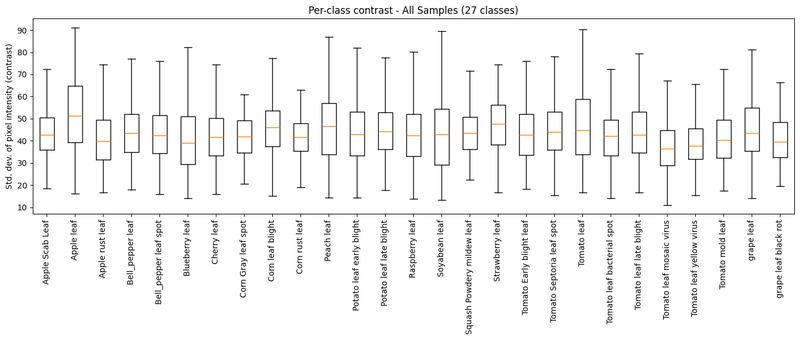

In [51]:
classes = sorted(train_annotation_df["class"].unique())
contrast_by_class = {c: [] for c in classes}

# Group by filename to process each image exactly once
for img_name, group in train_annotation_df.groupby("filename"):
    img_path = os.path.join('/kaggle/working/train/images', img_name)
    img = cv2.imread(img_path)
    if img is None: continue

    # Speed: Convert full image to gray once per file
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h, w = gray_img.shape

    for _, row in group.iterrows():
        # Clip coordinates to image boundaries
        x1, x2 = np.clip([int(row["xmin"]), int(row["xmax"])], 0, w)
        y1, y2 = np.clip([int(row["ymin"]), int(row["ymax"])], 0, h)

        if x2 > x1 and y2 > y1:
            # Contrast = Standard Deviation of pixel intensities
            contrast_by_class[row["class"]].append(float(gray_img[y1:y2, x1:x2].std()))

# Plotting
plt.figure(figsize=(14, 6))
plt.boxplot([contrast_by_class[c] for c in classes], labels=classes, showfliers=False)
plt.xticks(rotation=90)
plt.ylabel("Std. dev. of pixel intensity (contrast)")
plt.title(f"Per-class contrast - All Samples ({len(classes)} classes)")
plt.tight_layout()
plt.show()

**Box plot of sharpness of each class**

/tmp/ipykernel_99/2706846629.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([sharpness_by_class[c] for c in classes], labels=classes, showfliers=False)


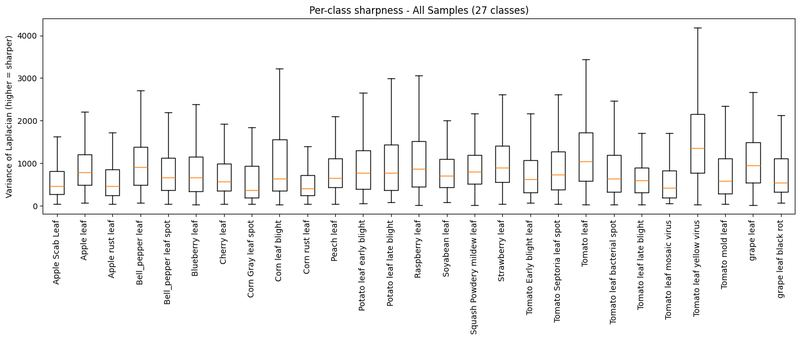

In [52]:
classes = sorted(train_annotation_df["class"].unique())
sharpness_by_class = {c: [] for c in classes}

for img_name, group in train_annotation_df.groupby("filename"):
    img_path = os.path.join('/kaggle/working/train/images', img_name)
    img = cv2.imread(img_path)
    if img is None:
        continue

    # Convert full image to gray once per file
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h, w = gray_img.shape

    for _, row in group.iterrows():
        # Clip coordinates to image boundaries
        x1, x2 = np.clip([int(row["xmin"]), int(row["xmax"])], 0, w)
        y1, y2 = np.clip([int(row["ymin"]), int(row["ymax"])], 0, h)

        if x2 > x1 and y2 > y1:
            patch = gray_img[y1:y2, x1:x2]

            # Sharpness metric Variance of Laplacian
            lap = cv2.Laplacian(patch, cv2.CV_64F)
            sharpness = float(lap.var())

            sharpness_by_class[row["class"]].append(sharpness)

# Plot
plt.figure(figsize=(14, 6))
plt.boxplot([sharpness_by_class[c] for c in classes], labels=classes, showfliers=False)
plt.xticks(rotation=90)
plt.ylabel("Variance of Laplacian (higher = sharper)")
plt.title(f"Per-class sharpness - All Samples ({len(classes)} classes)")
plt.tight_layout()
plt.show()

**Average RGB Color Distribution Heatmap**

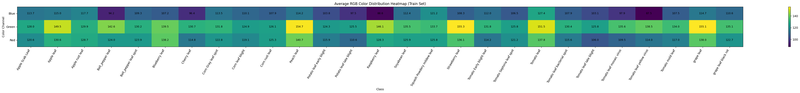

In [53]:
IMG_DIR = "/kaggle/working/train/images"
DF = train_annotation_df

def get_fname_col(df):
    for c in ["filename","image","image_name","file","path"]:
        if c in df.columns: return c
    raise ValueError("No filename column found.")

def detect_fmt(df):
    if all(c in df.columns for c in ["xmin","ymin","xmax","ymax"]):
        cols = ("xmin","ymin","xmax","ymax")
        norm = df[list(cols)].astype(float).max().max() <= 1.5
        return ("corners", cols, norm)
    if all(c in df.columns for c in ["x_center","y_center","width","height"]):
        cols = ("x_center","y_center","width","height")
        norm = df[list(cols)].astype(float).max().max() <= 1.5
        return ("yolo", cols, norm)
    raise ValueError("No bbox columns found (need xmin..ymax OR x_center..height).")

def to_px(row, fmt, W, H):
    mode, cols, norm = fmt
    if mode == "corners":
        x1,y1,x2,y2 = [float(row[c]) for c in cols]
        if norm: x1,y1,x2,y2 = x1*W, y1*H, x2*W, y2*H
    else:
        xc,yc,bw,bh = [float(row[c]) for c in cols]
        if norm: xc,yc,bw,bh = xc*W, yc*H, bw*W, bh*H
        x1,y1,x2,y2 = xc-bw/2, yc-bh/2, xc+bw/2, yc+bh/2

    x1 = int(max(0, min(W-1, x1))); x2 = int(max(0, min(W-1, x2)))
    y1 = int(max(0, min(H-1, y1))); y2 = int(max(0, min(H-1, y2)))
    return None if (x2 <= x1 or y2 <= y1) else (x1,y1,x2,y2)

_img_cache = {}
def read_rgb(path):
    if path in _img_cache: return _img_cache[path]
    bgr = cv2.imread(path)
    rgb = None if bgr is None else cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    _img_cache[path] = rgb
    return rgb

# compute per-class average RGB
FC  = get_fname_col(DF)
FMT = detect_fmt(DF)

classes = sorted(DF["class"].astype(str).unique())
rgb_by_class = {c: [] for c in classes}  # store [R,G,B] per bbox

for img_name, group in DF.groupby(FC):
    img_path = img_name if (str(img_name).startswith("/") or os.path.isabs(str(img_name))) else os.path.join(IMG_DIR, str(img_name))
    img = read_rgb(img_path)
    if img is None:
        continue

    H, W = img.shape[:2]

    for _, r in group.iterrows():
        bb = to_px(r, FMT, W, H)
        if bb is None:
            continue
        x1,y1,x2,y2 = bb
        crop = img[y1:y2, x1:x2]
        if crop.size == 0:
            continue

        # mean over crop in RGB order
        m = crop.reshape(-1, 3).mean(axis=0)  # [R,G,B]
        rgb_by_class[str(r["class"])].append(m)

# build 3 x C matrix in row order: Blue, Green, Red
mat = np.zeros((3, len(classes)), dtype=float)
for j, c in enumerate(classes):
    if len(rgb_by_class[c]) == 0:
        mat[:, j] = np.nan
    else:
        mean_rgb = np.mean(np.vstack(rgb_by_class[c]), axis=0)  # [R,G,B]
        mat[:, j] = [mean_rgb[2], mean_rgb[1], mean_rgb[0]]    # [B,G,R]

# plot heatmap
plt.figure(figsize=(1.4*len(classes) + 6, 4.5))
im = plt.imshow(mat, aspect="auto")
plt.colorbar(im)

plt.yticks([0,1,2], ["Blue", "Green", "Red"])
plt.xticks(range(len(classes)), classes, rotation=60, ha="right")
plt.xlabel("Class")
plt.ylabel("Color Channel")
plt.title("Average RGB Color Distribution Heatmap (Train Set)")

# annotate values
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat[i, j]
        if np.isfinite(v):
            plt.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9)

plt.tight_layout()
plt.show()

# **Data Preprocessing**

## **Handling negative images**

**Msking backup folder of original train images**

In [54]:
# Copy the entire directory
shutil.copytree('/kaggle/working/train/images', '/kaggle/working/train/img_backup')
print(f"Copied '{'/kaggle/working/train/images'}' to '{'/kaggle/working/train/img_backup'}'")

Copied '/kaggle/working/train/images' to '/kaggle/working/train/img_backup'


**Handling negative images in both train and test set**

In [55]:
splits = {"train": "/kaggle/working/train/images", "test": "/kaggle/working/test/images"}

def is_negative_leaf(img_bgr):
    # Tuple unpacking for channel means
    mean_b, mean_g, mean_r = [img_bgr[:, :, i].mean() for i in range(3)]
    if not (mean_g < mean_r and mean_g < mean_b): return False

    inv = 255 - img_bgr
    inv_mean_b, inv_mean_g, inv_mean_r = [inv[:, :, i].mean() for i in range(3)]
    return inv_mean_g > inv_mean_r and inv_mean_g > inv_mean_b

def write_image_atomic(dst_path, img_bgr):
    folder, suffix = os.path.dirname(dst_path), os.path.splitext(dst_path)[1]
    fd, tmp_path = tempfile.mkstemp(dir=folder, suffix=suffix)
    os.close(fd)
    if cv2.imwrite(tmp_path, img_bgr):
        os.replace(tmp_path, dst_path)
    else:
        if os.path.exists(tmp_path): os.remove(tmp_path)
        raise RuntimeError(f"cv2.imwrite failed for {tmp_path}")

global_total = global_fixed = global_normal = 0
fixed_negatives_by_split = {}

for split_name, input_dir in splits.items():
    if not os.path.isdir(input_dir): continue

    all_files = [f for f in os.listdir(input_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    fixed_negatives, normal_images = [], []

    print(f"\n=== Scanning '{split_name}' (IN-PLACE) ===")
    for fname in tqdm(all_files, desc=f"Fixing negatives in {split_name}"):
        img_path = os.path.join(input_dir, fname)
        img = cv2.imread(img_path)
        if img is None: continue

        if is_negative_leaf(img):
            try:
                write_image_atomic(img_path, 255 - img)
                fixed_negatives.append(fname)
            except Exception as e: print(f"[WARN] Failed to overwrite {img_path}: {e}")
        else:
            normal_images.append(fname)

    total, num_fixed, num_normal = len(all_files), len(fixed_negatives), len(normal_images)
    print(f"\n=== SUMMARY for '{split_name}' ===\nTotal: {total}\nFixed: {num_fixed}\nNormal: {num_normal}")
    if total > 0: print(f"Percentage negative: {num_fixed / total * 100:.2f}%")

    fixed_negatives_by_split[split_name] = {"input_dir": input_dir, "fixed_files": fixed_negatives}
    global_total += total; global_fixed += num_fixed; global_normal += num_normal

print(f"\n=== GLOBAL SUMMARY ===\nScanned: {global_total}\nFixed: {global_fixed}\nNormal: {global_normal}")
if global_total > 0: print(f"Overall percentage: {global_fixed / global_total * 100:.2f}%")


=== Scanning 'train' (IN-PLACE) ===


Fixing negatives in train: 100%|██████████| 2318/2318 [00:04<00:00, 488.30it/s]



=== SUMMARY for 'train' ===
Total: 2318
Fixed: 521
Normal: 1797
Percentage negative: 22.48%

=== Scanning 'test' (IN-PLACE) ===


Fixing negatives in test: 100%|██████████| 238/238 [00:00<00:00, 518.08it/s]


=== SUMMARY for 'test' ===
Total: 238
Fixed: 42
Normal: 196
Percentage negative: 17.65%

=== GLOBAL SUMMARY ===
Scanned: 2556
Fixed: 563
Normal: 1993
Overall percentage: 22.03%


**Displaying of fixed images**

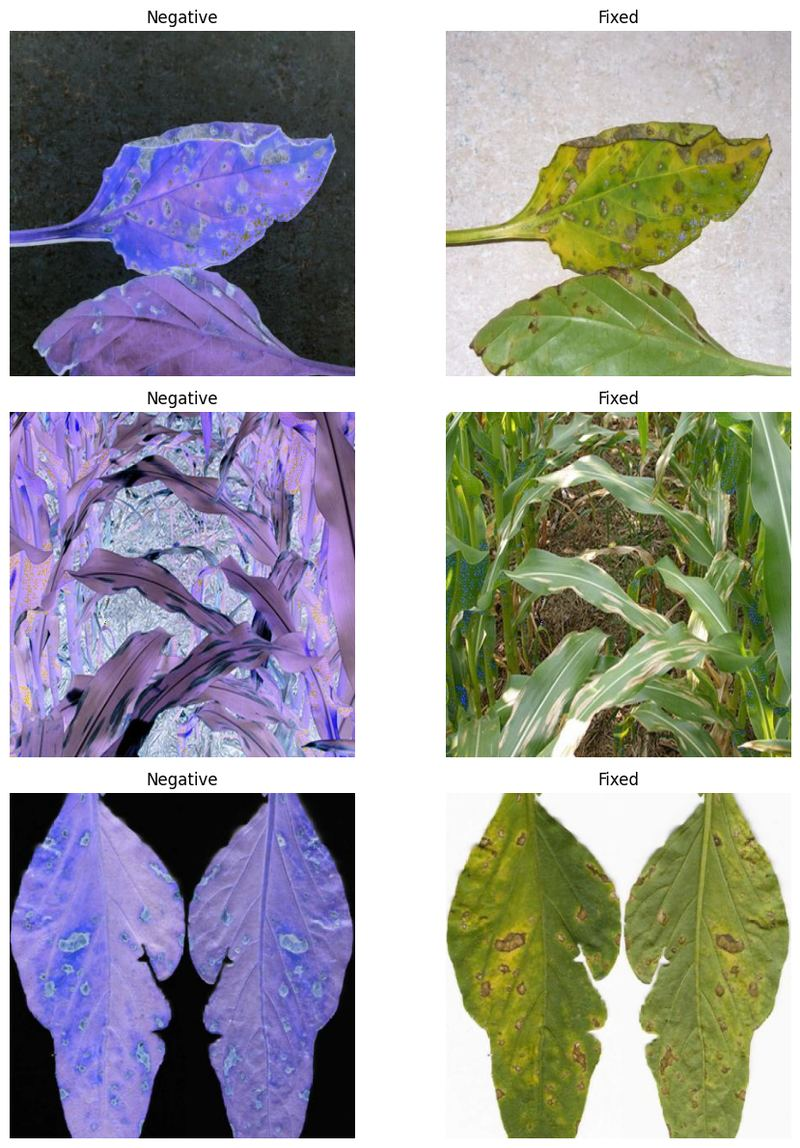

In [56]:
split_to_show, N_SHOW = "train", 3
backup_root_train, backup_root_test = "/kaggle/working/train/img_backup", "/kaggle/working/test/img_backup"

info = fixed_negatives_by_split.get(split_to_show, {})
fixed_files = info.get("fixed_files", [])
backup_dir = backup_root_train if split_to_show == "train" else backup_root_test

def load_rgb(p):
    img = cv2.imread(p)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img is not None else None

# Filter to only existing pairs
valid_pairs = []
for f in fixed_files[:N_SHOW]:
    b_path, a_path = os.path.join(backup_dir, f), os.path.join(info["input_dir"], f)
    if os.path.exists(b_path):
        b_img, a_img = load_rgb(b_path), load_rgb(a_path)
        if b_img is not None and a_img is not None:
            valid_pairs.append((b_img, a_img))

if not valid_pairs:
    print("No valid before/after pairs found.")
else:
    # Plot all pairs in one grid
    fig, axes = plt.subplots(len(valid_pairs), 2, figsize=(10, 4 * len(valid_pairs)))
    axes = axes.reshape(-1, 2) # Ensure 2D for single pair case

    for i, (before, after) in enumerate(valid_pairs):
        for j, (img, title) in enumerate([(before, "Negative"), (after, "Fixed")]):
            axes[i, j].imshow(img)
            axes[i, j].set_title(title)
            axes[i, j].axis("off")

    plt.tight_layout()
    plt.show()

## **Handling small bounding boxes**

In [57]:
TRAIN_CSV_PATH = "/kaggle/working/train/train_annotations_clean.csv"
TRAIN_IMG_DIR  = "/kaggle/working/train/images"
TRAIN_OVERWRITE = True

TEST_CSV_PATH = "/kaggle/working/test/test_annotations_clean.csv"
TEST_IMG_DIR  = "/kaggle/working/test/images"
TEST_OVERWRITE = True

exts = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.tif", "*.tiff", "*.webp")

#  TRAIN
tiny_mask = (train_ann_with_sizes["bbox_w_px"] < MIN_PX) | (train_ann_with_sizes["bbox_h_px"] < MIN_PX)
kept_df = train_ann_with_sizes[~tiny_mask].copy()

# drop helper columns before saving
final_df = kept_df.drop(columns=["bbox_w_px", "bbox_h_px"], errors="ignore")

out_path = TRAIN_CSV_PATH if TRAIN_OVERWRITE else TRAIN_CSV_PATH.replace(".csv", "_filtered.csv")
final_df.to_csv(out_path, index=False)

# update the main df we use later
train_annotation_df = final_df
print(f"[TRAIN] Removed {tiny_mask.sum()} tiny boxes. New count: {len(train_annotation_df)}")

# delete train images that now have no boxes
annotated = set(train_annotation_df["filename"].dropna().astype(str).unique())

train_img_paths = []
for e in exts:
    train_img_paths += glob.glob(os.path.join(TRAIN_IMG_DIR, e))

removed_imgs = 0
for p in train_img_paths:
    if os.path.basename(p) not in annotated:
        os.remove(p)
        removed_imgs += 1

print(f"[TRAIN] Removed {removed_imgs} images with zero boxes after filtering.")

# TEST
test_tiny_mask = (test_ann_with_sizes["bbox_w_px"] < MIN_PX) | (test_ann_with_sizes["bbox_h_px"] < MIN_PX)
test_kept_df = test_ann_with_sizes[~test_tiny_mask].copy()

test_final_df = test_kept_df.drop(columns=["bbox_w_px", "bbox_h_px"], errors="ignore")

test_out_path = TEST_CSV_PATH if TEST_OVERWRITE else TEST_CSV_PATH.replace(".csv", "_filtered.csv")
test_final_df.to_csv(test_out_path, index=False)

test_annotation_df = test_final_df
print(f"[TEST] Removed {test_tiny_mask.sum()} tiny boxes. New count: {len(test_annotation_df)}")

test_annotated = set(test_annotation_df["filename"].dropna().astype(str).unique())

test_img_paths = []
for e in exts:
    test_img_paths += glob.glob(os.path.join(TEST_IMG_DIR, e))

test_removed_imgs = 0
for p in test_img_paths:
    if os.path.basename(p) not in test_annotated:
        os.remove(p)
        test_removed_imgs += 1

print(f"[TEST] Removed {test_removed_imgs} images with zero boxes after filtering.")


[TRAIN] Removed 9 tiny boxes. New count: 8331
[TRAIN] Removed 0 images with zero boxes after filtering.
[TEST] Removed 0 tiny boxes. New count: 454
[TEST] Removed 0 images with zero boxes after filtering.


## **Handling brightness**


[TRAIN] boxes before: 8331
[TRAIN] too dark: 3 | too bright: 0
[TRAIN] boxes after: 8328


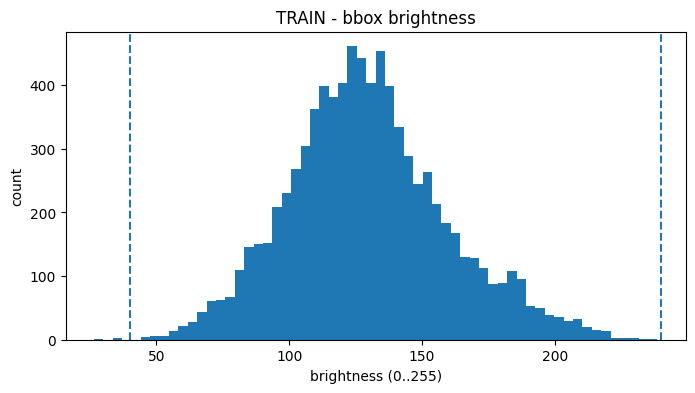

[TRAIN] examples (too dark)


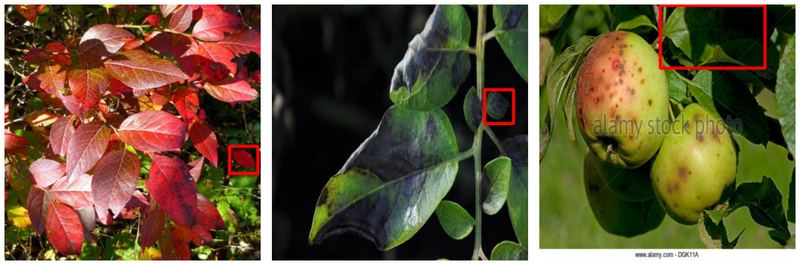

[TRAIN] examples (too bright)
No examples to show.
[TRAIN] removed images with no boxes: 0
[TRAIN] saved csv: /kaggle/working/train/train_annotations_clean.csv

[TEST] boxes before: 454
[TEST] too dark: 0 | too bright: 0
[TEST] boxes after: 454


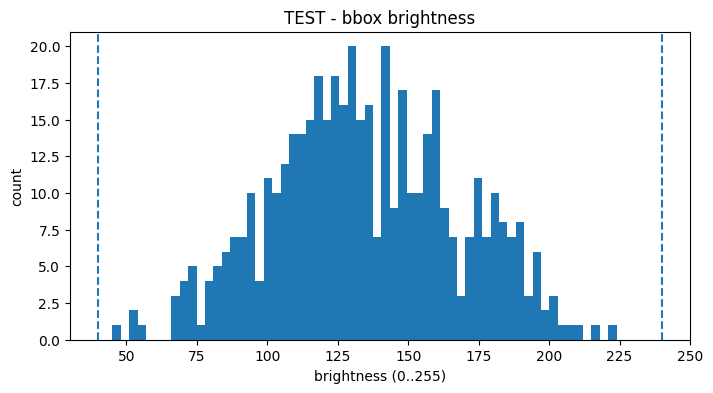

[TEST] examples (too dark)
No examples to show.
[TEST] examples (too bright)
No examples to show.
[TEST] removed images with no boxes: 0
[TEST] saved csv: /kaggle/working/test/test_annotations_clean.csv


In [58]:
# bbox brightness limits
DARK_THR, BRIGHT_THR = 40, 240

TRAIN_CSV_PATH = "/kaggle/working/train/train_annotations_clean.csv"
TRAIN_IMG_DIR  = "/kaggle/working/train/images"
TRAIN_OVERWRITE_CSV = True
TRAIN_DF = train_annotation_df

TEST_CSV_PATH = "/kaggle/working/test/test_annotations_clean.csv"
TEST_IMG_DIR  = "/kaggle/working/test/images"
TEST_OVERWRITE_CSV = True
TEST_DF = test_annotation_df


def resolve_path(img_dir, name):
    name = str(name)
    if os.path.isabs(name) or name.startswith("/"):
        return name
    return os.path.join(img_dir, name)


def show_examples(df_subset, img_dir, n=3):
    # show full image with only the bbox
    if df_subset.empty:
        print("No examples to show.")
        return

    ex = df_subset.head(n)
    plt.figure(figsize=(6 * len(ex), 6))

    for i, (_, r) in enumerate(ex.iterrows(), 1):
        img = cv2.imread(resolve_path(img_dir, r["filename"]))
        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]

        x1 = int(max(0, min(W - 1, r["xmin"])))
        y1 = int(max(0, min(H - 1, r["ymin"])))
        x2 = int(max(0, min(W - 1, r["xmax"])))
        y2 = int(max(0, min(H - 1, r["ymax"])))
        if x2 <= x1 or y2 <= y1:
            continue

        vis = img.copy()
        cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 0, 0), 3)

        plt.subplot(1, len(ex), i)
        plt.imshow(vis)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


def run_brightness_filter(df, img_dir, csv_path, overwrite_csv=True, split_name=""):
    ann = df.copy()

    bvals = pd.Series(np.nan, index=ann.index, dtype="float32")
    ok = pd.Series(False, index=ann.index)

    # group by filename so we read each image once
    for fname, g in ann.groupby("filename"):
        img = cv2.imread(resolve_path(img_dir, fname))
        if img is None:
            continue

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        H, W = gray.shape

        for idx, r in g.iterrows():
            x1 = int(max(0, min(W - 1, r["xmin"])))
            y1 = int(max(0, min(H - 1, r["ymin"])))
            x2 = int(max(0, min(W - 1, r["xmax"])))
            y2 = int(max(0, min(H - 1, r["ymax"])))
            if x2 <= x1 or y2 <= y1:
                continue

            crop = gray[y1:y2, x1:x2]
            if crop.size == 0:
                continue

            bvals.loc[idx] = float(crop.mean())
            ok.loc[idx] = True

    ann["bbox_brightness"] = bvals
    ann["_ok"] = ok

    valid = ann["_ok"] & ann["bbox_brightness"].notna()
    dark_mask = valid & (ann["bbox_brightness"] < DARK_THR)
    bright_mask = valid & (ann["bbox_brightness"] > BRIGHT_THR)
    remove_mask = dark_mask | bright_mask

    kept_df = ann[~remove_mask].copy()

    print(f"\n[{split_name}] boxes before: {len(ann)}")
    print(f"[{split_name}] too dark: {int(dark_mask.sum())} | too bright: {int(bright_mask.sum())}")
    print(f"[{split_name}] boxes after: {len(kept_df)}")

    # histogram just to see the distribution
    vals = ann.loc[valid, "bbox_brightness"].values
    plt.figure(figsize=(8, 4))
    plt.hist(vals, bins=60)
    plt.axvline(DARK_THR, linestyle="--")
    plt.axvline(BRIGHT_THR, linestyle="--")
    plt.title(f"{split_name} - bbox brightness")
    plt.xlabel("brightness (0..255)")
    plt.ylabel("count")
    plt.show()

    print(f"[{split_name}] examples (too dark)")
    show_examples(ann[dark_mask], img_dir, n=3)

    print(f"[{split_name}] examples (too bright)")
    show_examples(ann[bright_mask], img_dir, n=3)

    # if an image has zero boxes left, remove the image file too
    orig_imgs = set(df["filename"].dropna().astype(str).unique())
    kept_imgs = set(kept_df["filename"].dropna().astype(str).unique())
    to_delete = orig_imgs - kept_imgs

    deleted = 0
    for name in to_delete:
        p = resolve_path(img_dir, name)
        if os.path.exists(p):
            os.remove(p)
            deleted += 1

    print(f"[{split_name}] removed images with no boxes: {deleted}")

    out_path = csv_path if overwrite_csv else csv_path.replace(".csv", "_brightness_filtered.csv")
    kept_df.drop(columns=["bbox_brightness", "_ok"], errors="ignore").to_csv(out_path, index=False)
    print(f"[{split_name}] saved csv: {out_path}")

    return kept_df.drop(columns=["bbox_brightness", "_ok"], errors="ignore").copy()


train_annotation_df = run_brightness_filter(
    TRAIN_DF, TRAIN_IMG_DIR, TRAIN_CSV_PATH,
    overwrite_csv=TRAIN_OVERWRITE_CSV,
    split_name="TRAIN"
)

test_annotation_df = run_brightness_filter(
    TEST_DF, TEST_IMG_DIR, TEST_CSV_PATH,
    overwrite_csv=TEST_OVERWRITE_CSV,
    split_name="TEST"
)


## **Handling contrast**


[TRAIN] boxes before: 8328
[TRAIN] low contrast (<15): 9
[TRAIN] boxes after: 8319


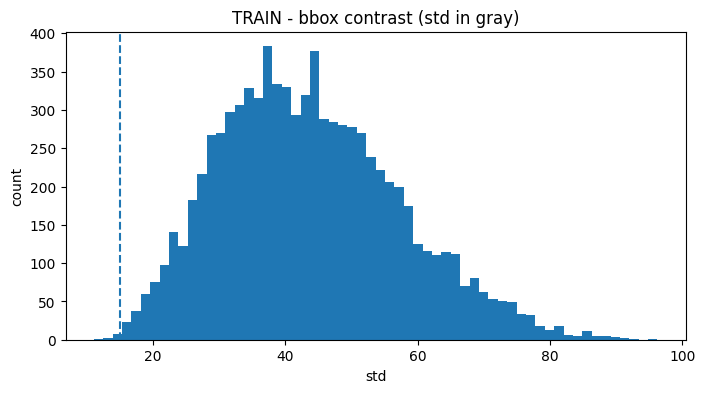

[TRAIN] examples (removed boxes)


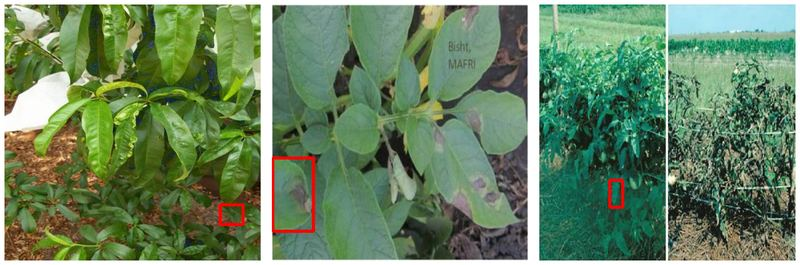

[TRAIN] removed images with no boxes: 0
[TRAIN] saved csv: /kaggle/working/train/train_annotations_clean.csv

[TEST] boxes before: 454
[TEST] low contrast (<15): 0
[TEST] boxes after: 454


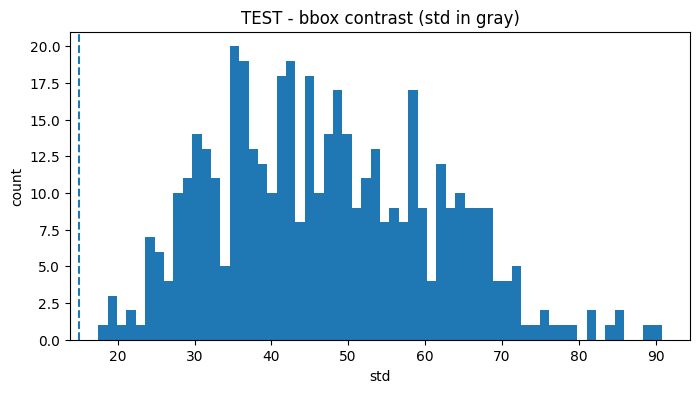

[TEST] examples (removed boxes)
No examples to show.
[TEST] removed images with no boxes: 0
[TEST] saved csv: /kaggle/working/test/test_annotations_clean.csv


In [59]:
# low contrast
CONTRAST_STD_THR = 15
N_EXAMPLES = 3

TRAIN_CSV_PATH = "/kaggle/working/train/train_annotations_clean.csv"
TRAIN_IMG_DIR  = "/kaggle/working/train/images"
TRAIN_OVERWRITE_CSV = True
TRAIN_DF = train_annotation_df

TEST_CSV_PATH = "/kaggle/working/test/test_annotations_clean.csv"
TEST_IMG_DIR  = "/kaggle/working/test/images"
TEST_OVERWRITE_CSV = True
TEST_DF = test_annotation_df


def resolve_path(img_dir, name):
    name = str(name)
    if os.path.isabs(name) or name.startswith("/"):
        return name
    return os.path.join(img_dir, name)


def show_examples(df_subset, img_dir, n=3):
    #  show full image + the bbox
    if df_subset.empty:
        print("No examples to show.")
        return

    ex = df_subset.head(n)
    plt.figure(figsize=(6 * len(ex), 6))

    for i, (_, r) in enumerate(ex.iterrows(), 1):
        img = cv2.imread(resolve_path(img_dir, r["filename"]))
        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]

        x1 = int(max(0, min(W - 1, r["xmin"])))
        y1 = int(max(0, min(H - 1, r["ymin"])))
        x2 = int(max(0, min(W - 1, r["xmax"])))
        y2 = int(max(0, min(H - 1, r["ymax"])))
        if x2 <= x1 or y2 <= y1:
            continue

        vis = img.copy()
        cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 0, 0), 3)

        plt.subplot(1, len(ex), i)
        plt.imshow(vis)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


def run_contrast_filter(df, img_dir, csv_path, overwrite_csv=True, split_name=""):
    ann = df.copy()

    # keep same index so we don't get out-of-bounds errors
    cvals = pd.Series(np.nan, index=ann.index, dtype="float32")
    ok = pd.Series(False, index=ann.index)

    # read each image once, then loop its boxes
    for fname, g in ann.groupby("filename"):
        img = cv2.imread(resolve_path(img_dir, fname))
        if img is None:
            continue

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        H, W = gray.shape

        for idx, r in g.iterrows():
            x1 = int(max(0, min(W - 1, r["xmin"])))
            y1 = int(max(0, min(H - 1, r["ymin"])))
            x2 = int(max(0, min(W - 1, r["xmax"])))
            y2 = int(max(0, min(H - 1, r["ymax"])))
            if x2 <= x1 or y2 <= y1:
                continue

            crop = gray[y1:y2, x1:x2]
            if crop.size == 0:
                continue

            cvals.loc[idx] = float(crop.std())
            ok.loc[idx] = True

    ann["bbox_contrast"] = cvals
    ann["_ok"] = ok

    valid = ann["_ok"] & ann["bbox_contrast"].notna()
    low_mask = valid & (ann["bbox_contrast"] < CONTRAST_STD_THR)

    kept_df = ann[~low_mask].copy()
    removed_df = ann[low_mask].copy()

    print(f"\n[{split_name}] boxes before: {len(ann)}")
    print(f"[{split_name}] low contrast (<{CONTRAST_STD_THR}): {int(low_mask.sum())}")
    print(f"[{split_name}] boxes after: {len(kept_df)}")

    # histogram to see how the contrast values are spread
    vals = ann.loc[valid, "bbox_contrast"].values
    plt.figure(figsize=(8, 4))
    plt.hist(vals, bins=60)
    plt.axvline(CONTRAST_STD_THR, linestyle="--")
    plt.title(f"{split_name} - bbox contrast (std in gray)")
    plt.xlabel("std")
    plt.ylabel("count")
    plt.show()

    print(f"[{split_name}] examples (removed boxes)")
    show_examples(removed_df, img_dir, n=N_EXAMPLES)

    # delete images that ended up with no boxes
    orig_imgs = set(df["filename"].dropna().astype(str).unique())
    kept_imgs = set(kept_df["filename"].dropna().astype(str).unique())
    to_delete = orig_imgs - kept_imgs

    deleted = 0
    for name in to_delete:
        p = resolve_path(img_dir, name)
        if os.path.exists(p):
            os.remove(p)
            deleted += 1

    print(f"[{split_name}] removed images with no boxes: {deleted}")

    out_path = csv_path if overwrite_csv else csv_path.replace(".csv", "_contrast_filtered.csv")
    kept_df.drop(columns=["bbox_contrast", "_ok"], errors="ignore").to_csv(out_path, index=False)
    print(f"[{split_name}] saved csv: {out_path}")

    return kept_df.drop(columns=["bbox_contrast", "_ok"], errors="ignore").copy()


train_annotation_df = run_contrast_filter(
    TRAIN_DF, TRAIN_IMG_DIR, TRAIN_CSV_PATH,
    overwrite_csv=TRAIN_OVERWRITE_CSV,
    split_name="TRAIN"
)

test_annotation_df = run_contrast_filter(
    TEST_DF, TEST_IMG_DIR, TEST_CSV_PATH,
    overwrite_csv=TEST_OVERWRITE_CSV,
    split_name="TEST"
)


## **Handling sharpness**


[TRAIN] boxes before: 8319
[TRAIN] very blurry (<20): 2
[TRAIN] boxes after: 8317


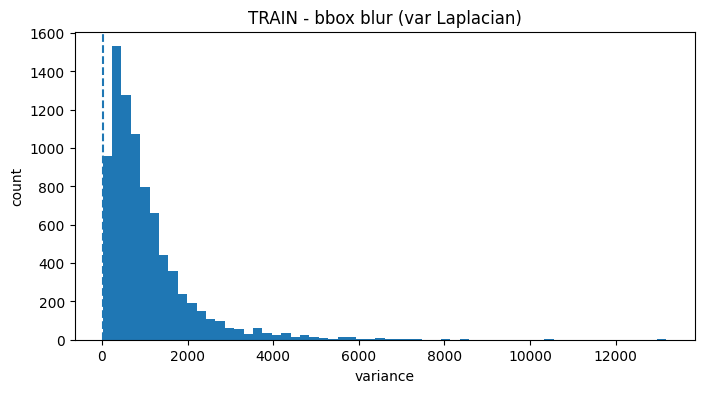

[TRAIN] examples (removed boxes)


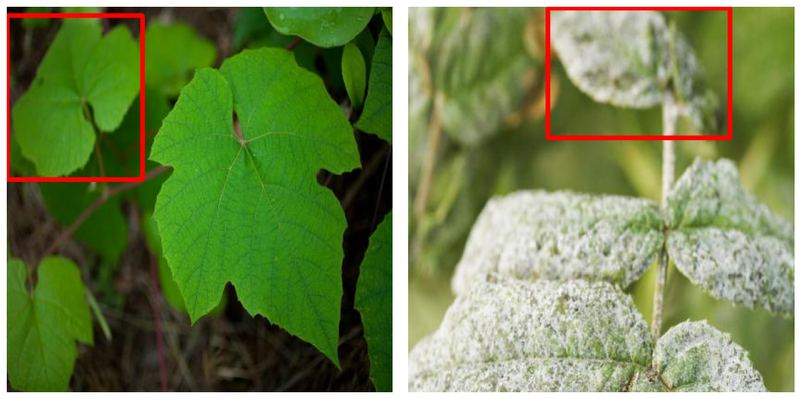

[TRAIN] removed images with no boxes: 0
[TRAIN] saved csv: /kaggle/working/train/train_annotations_clean.csv

[TEST] boxes before: 454
[TEST] very blurry (<20): 0
[TEST] boxes after: 454


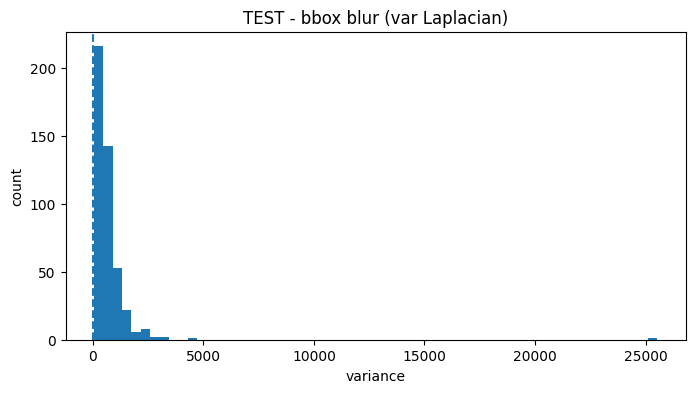

[TEST] examples (removed boxes)
No examples to show.
[TEST] removed images with no boxes: 0
[TEST] saved csv: /kaggle/working/test/test_annotations_clean.csv


In [60]:
# variance of Laplacian lower = blurrier
BLUR_VAR_THR = 20
N_EXAMPLES = 4

TRAIN_CSV_PATH = "/kaggle/working/train/train_annotations_clean.csv"
TRAIN_IMG_DIR  = "/kaggle/working/train/images"
TRAIN_OVERWRITE_CSV = True
TRAIN_DF = train_annotation_df

TEST_CSV_PATH = "/kaggle/working/test/test_annotations_clean.csv"
TEST_IMG_DIR  = "/kaggle/working/test/images"
TEST_OVERWRITE_CSV = True
TEST_DF = test_annotation_df


def resolve_path(img_dir, name):
    name = str(name)
    if os.path.isabs(name) or name.startswith("/"):
        return name
    return os.path.join(img_dir, name)


def show_examples(df_subset, img_dir, n=4):
    # show the image with the bbox
    if df_subset.empty:
        print("No examples to show.")
        return

    ex = df_subset.head(n)
    plt.figure(figsize=(6 * len(ex), 6))

    for i, (_, r) in enumerate(ex.iterrows(), 1):
        img = cv2.imread(resolve_path(img_dir, r["filename"]))
        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]

        x1 = int(max(0, min(W - 1, r["xmin"])))
        y1 = int(max(0, min(H - 1, r["ymin"])))
        x2 = int(max(0, min(W - 1, r["xmax"])))
        y2 = int(max(0, min(H - 1, r["ymax"])))
        if x2 <= x1 or y2 <= y1:
            continue

        vis = img.copy()
        cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 0, 0), 3)

        plt.subplot(1, len(ex), i)
        plt.imshow(vis)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


def run_blur_filter(df, img_dir, csv_path, overwrite_csv=True, split_name=""):
    ann = df.copy()

    bvals = pd.Series(np.nan, index=ann.index, dtype="float32")
    ok = pd.Series(False, index=ann.index)

    # load each image once, then handle its boxes
    for fname, g in ann.groupby("filename"):
        img = cv2.imread(resolve_path(img_dir, fname))
        if img is None:
            continue

        gray_full = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        H, W = gray_full.shape

        for idx, r in g.iterrows():
            x1 = int(max(0, min(W - 1, r["xmin"])))
            y1 = int(max(0, min(H - 1, r["ymin"])))
            x2 = int(max(0, min(W - 1, r["xmax"])))
            y2 = int(max(0, min(H - 1, r["ymax"])))
            if x2 <= x1 or y2 <= y1:
                continue

            crop = gray_full[y1:y2, x1:x2]
            # tiny crops give noisy blur values and skip them
            if crop.size == 0 or crop.shape[0] < 8 or crop.shape[1] < 8:
                continue

            bvals.loc[idx] = float(cv2.Laplacian(crop, cv2.CV_64F).var())
            ok.loc[idx] = True

    ann["bbox_blur"] = bvals
    ann["_ok"] = ok

    valid = ann["_ok"] & ann["bbox_blur"].notna()
    blurry_mask = valid & (ann["bbox_blur"] < BLUR_VAR_THR)

    kept_df = ann[~blurry_mask].copy()
    removed_df = ann[blurry_mask].copy()

    print(f"\n[{split_name}] boxes before: {len(ann)}")
    print(f"[{split_name}] very blurry (<{BLUR_VAR_THR}): {int(blurry_mask.sum())}")
    print(f"[{split_name}] boxes after: {len(kept_df)}")

    vals = ann.loc[valid, "bbox_blur"].values
    plt.figure(figsize=(8, 4))
    plt.hist(vals, bins=60)
    plt.axvline(BLUR_VAR_THR, linestyle="--")
    plt.title(f"{split_name} - bbox blur (var Laplacian)")
    plt.xlabel("variance")
    plt.ylabel("count")
    plt.show()

    print(f"[{split_name}] examples (removed boxes)")
    show_examples(removed_df, img_dir, n=N_EXAMPLES)

    # remove images that ended up with 0 boxes
    orig_imgs = set(df["filename"].dropna().astype(str).unique())
    kept_imgs = set(kept_df["filename"].dropna().astype(str).unique())
    to_delete = orig_imgs - kept_imgs

    deleted = 0
    for name in to_delete:
        p = resolve_path(img_dir, name)
        if os.path.exists(p):
            os.remove(p)
            deleted += 1

    print(f"[{split_name}] removed images with no boxes: {deleted}")

    out_path = csv_path if overwrite_csv else csv_path.replace(".csv", "_blur_filtered.csv")
    kept_df.drop(columns=["bbox_blur", "_ok"], errors="ignore").to_csv(out_path, index=False)
    print(f"[{split_name}] saved csv: {out_path}")

    return kept_df.drop(columns=["bbox_blur", "_ok"], errors="ignore").copy()


train_annotation_df = run_blur_filter(
    TRAIN_DF, TRAIN_IMG_DIR, TRAIN_CSV_PATH,
    overwrite_csv=TRAIN_OVERWRITE_CSV,
    split_name="TRAIN"
)

test_annotation_df = run_blur_filter(
    TEST_DF, TEST_IMG_DIR, TEST_CSV_PATH,
    overwrite_csv=TEST_OVERWRITE_CSV,
    split_name="TEST"
)


**Applying CLAHE on low contrast imgaes on both train and test set**

TRAIN: checking contrast: 100%|██████████| 2318/2318 [00:04<00:00, 533.33it/s]



TRAIN: images in csv: 2318
TRAIN: scored: 2318 | unreadable: 0
TRAIN: std < 40: 484


TEST: checking contrast: 100%|██████████| 238/238 [00:00<00:00, 535.44it/s]



TEST: images in csv: 238
TEST: scored: 238 | unreadable: 0
TEST: std < 40: 44


TEST: applying CLAHE: 100%|██████████| 44/44 [00:00<00:00, 123.80it/s]



train updated: 484
test updated: 44


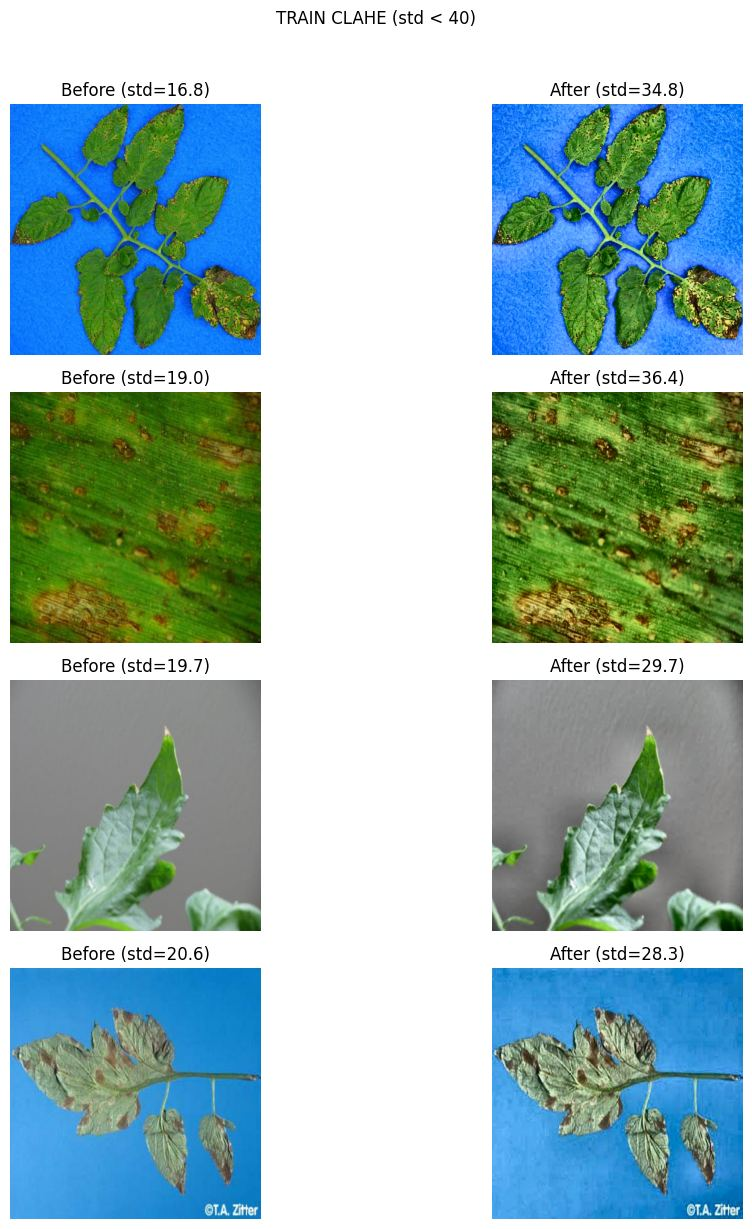

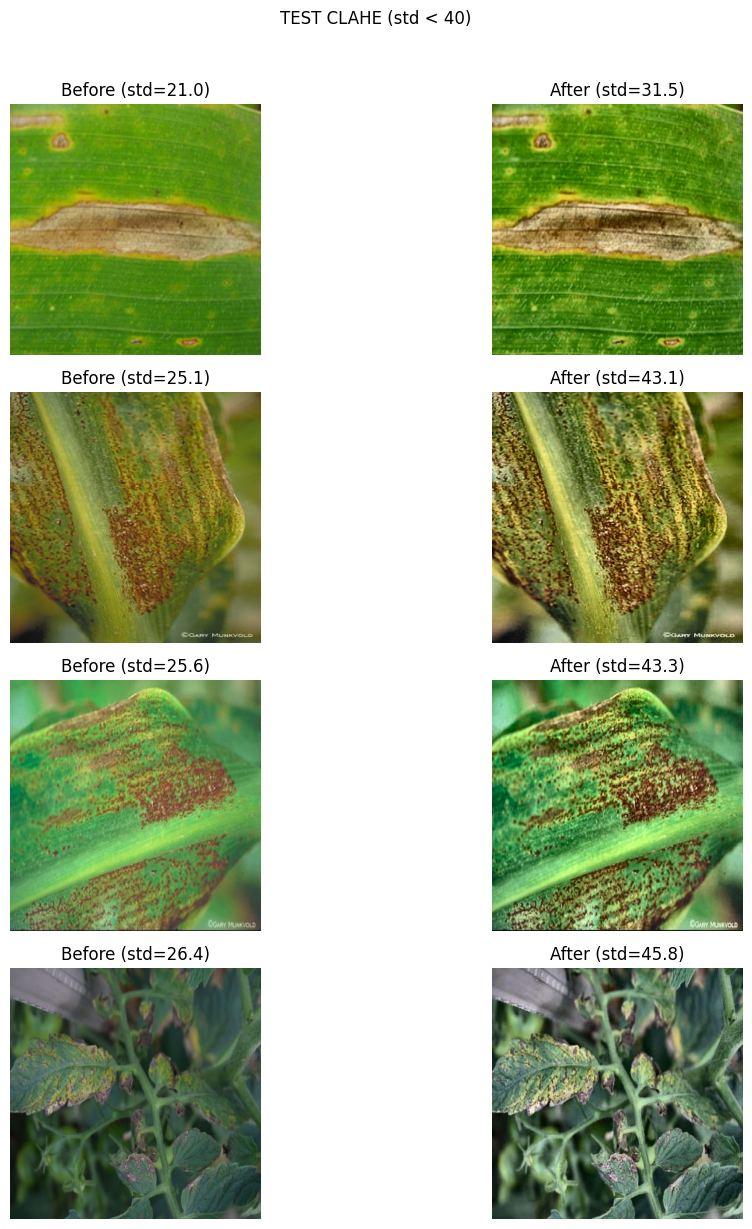


Saved csv files


In [61]:
# if an image is low contrast boost it with CLAHE
CONTRAST_STD_THR = 40
CLIP_LIMIT = 2.0
TILE_GRID = (8, 8)

TRAIN_DF = train_annotation_df
TRAIN_CSV_PATH = "/kaggle/working/train/train_annotations_clean.csv"
TRAIN_IMG_DIR = "/kaggle/working/train/images"

TEST_DF = test_annotation_df
TEST_CSV_PATH = "/kaggle/working/test/test_annotations_clean.csv"
TEST_IMG_DIR = "/kaggle/working/test/images"

OVERWRITE_CSV = True


def find_fname_col(df):
    for c in ["filename", "image", "image_name", "file", "path"]:
        if c in df.columns:
            return c
    raise ValueError("filename column not found")


def resolve_path(img_dir, ref):
    s = str(ref)
    return s if (os.path.isabs(s) or s.startswith("/")) else os.path.join(img_dir, s)


def gray_std(bgr):
    return float(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).std())


def apply_clahe(bgr):
    # do CLAHE only on the L channel in LAB (keeps colors more stable)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=CLIP_LIMIT, tileGridSize=TILE_GRID)
    l2 = clahe.apply(l)
    out = cv2.merge([l2, a, b])
    return cv2.cvtColor(out, cv2.COLOR_LAB2BGR)


def run_inplace_clahe(df, img_dir, tag="TRAIN", n_viz=4):
    fc = find_fname_col(df)
    refs = df[fc].dropna().astype(str).unique().tolist()

    scored = []
    unreadable = 0

    # first pass measure contrast for each image once
    for ref in tqdm(refs, desc=f"{tag}: checking contrast"):
        p = resolve_path(img_dir, ref)
        bgr = cv2.imread(p)
        if bgr is None:
            unreadable += 1
            continue
        scored.append((gray_std(bgr), ref, p))

    if not scored:
        print(f"{tag}: no readable images")
        return df, 0, []

    # pick images under threshold
    to_fix = [(s, ref, p) for (s, ref, p) in scored if s < CONTRAST_STD_THR]
    to_fix.sort(key=lambda x: x[0])

    print(f"\n{tag}: images in csv: {len(refs)}")
    print(f"{tag}: scored: {len(scored)} | unreadable: {unreadable}")
    print(f"{tag}: std < {CONTRAST_STD_THR}: {len(to_fix)}")

    viz = []
    updated = 0

    # second pass apply CLAHE and overwrite the same file
    for _, ref, p in tqdm(to_fix, desc=f"{tag}: applying CLAHE"):
        bgr = cv2.imread(p)
        if bgr is None:
            continue

        before_std = gray_std(bgr)
        out = apply_clahe(bgr)
        after_std = gray_std(out)

        if len(viz) < n_viz:
            bef_rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            aft_rgb = cv2.cvtColor(out, cv2.COLOR_BGR2RGB)
            viz.append((bef_rgb, aft_rgb, before_std, after_std))

        if cv2.imwrite(p, out):
            updated += 1

    return df, updated, viz


def show_before_after(viz, title):
    if not viz:
        print("No examples to show.")
        return

    n = len(viz)
    plt.figure(figsize=(12, 3 * n))

    for i, (bef, aft, s1, s2) in enumerate(viz, start=1):
        plt.subplot(n, 2, 2 * i - 1)
        plt.imshow(bef)
        plt.axis("off")
        plt.title(f"Before (std={s1:.1f})")

        plt.subplot(n, 2, 2 * i)
        plt.imshow(aft)
        plt.axis("off")
        plt.title(f"After (std={s2:.1f})")

    plt.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


train_df_out, train_updated, train_viz = run_inplace_clahe(TRAIN_DF, TRAIN_IMG_DIR, tag="TRAIN", n_viz=4)
test_df_out,  test_updated,  test_viz  = run_inplace_clahe(TEST_DF,  TEST_IMG_DIR,  tag="TEST",  n_viz=4)

print(f"\ntrain updated: {train_updated}")
print(f"test updated: {test_updated}")

show_before_after(train_viz, f"TRAIN CLAHE (std < {CONTRAST_STD_THR})")
show_before_after(test_viz,  f"TEST CLAHE (std < {CONTRAST_STD_THR})")

if OVERWRITE_CSV:
    train_df_out.to_csv(TRAIN_CSV_PATH, index=False)
    test_df_out.to_csv(TEST_CSV_PATH, index=False)
    print("\nSaved csv files")

train_annotation_df = train_df_out.copy()
test_annotation_df = test_df_out.copy()


## **Spliting 0.1 percent of training data to making validation set**

In [62]:
df = train_annotation_df

# One row per image: pick a representative class per image
per_image = (
    df.groupby('filename')['class']
      .agg(lambda s: s.mode().iat[0])
      .reset_index()
)

# Split image names into train/val
train_names, val_names = train_test_split(
    per_image['filename'],
    test_size=0.1,
    shuffle=True,
    random_state=42,
    stratify=per_image['class']
)

# Filter the original CSV rows by image names
train_df = df[df['filename'].isin(train_names)]
val_df   = df[df['filename'].isin(val_names)]


SAVE_train = Path('/kaggle/working/train/')
SAVE_train.mkdir(parents=True, exist_ok=True)

SAVE_val = Path('/kaggle/working/val/')
SAVE_val.mkdir(parents=True, exist_ok=True)

# Save split CSVs
train_df.to_csv(SAVE_train / "train_annotations_split.csv", index=False)
val_df.to_csv(SAVE_val / "val_annotations.csv", index=False)

print(f"Saved {len(train_df)} rows to {SAVE_train / 'train_annotations_split.csv'}")
print(f"Saved {len(val_df)} rows to {SAVE_val / 'val_annotations.csv'}")

train_annotation_df = train_df.copy()

Saved 7396 rows to /kaggle/working/train/train_annotations_split.csv
Saved 921 rows to /kaggle/working/val/val_annotations.csv


**Displaying number of images in validation set**

In [63]:
val_annotations_path = '/kaggle/working/val/val_annotations.csv'
val_df = pd.read_csv(val_annotations_path)
unique_filenames = val_df['filename'].unique()
num_unique_images = len(unique_filenames)

print(f"Total number of unique images based on {val_annotations_path}: {num_unique_images}")


Total number of unique images based on /kaggle/working/val/val_annotations.csv: 232


**Displaying number of bounding boxes of validation set**

In [64]:
val_annotations_path = '/kaggle/working/val/val_annotations.csv'
val_df = pd.read_csv(val_annotations_path)
unique_filenames = val_df['filename']
num_unique_images = len(unique_filenames)

print(f"Total number of unique bounding boxes based on {val_annotations_path}: {num_unique_images}")

Total number of unique bounding boxes based on /kaggle/working/val/val_annotations.csv: 921


**Moving separated images to validation folder**

In [65]:
source_dir = "/kaggle/working/train/images"
dest_dir = "/kaggle/working/val/images"
os.makedirs(dest_dir, exist_ok=True)

val_df = pd.read_csv("/kaggle/working/val/val_annotations.csv")
image_filenames = val_df["filename"].dropna().astype(str).unique()

moved = 0
missing = 0

for filename in image_filenames:
    src = os.path.join(source_dir, filename)
    dst = os.path.join(dest_dir, filename)

    if os.path.isfile(src):
        shutil.copy(src, dst)
        os.remove(src)
        moved += 1
    else:
        missing += 1

print(f"Moved {moved} images to val/images")
print(f"Missing in train/images: {missing}")


Moved 232 images to val/images
Missing in train/images: 0


**Checking number of images ofter transfering**

In [66]:
train_images_dir = '/kaggle/working/val/images'
image_files = [f for f in os.listdir(train_images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
num_images = len(image_files)

print(f"Total number of images in {train_images_dir}: {num_images}")

Total number of images in /kaggle/working/val/images: 232


In [67]:
train_images_dir = '/kaggle/working/train/images'
image_files = [f for f in os.listdir(train_images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
num_images = len(image_files)

print(f"Total number of images in {train_images_dir}: {num_images}")


Total number of images in /kaggle/working/train/images: 2086


## **Augmentation**

Before: rows=7396, images=2086, aug_images=0


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_99/4235525031.py:41: UserWarning: Argument(s) 'value' are not valid for transform ShiftScaleRotate
  A.ShiftScaleRotate(
/tmp/ipykernel_99/4235525031.py:50: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 20.0), p=0.18),


Target boxes per class: 489 (max=700)
Rare classes: 24



After upsampling
created aug images: 2647
added bbox rows: 6369
rows=13765, images=4733, total_aug_images=2647
saved csv: /kaggle/working/train/train_annotations_split2.csv
Most upsampled class: Corn Gray leaf spot


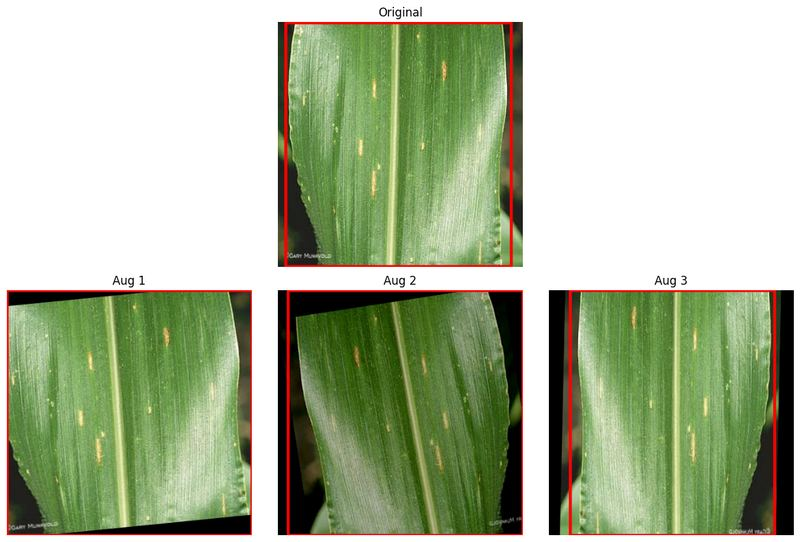

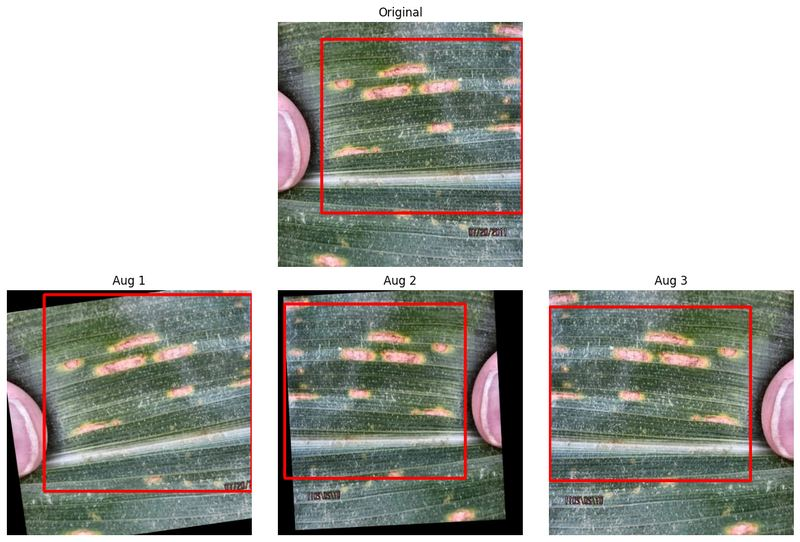

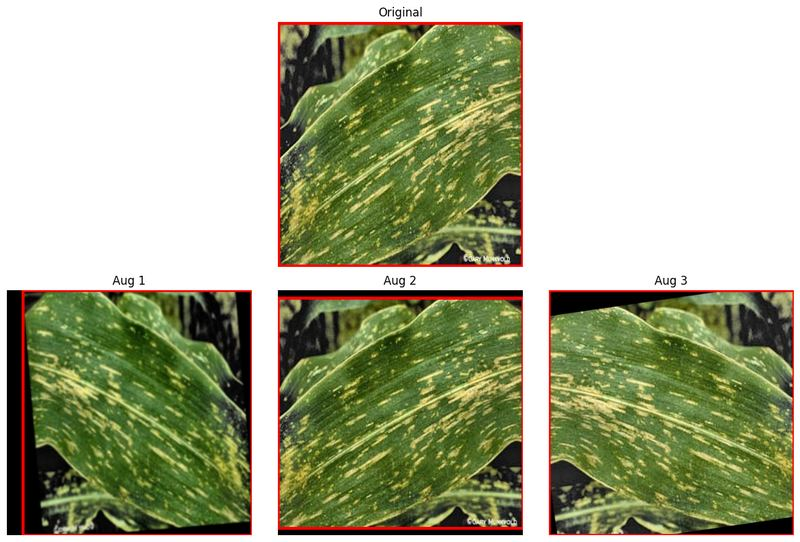

In [68]:
train_img_dir  = "/kaggle/working/train/images"
train_csv_path = "/kaggle/working/train/train_annotations_split.csv"
out_csv_path   = "/kaggle/working/train/train_annotations_split2.csv"

target_ratio = 0.7
max_per_class_aug_images = 5000
max_tries_per_image = 25

df = pd.read_csv(train_csv_path)

needed = {"filename", "xmin", "ymin", "xmax", "ymax", "class"}
missing = needed - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")


if "width" not in df.columns:
    df["width"] = np.nan
if "height" not in df.columns:
    df["height"] = np.nan

# remove exact duplicate labels
key_cols = ["filename", "class", "xmin", "ymin", "xmax", "ymax"]
df = df.drop_duplicates(subset=key_cols).reset_index(drop=True)

def is_augmented_filename(fname):
    s = str(fname)
    return "__aug_" in s or s.startswith("aug_")

before_rows = len(df)
before_imgs = df["filename"].nunique()
before_aug_imgs = df[df["filename"].astype(str).apply(is_augmented_filename)]["filename"].nunique()

print(f"Before: rows={before_rows}, images={before_imgs}, aug_images={before_aug_imgs}")

# simple augmentations
transform = A.Compose(
    [
        A.HorizontalFlip(p=0.5),

        A.ShiftScaleRotate(
            shift_limit=0.05, scale_limit=0.15, rotate_limit=10,
            border_mode=cv2.BORDER_CONSTANT, value=0, p=0.75
        ),

        A.RandomBrightnessContrast(brightness_limit=0.20, contrast_limit=0.20, p=0.45),
        A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=18, val_shift_limit=12, p=0.30),

        A.RandomGamma(gamma_limit=(85, 115), p=0.25),
        A.GaussNoise(var_limit=(5.0, 20.0), p=0.18),
        A.GaussianBlur(blur_limit=(3, 5), p=0.12),
    ],
    bbox_params=A.BboxParams(
        format="pascal_voc",
        label_fields=["class_labels"],
        min_visibility=0.35
    )
)

def safe_int(x, default=0):
    try:
        return int(float(x))
    except:
        return default

def clamp_box(x1, y1, x2, y2, w, h):
    x1 = int(max(0, min(x1, w - 1)))
    y1 = int(max(0, min(y1, h - 1)))
    x2 = int(max(0, min(x2, w)))
    y2 = int(max(0, min(y2, h)))
    if x2 <= x1 or y2 <= y1:
        return None
    return x1, y1, x2, y2

def safe_label_for_filename(label):
    return re.sub(r"[^A-Za-z0-9_]+", "_", str(label)).strip("_")

def draw_boxes(img_bgr, rows, color=(0, 0, 255), thickness=3):
    out = img_bgr.copy()
    for _, r in rows.iterrows():
        x1 = safe_int(r["xmin"]); y1 = safe_int(r["ymin"])
        x2 = safe_int(r["xmax"]); y2 = safe_int(r["ymax"])
        cv2.rectangle(out, (x1, y1), (x2, y2), color, thickness)
    return out

# group by image
by_image = df.groupby("filename", sort=False)
base_filenames = [fn for fn in by_image.groups.keys() if not is_augmented_filename(fn)]
df_base = df[df["filename"].isin(base_filenames)].copy()
by_image_base = df_base.groupby("filename", sort=False)

# list of source images that contain it
class_to_files = {}
for fname, g in by_image_base:
    for c in set(g["class"].tolist()):
        class_to_files.setdefault(c, []).append(fname)

# counts are based on bbox rows
class_counts = df["class"].value_counts().to_dict()
max_count = int(max(class_counts.values())) if class_counts else 0
target_boxes = int(target_ratio * max_count)

rare_classes = [c for c, cnt in class_counts.items() if cnt < target_boxes]
print(f"Target boxes per class: {target_boxes} (max={max_count})")
print(f"Rare classes: {len(rare_classes)}")

# start aug counter from existing aug images
existing_aug = [
    f for f in os.listdir(train_img_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png")) and is_augmented_filename(f)
]
aug_counter = len(existing_aug)

new_rows = []
aug_images_created = 0
aug_rows_created = 0
aug_images_per_class = {}
source_to_aug_for_cls = {}

for cls in rare_classes:
    candidates = class_to_files.get(cls, [])
    if not candidates:
        continue

    created_for_cls = 0
    safe_cls = safe_label_for_filename(cls)
    need = target_boxes - int(class_counts.get(cls, 0))

    pbar = tqdm(total=max(0, need), desc=f"Upsampling {cls}", leave=False)

    while int(class_counts.get(cls, 0)) < target_boxes and created_for_cls < max_per_class_aug_images:
        source_fname = candidates[created_for_cls % len(candidates)]
        img_path = os.path.join(train_img_dir, source_fname)

        img = cv2.imread(img_path)
        if img is None:
            created_for_cls += 1
            continue

        g = by_image_base.get_group(source_fname)

        bboxes, labels = [], []
        for _, r in g.iterrows():
            bboxes.append([safe_int(r["xmin"]), safe_int(r["ymin"]), safe_int(r["xmax"]), safe_int(r["ymax"])])
            labels.append(r["class"])

        ok = False
        out_img, out_boxes, out_labels = None, None, None


        for _ in range(max_tries_per_image):
            out = transform(image=img, bboxes=bboxes, class_labels=labels)
            if len(out["bboxes"]) == 0:
                continue
            if cls not in out["class_labels"]:
                continue
            out_img = out["image"]
            out_boxes = out["bboxes"]
            out_labels = out["class_labels"]
            ok = True
            break

        if not ok:
            created_for_cls += 1
            continue

        ext = Path(source_fname).suffix or ".jpg"
        base_stem = Path(source_fname).stem[:24]

        new_fname = f"{base_stem}__aug_{safe_cls}_{aug_counter:06d}{ext}"
        new_path = os.path.join(train_img_dir, new_fname)
        while os.path.exists(new_path):
            aug_counter += 1
            new_fname = f"{base_stem}__aug_{safe_cls}_{aug_counter:06d}{ext}"
            new_path = os.path.join(train_img_dir, new_fname)

        cv2.imwrite(new_path, out_img)

        aug_images_created += 1
        aug_images_per_class[cls] = aug_images_per_class.get(cls, 0) + 1
        source_to_aug_for_cls.setdefault(cls, {}).setdefault(source_fname, []).append(new_fname)

        H_img, W_img = out_img.shape[:2]

        # avoid duplicated boxes inside the same augmented image
        seen = set()
        added_target = 0

        for (x1, y1, x2, y2), lab in zip(out_boxes, out_labels):
            clamped = clamp_box(x1, y1, x2, y2, W_img, H_img)
            if clamped is None:
                continue

            x1c, y1c, x2c, y2c = clamped
            key = (lab, x1c, y1c, x2c, y2c)
            if key in seen:
                continue
            seen.add(key)

            new_rows.append({
                "filename": new_fname,
                "width": W_img,
                "height": H_img,
                "xmin": x1c, "ymin": y1c, "xmax": x2c, "ymax": y2c,
                "class": lab
            })

            aug_rows_created += 1
            class_counts[lab] = int(class_counts.get(lab, 0)) + 1

            # update progress mainly based on the target class
            if lab == cls and int(class_counts.get(cls, 0)) <= target_boxes:
                added_target += 1

        if added_target > 0:
            pbar.update(added_target)

        aug_counter += 1
        created_for_cls += 1

    pbar.close()

# combine old + new rows
if new_rows:
    df_aug = pd.DataFrame(new_rows)
    df_out = pd.concat([df, df_aug], ignore_index=True)
else:
    df_out = df.copy()

df_out = df_out.drop_duplicates(subset=key_cols).reset_index(drop=True)

# fill width/height if missing
need_fill = df_out["width"].isna() | df_out["height"].isna()
if need_fill.any():
    sizes = {}
    for fn in df_out.loc[need_fill, "filename"].dropna().astype(str).unique():
        p = os.path.join(train_img_dir, fn)
        im = cv2.imread(p)
        if im is not None:
            h, w = im.shape[:2]
            sizes[fn] = (w, h)

    df_out.loc[need_fill, "width"] = df_out.loc[need_fill, "filename"].map(
        lambda x: sizes.get(str(x), (np.nan, np.nan))[0]
    )
    df_out.loc[need_fill, "height"] = df_out.loc[need_fill, "filename"].map(
        lambda x: sizes.get(str(x), (np.nan, np.nan))[1]
    )

df_out.to_csv(out_csv_path, index=False)

after_rows = len(df_out)
after_imgs = df_out["filename"].nunique()
after_aug_imgs = df_out[df_out["filename"].astype(str).apply(is_augmented_filename)]["filename"].nunique()

print("\nAfter upsampling")
print(f"created aug images: {aug_images_created}")
print(f"added bbox rows: {aug_rows_created}")
print(f"rows={after_rows}, images={after_imgs}, total_aug_images={after_aug_imgs}")
print(f"saved csv: {out_csv_path}")

# pick the class that got augmented the most
if aug_images_per_class:
    top_cls = sorted(aug_images_per_class.items(), key=lambda x: (-x[1], str(x[0])))[0][0]
    print("Most upsampled class:", top_cls)

    src_map = source_to_aug_for_cls.get(top_cls, {})
    top_sources = sorted(src_map.items(), key=lambda kv: (-len(kv[1]), kv[0]))[:3]

    for src_fname, aug_list in top_sources:
        src_img = cv2.imread(os.path.join(train_img_dir, src_fname))
        if src_img is None:
            continue

        src_rows = df_base[df_base["filename"] == src_fname]
        src_vis = draw_boxes(src_img, src_rows)

        aug_list = aug_list[:3]
        aug_vis_list = []
        for af in aug_list:
            im = cv2.imread(os.path.join(train_img_dir, af))
            if im is None:
                continue
            aug_rows = df_out[df_out["filename"] == af]
            aug_vis_list.append(draw_boxes(im, aug_rows))

        cols = max(3, len(aug_vis_list))
        fig = plt.figure(figsize=(4 * cols, 8))
        gs = fig.add_gridspec(2, cols, height_ratios=[1, 1])

        ax0 = fig.add_subplot(gs[0, :])
        ax0.imshow(cv2.cvtColor(src_vis, cv2.COLOR_BGR2RGB))
        ax0.set_title("Original")
        ax0.axis("off")

        for i in range(cols):
            ax = fig.add_subplot(gs[1, i])
            ax.axis("off")
            if i < len(aug_vis_list):
                ax.imshow(cv2.cvtColor(aug_vis_list[i], cv2.COLOR_BGR2RGB))
                ax.set_title(f"Aug {i+1}")

        plt.tight_layout()
        plt.show()

train_annotation_df = df_out.copy()

## **Adding background**

In [69]:
# make empty .txt labels for background-only images
bg_dir = "/kaggle/working/Background"
labels_dir = "/kaggle/working/train/labels"
os.makedirs(labels_dir, exist_ok=True)

bg_imgs = [f for f in os.listdir(bg_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]

created = 0
skipped = 0

for fname in sorted(bg_imgs):
    stem = Path(fname).stem
    label_path = os.path.join(labels_dir, stem + ".txt")

    if os.path.exists(label_path):
        skipped += 1
        continue

    open(label_path, "w").close()
    created += 1

print("Background images:", len(bg_imgs))
print("Created empty labels:", created)
print("Skipped existing:", skipped)


Background images: 130
Created empty labels: 130
Skipped existing: 0


In [70]:
source_dir = "/kaggle/working/Background"
destination_dir = "/kaggle/working/train/images"

os.makedirs(destination_dir, exist_ok=True)

copied = 0
for filename in os.listdir(source_dir):
    if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    src = os.path.join(source_dir, filename)
    dst = os.path.join(destination_dir, filename)

    if os.path.isfile(src):
        shutil.copy(src, dst)
        copied += 1

print(f"Copied {copied} images from {source_dir} to {destination_dir}")


Copied 130 images from /kaggle/working/Background to /kaggle/working/train/images


## **Making function for converting CSV files to TXT files for YOLO**

In [71]:
import pandas as pd
from pathlib import Path
from urllib.parse import unquote
import re

def convert_csv_to_yolo(CSV_PATH, OUT_DIR):
    # fixed class order
    CLASSES = [
        "Apple Scab Leaf","Apple leaf","Apple rust leaf","Bell_pepper leaf","Bell_pepper leaf spot",
        "Blueberry leaf","Cherry leaf","Corn Gray leaf spot","Corn leaf blight","Corn rust leaf",
        "Peach leaf","Potato leaf early blight","Potato leaf late blight","Raspberry leaf","Soyabean leaf",
        "Squash Powdery mildew leaf","Strawberry leaf","Tomato Early blight leaf","Tomato Septoria leaf spot",
        "Tomato leaf","Tomato leaf bacterial spot","Tomato leaf late blight","Tomato leaf mosaic virus",
        "Tomato leaf yellow virus","Tomato mold leaf","grape leaf","grape leaf black rot"
    ]

    def norm(s):
        s = unquote(str(s)).strip()
        s = s.replace("_", " ")
        s = re.sub(r"\s+", " ", s)
        return s.lower()

    name2id = {norm(name): i for i, name in enumerate(CLASSES)}

    df = pd.read_csv(CSV_PATH)
    df.columns = [str(c).strip().lower() for c in df.columns]

    req = ["filename", "width", "height", "class", "xmin", "ymin", "xmax", "ymax"]
    miss = [c for c in req if c not in df.columns]
    if miss:
        raise ValueError(f"Missing columns in CSV: {miss}")

    df["__file"] = df["filename"].map(lambda x: Path(unquote(str(x))).name)
    df["__stem"] = df["__file"].map(lambda x: Path(x).stem)

    # check classes are all known
    unknown = sorted(set(norm(x) for x in df["class"]) - set(name2id.keys()))
    if unknown:
        raise ValueError("Unknown classes found:\n" + "\n".join(unknown))

    def row_to_line(r):
        W = float(r["width"])
        H = float(r["height"])

        xmin = float(r["xmin"]); ymin = float(r["ymin"])
        xmax = float(r["xmax"]); ymax = float(r["ymax"])

        # xyxy -> yolo (normalized)
        cx = ((xmin + xmax) / 2.0) / W
        cy = ((ymin + ymax) / 2.0) / H
        bw = (xmax - xmin) / W
        bh = (ymax - ymin) / H

        # keep in [0,1] so yolo doesn't complain
        def clip(v):
            return max(0.0, min(1.0, float(v)))

        cx, cy, bw, bh = map(clip, (cx, cy, bw, bh))

        cls_id = name2id[norm(r["class"])]
        return f"{cls_id} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}"

    out_dir = Path(OUT_DIR)
    out_dir.mkdir(parents=True, exist_ok=True)

    files_written = 0
    boxes_total = 0

    for stem, g in df.groupby("__stem"):
        lines = [row_to_line(r) for _, r in g.iterrows()]
        (out_dir / f"{stem}.txt").write_text("\n".join(lines), encoding="utf-8")
        files_written += 1
        boxes_total += len(lines)

    print(f"Done: wrote {files_written} txt files, total boxes: {boxes_total}")
    for i, name in enumerate(CLASSES):
        print(f"{i}: {name}")


**Converting train csv to txt**

In [72]:
convert_csv_to_yolo('/kaggle/working/train/train_annotations_split2.csv', '/kaggle/working/train/labels')

Done: wrote 4733 txt files, total boxes: 13765
0: Apple Scab Leaf
1: Apple leaf
2: Apple rust leaf
3: Bell_pepper leaf
4: Bell_pepper leaf spot
5: Blueberry leaf
6: Cherry leaf
7: Corn Gray leaf spot
8: Corn leaf blight
9: Corn rust leaf
10: Peach leaf
11: Potato leaf early blight
12: Potato leaf late blight
13: Raspberry leaf
14: Soyabean leaf
15: Squash Powdery mildew leaf
16: Strawberry leaf
17: Tomato Early blight leaf
18: Tomato Septoria leaf spot
19: Tomato leaf
20: Tomato leaf bacterial spot
21: Tomato leaf late blight
22: Tomato leaf mosaic virus
23: Tomato leaf yellow virus
24: Tomato mold leaf
25: grape leaf
26: grape leaf black rot


**Converting Validation csv to txt**

In [73]:
convert_csv_to_yolo('/kaggle/working/val/val_annotations.csv', '/kaggle/working/val/labels')

Done: wrote 232 txt files, total boxes: 921
0: Apple Scab Leaf
1: Apple leaf
2: Apple rust leaf
3: Bell_pepper leaf
4: Bell_pepper leaf spot
5: Blueberry leaf
6: Cherry leaf
7: Corn Gray leaf spot
8: Corn leaf blight
9: Corn rust leaf
10: Peach leaf
11: Potato leaf early blight
12: Potato leaf late blight
13: Raspberry leaf
14: Soyabean leaf
15: Squash Powdery mildew leaf
16: Strawberry leaf
17: Tomato Early blight leaf
18: Tomato Septoria leaf spot
19: Tomato leaf
20: Tomato leaf bacterial spot
21: Tomato leaf late blight
22: Tomato leaf mosaic virus
23: Tomato leaf yellow virus
24: Tomato mold leaf
25: grape leaf
26: grape leaf black rot


**Converting test csv to txt**

In [74]:
convert_csv_to_yolo('/kaggle/working/test/test_annotations_clean.csv', '/kaggle/working/test/labels')

Done: wrote 238 txt files, total boxes: 454
0: Apple Scab Leaf
1: Apple leaf
2: Apple rust leaf
3: Bell_pepper leaf
4: Bell_pepper leaf spot
5: Blueberry leaf
6: Cherry leaf
7: Corn Gray leaf spot
8: Corn leaf blight
9: Corn rust leaf
10: Peach leaf
11: Potato leaf early blight
12: Potato leaf late blight
13: Raspberry leaf
14: Soyabean leaf
15: Squash Powdery mildew leaf
16: Strawberry leaf
17: Tomato Early blight leaf
18: Tomato Septoria leaf spot
19: Tomato leaf
20: Tomato leaf bacterial spot
21: Tomato leaf late blight
22: Tomato leaf mosaic virus
23: Tomato leaf yellow virus
24: Tomato mold leaf
25: grape leaf
26: grape leaf black rot


## **Making data.yaml for YOLO**

In [75]:
# Defining the paths to your training and validation data
train_img_dir = '/kaggle/working/train/images'
val_img_dir = '/kaggle/working/val/images'
test_img_dir = '/kaggle/working/test/images'


# Defining the class names in the order they appear in your labels
classes = [
    'Apple Scab Leaf','Apple leaf','Apple rust leaf','Bell_pepper leaf','Bell_pepper leaf spot',
    'Blueberry leaf','Cherry leaf','Corn Gray leaf spot','Corn leaf blight','Corn rust leaf',
    'Peach leaf','Potato leaf early blight','Potato leaf late blight','Raspberry leaf','Soyabean leaf',
    'Squash Powdery mildew leaf','Strawberry leaf','Tomato Early blight leaf','Tomato Septoria leaf spot',
    'Tomato leaf','Tomato leaf bacterial spot','Tomato leaf late blight','Tomato leaf mosaic virus',
    'Tomato leaf yellow virus','Tomato mold leaf','grape leaf','grape leaf black rot'
]



# Create the data dictionary
data = {
    'train': train_img_dir,
    'val': val_img_dir,
    'test': test_img_dir,
    'nc': len(classes),
    'names': classes,
}

# Define the path to save the data.yaml file
data_yaml_path = '/kaggle/working/data.yaml'

# Write the data dictionary to the data.yaml file
with open(data_yaml_path, 'w') as f:
    yaml.dump(data, f)

print(f"data.yaml file created at: {data_yaml_path}")

data.yaml file created at: /kaggle/working/data.yaml


In [76]:
data_yaml = "/kaggle/working/data.yaml"

# **Modeling**

## **RUN 1**

In [77]:
# Load the YOLOv11n model weights
model = YOLO("yolo11n.pt")

In [78]:
# model info for displaying it layers and parameters
model.info()

YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.6 GFLOPs


(181, 2624080, 0, 6.614336)

In [79]:
# Train the model
results = model.train(

    optimizer="auto",
    data=data_yaml,
    epochs=40,
    imgsz=640,
    batch=32,
    workers=4,
    device=[0, 1],

    # augmentations
    fliplr=0.5,
    flipud=0,
    degrees=8.0,
    translate=0.1,
    scale=0.3,
    shear=0.0,
    perspective=0.0,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    mosaic=0.7,
    mixup=0.0,
    copy_paste=0.0,
    close_mosaic=0,

    # training setup
    cos_lr=True,
    patience=5,
    project="/kaggle/working/yolo_runs",
    name="plantdoc_yolo11n",
    exist_ok=False,
    save=True,
)

Ultralytics 8.4.13 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
                                                      CUDA:1 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=8.0, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.7, multi_scale=0.0, name=plantdoc_yolo11n, nbs=64, nms=False, opset

**Displaying results**

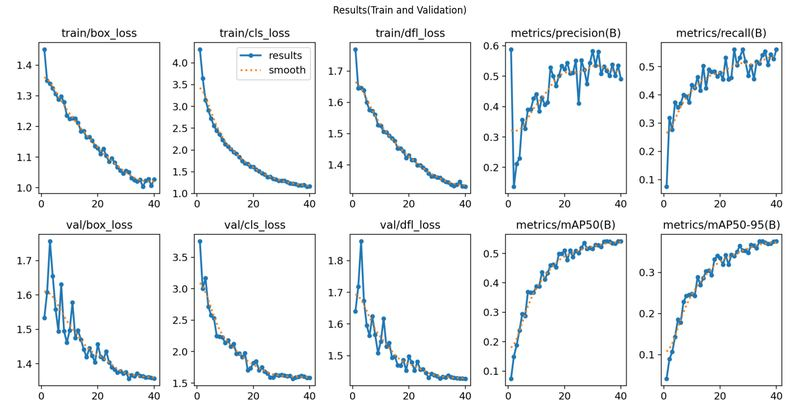

In [80]:
img_path = "/kaggle/working/yolo_runs/plantdoc_yolo11n/results.png"
img = Image.open(img_path)

plt.figure(figsize=(18, 18))
plt.imshow(img)
plt.axis("off")
plt.title("Results(Train and Validation)")
plt.show()

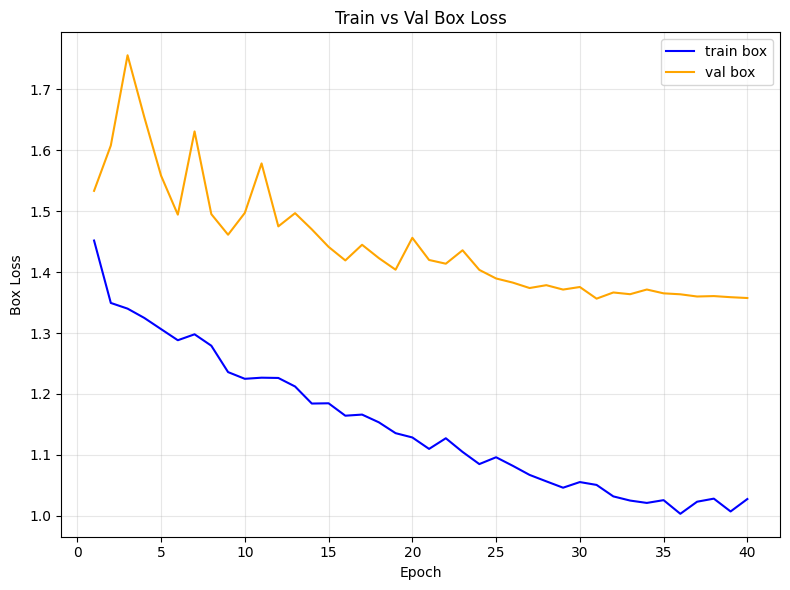

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n/train_vs_val_box_loss.png


In [81]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Train vs Val Box Loss
plt.figure(figsize=(8, 6))

# Plot train and val box loss
plt.plot(x, df["train/box_loss"], label="train box", color='blue')
plt.plot(x, df["val/box_loss"], label="val box", color='orange')

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("Box Loss")
plt.title("Train vs Val Box Loss")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "train_vs_val_box_loss.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


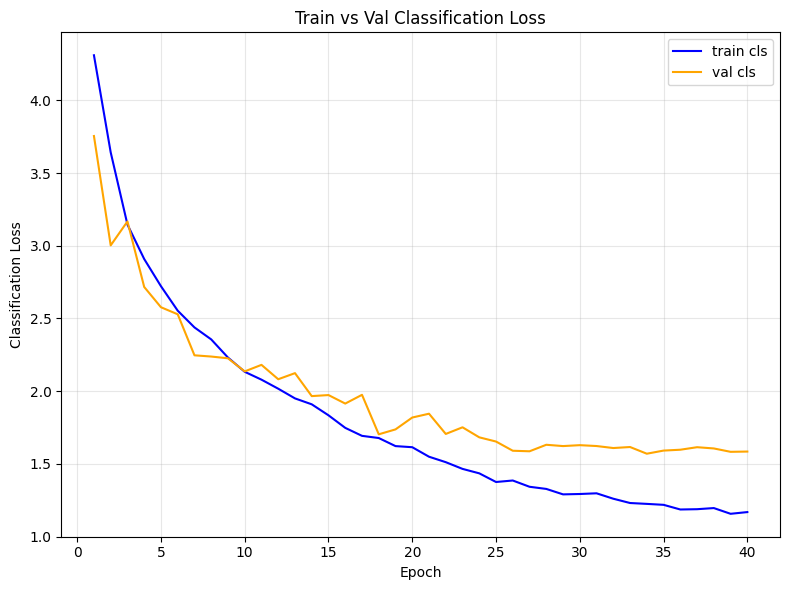

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n/train_vs_val_cls_loss.png


In [82]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Train vs Val Classification Loss
plt.figure(figsize=(8, 6))

# Plot train and val classification loss
plt.plot(x, df["train/cls_loss"], label="train cls", color='blue')
plt.plot(x, df["val/cls_loss"], label="val cls", color='orange')

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("Classification Loss")
plt.title("Train vs Val Classification Loss")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "train_vs_val_cls_loss.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


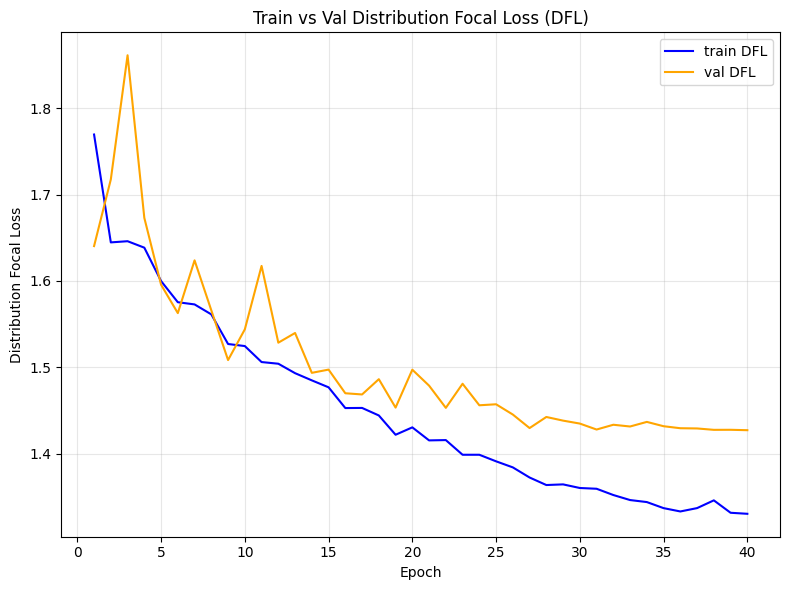

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n/train_vs_val_dfl_loss.png


In [83]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Train vs Val DFL Loss (Distribution Focal Loss)
plt.figure(figsize=(8, 6))

# Plot train and val DFL loss
plt.plot(x, df["train/dfl_loss"], label="train DFL", color='blue')
plt.plot(x, df["val/dfl_loss"], label="val DFL", color='orange')

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("Distribution Focal Loss")
plt.title("Train vs Val Distribution Focal Loss (DFL)")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "train_vs_val_dfl_loss.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


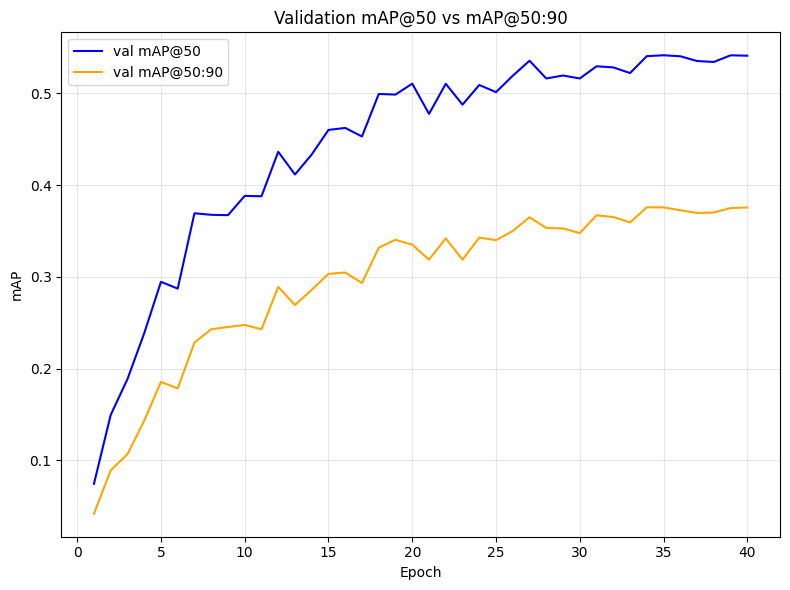

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n/val_mAP50_vs_mAP50_95.png


In [84]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n/")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Val mAP@50 and mAP@50:90
plt.figure(figsize=(8, 6))

# Plot val mAP@50 and val mAP@50:90 (use correct columns for val mAP)
plt.plot(x, df['metrics/mAP50(B)'], label="val mAP@50", color='blue')  # Validation mAP@50
plt.plot(x, df['metrics/mAP50-95(B)'], label="val mAP@50:90", color='orange')  # Validation mAP@50:95

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("Validation mAP@50 vs mAP@50:90")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "val_mAP50_vs_mAP50_95.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


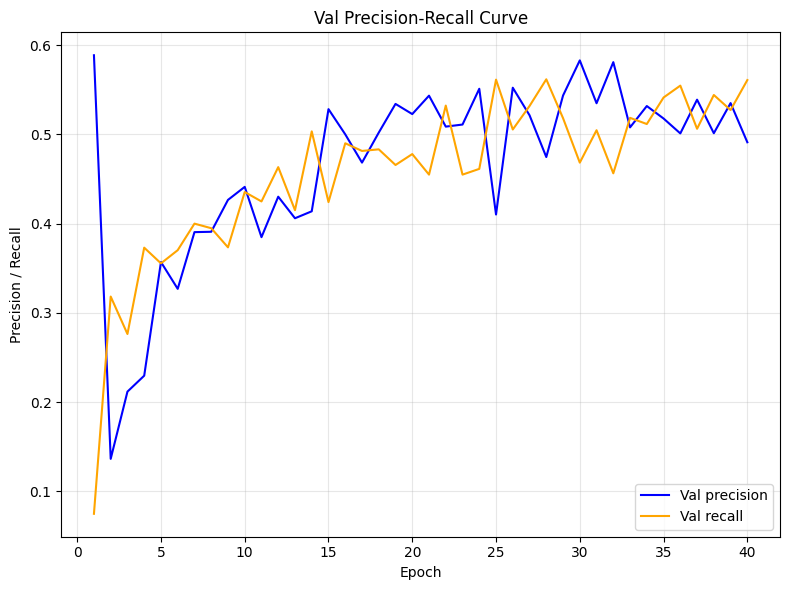

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n/train_vs_val_pr_curve.png


In [85]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n/")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Train Precision-Recall Curve
plt.figure(figsize=(8, 6))

# Plot train PR (Precision-Recall) curve
plt.plot(x, df["metrics/precision(B)"], label="Val precision", color='blue')
plt.plot(x, df["metrics/recall(B)"], label="Val recall", color='orange')

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("Precision / Recall")
plt.title("Val Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "train_vs_val_pr_curve.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


In [86]:
DATA = "/kaggle/working/data.yaml"
WEIGHTS = "/kaggle/working/yolo_runs/plantdoc_yolo11n/weights/best.pt"

model = YOLO(WEIGHTS)
metrics = model.val(
    data=DATA,
    split='test',
    imgsz=640,
    conf=0.25,
    iou=0.50,
    plots=True
)
print(metrics)

Ultralytics 8.4.13 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,587,417 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1435.8±420.2 MB/s, size: 54.7 KB)
val: Scanning /kaggle/working/test/labels... 238 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 238/238 1.4Kit/s 0.2s<0.2s
val: New cache created: /kaggle/working/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.7it/s 3.2s0.1s
                   all        238        454      0.558      0.572      0.587      0.481
       Apple Scab Leaf         10         13      0.583      0.538      0.574      0.507
            Apple leaf          9         10      0.658        0.7      0.735      0.568
       Apple rust leaf         10         11      0.526      0.606      0.581      0.484
      Bell_pepper leaf          8         11      0.384      0.545      0.541 

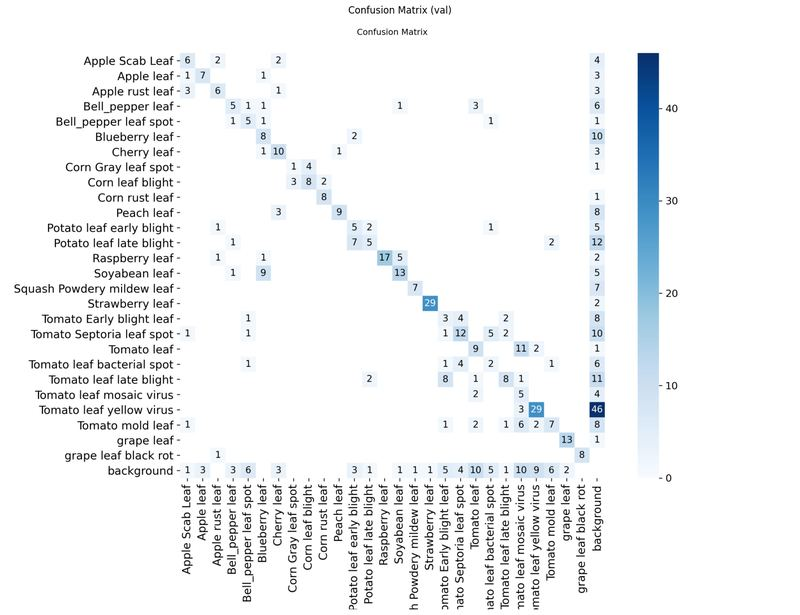

In [87]:
img_path = "/kaggle/working/runs/detect/val/confusion_matrix.png"
img = Image.open(img_path)

plt.figure(figsize=(18, 18))
plt.imshow(img)
plt.axis("off")
plt.title("Confusion Matrix (val)")
plt.show()


In [88]:
# grab confusion matrix from ultralytics result
cm_obj = getattr(metrics, "confusion_matrix", None)
if cm_obj is None and hasattr(model, "validator") and model.validator is not None:
    cm_obj = getattr(model.validator, "confusion_matrix", None)

cm = cm_obj.matrix  # shape = (nc+1, nc+1)

names = model.names
if isinstance(names, dict):
    names = [names[i] for i in range(len(names))]

nc = len(names)
bg = nc  # last index is background

tp = int(np.diag(cm)[:nc].sum())
wrong_class = int(cm[:nc, :nc].sum() - np.diag(cm)[:nc].sum())

# rows = predicted, cols = ground-truth, last row/col = background
bg_as_target = int(cm[:nc, bg].sum())   # background column -> predicted object (FP / extra detections)
target_as_bg = int(cm[bg, :nc].sum())   # background row    -> missed objects (FN)

total_gt = int(cm[:, :nc].sum())

print("Total GT objects:", total_gt)
print("TP:", tp)
print("Wrong class:", wrong_class)
print("Background predicted as target (FP):", bg_as_target)
print("Target predicted as background (FN):", target_as_bg)
print("TP + Wrong + FN =", tp + wrong_class + target_as_bg)

Total GT objects: 454
TP: 245
Wrong class: 134
Background predicted as target (FP): 168
Target predicted as background (FN): 75
TP + Wrong + FN = 454


## **Detection for RUN 2**

**Detect missed targets on background**

In [89]:
WEIGHTS = "/kaggle/working/yolo_runs/plantdoc_yolo11n/weights/best.pt"
train_img_dir = "/kaggle/working/train/images"
train_lbl_dir = "/kaggle/working/train/labels"
out_csv = "/kaggle/working/missing_label_candidates.csv"

PRED_CONF = 0.01
IOU_MATCH = 0.20
MAX_PER_IMAGE = 50
BATCH_SIZE = 64

model_mine = YOLO(WEIGHTS)

img_paths = sorted(
    glob.glob(os.path.join(train_img_dir, "*.jpg")) +
    glob.glob(os.path.join(train_img_dir, "*.jpeg")) +
    glob.glob(os.path.join(train_img_dir, "*.png"))
)
print("Train images:", len(img_paths))

def _read_gt_yolo(label_path):
    if (not os.path.exists(label_path)) or os.path.getsize(label_path) == 0:
        return []
    rows = []
    with open(label_path, "r") as f:
        for line in f:
            p = line.strip().split()
            if len(p) != 5:
                continue
            rows.append([float(x) for x in p])
    return rows

def _yolo_to_xyxy(row, W, H):
    cls, xc, yc, bw, bh = row
    x1 = (xc - bw/2) * W
    y1 = (yc - bh/2) * H
    x2 = (xc + bw/2) * W
    y2 = (yc + bh/2) * H
    return np.array([x1,y1,x2,y2], dtype=np.float32)

def _best_iou(box, boxes):
    if boxes.size == 0:
        return 0.0
    x1 = np.maximum(box[0], boxes[:,0])
    y1 = np.maximum(box[1], boxes[:,1])
    x2 = np.minimum(box[2], boxes[:,2])
    y2 = np.minimum(box[3], boxes[:,3])
    inter = np.maximum(0, x2-x1) * np.maximum(0, y2-y1)
    a1 = np.maximum(0, box[2]-box[0]) * np.maximum(0, box[3]-box[1])
    a2 = np.maximum(0, boxes[:,2]-boxes[:,0]) * np.maximum(0, boxes[:,3]-boxes[:,1])
    return float((inter / (a1 + a2 - inter + 1e-9)).max())

cands = []

print("Starting mining... first batch can be slow (GPU warmup).")

for start in tqdm(range(0, len(img_paths), BATCH_SIZE), desc="Batches"):
    batch_paths = img_paths[start:start + BATCH_SIZE]

    results = model_mine.predict(
        source=batch_paths,
        conf=PRED_CONF,
        iou=0.6,
        imgsz=640,
        device=0,
        verbose=False
    )

    for r in results:
        img_path = r.path
        img = cv2.imread(img_path)
        if img is None:
            continue
        H, W = img.shape[:2]

        lbl_path = os.path.join(train_lbl_dir, Path(img_path).stem + ".txt")
        gt_raw = _read_gt_yolo(lbl_path)

        gt_class_ids = set(int(row[0]) for row in gt_raw)  # classes already in this image
        gt_xyxy = np.array([_yolo_to_xyxy(row, W, H) for row in gt_raw], dtype=np.float32) if gt_raw else np.zeros((0,4), dtype=np.float32)

        if r.boxes is None or len(r.boxes) == 0:
            continue

        confs = r.boxes.conf.cpu().numpy()
        order = np.argsort(-confs)[:MAX_PER_IMAGE]

        for j in order:
            cls_id = int(r.boxes.cls[j].item())
            conf = float(r.boxes.conf[j].item())

            # only keep predictions for classes already labeled in that image
            if len(gt_class_ids) > 0 and cls_id not in gt_class_ids:
                continue

            x1, y1, x2, y2 = r.boxes.xyxy[j].cpu().numpy().astype(float)

            x1 = max(0, min(x1, W-1)); y1 = max(0, min(y1, H-1))
            x2 = max(0, min(x2, W-1)); y2 = max(0, min(y2, H-1))
            if x2 <= x1 or y2 <= y1:
                continue

            best_iou = _best_iou(np.array([x1,y1,x2,y2], dtype=np.float32), gt_xyxy)

            if best_iou < IOU_MATCH:
                name = model_mine.names[cls_id] if isinstance(model_mine.names, list) else model_mine.names.get(cls_id, str(cls_id))
                cands.append({
                    "image": Path(img_path).name,
                    "cls_id": cls_id,
                    "cls_name": name,
                    "conf": conf,
                    "x1": int(x1), "y1": int(y1), "x2": int(x2), "y2": int(y2),
                    "best_iou_with_gt": best_iou,
                    "keep": 0
                })

cand_df = pd.DataFrame(cands).sort_values("conf", ascending=False).reset_index(drop=True)
cand_df.to_csv(out_csv, index=False)

print("Mining done.")
print("Candidates:", len(cand_df))
print("Saved:", out_csv)
cand_df.head(10)

Train images: 4863
Starting mining... first batch can be slow (GPU warmup).


Batches: 100%|██████████| 76/76 [01:15<00:00,  1.00it/s]


Mining done.
Candidates: 18141
Saved: /kaggle/working/missing_label_candidates.csv


,image,cls_id,cls_name,conf,x1,y1,x2,y2,best_iou_with_gt,keep
0,22august2013008_1_jpgrfe4c5b4588e887bfbd9f40e1...,10,Peach leaf,0.995494,110,251,131,296,0.129435,0
1,bacterialspot06_jpgrf52a5a5e36264a2873aaf30882...,20,Tomato leaf bacterial spot,0.982723,316,251,352,303,0.018284,0
2,tomato_d2b_early_blight___aug_Tomato_Early_bli...,17,Tomato Early blight leaf,0.982255,9,180,92,277,0.120005,0
3,dscn3168_jpgrfbdddd148528960bbe59d00a7cc7ea672...,17,Tomato Early blight leaf,0.982089,138,0,169,59,0.001422,0
4,tomato_d2b_early_blight_rpitblado_zoom_jpgrfa9...,17,Tomato Early blight leaf,0.981869,8,180,92,277,0.114459,0
5,dscn3168_jpgrfbdddd14852__aug_Tomato_Early_bli...,17,Tomato Early blight leaf,0.979634,262,30,297,87,0.000000,0
6,peach_tree_20100523_jpgrfbc6862fd43c25ea5bb88f...,10,Peach leaf,0.975427,14,386,31,415,0.000000,0
7,0peach_jpgrfba5073e22e27a0586b7d96d632c7793b.jpg,10,Peach leaf,0.975212,0,180,17,238,0.000000,0
8,fo3zr_jpgrfb5a801a3bb087__aug_Bell_pepper_leaf...,4,Bell_pepper leaf spot,0.974501,77,72,140,184,0.168797,0
9,image_original_jpeg14950__aug_grape_leaf_black...,26,grape leaf black rot,0.974131,225,143,283,178,0.001523,0


**Filter targets based on our criterias**

In [90]:
AUTO_CONF = 0.25
MIN_AREA_PX = 15 * 15   # ignore tiny noisy boxes

cand_path = "/kaggle/working/missing_label_candidates.csv"
cand_df = pd.read_csv(cand_path)

def _area(r):
    return max(0, int(r.x2) - int(r.x1)) * max(0, int(r.y2) - int(r.y1))

cand_df["keep"] = (
    (cand_df["conf"].astype(float) >= AUTO_CONF) &
    (cand_df["best_iou_with_gt"].astype(float) < IOU_MATCH) &
    (cand_df.apply(_area, axis=1) >= MIN_AREA_PX)
).astype(int)

cand_df.to_csv(cand_path, index=False)

print("Total candidates:", len(cand_df))
print("Auto-approved:", int(cand_df["keep"].sum()))
print("Rejected:", int((cand_df["keep"] == 0).sum()))
cand_df[cand_df["keep"] == 1].head(10)


Total candidates: 18141
Auto-approved: 4730
Rejected: 13411


,image,cls_id,cls_name,conf,x1,y1,x2,y2,best_iou_with_gt,keep
0,22august2013008_1_jpgrfe4c5b4588e887bfbd9f40e1...,10,Peach leaf,0.995494,110,251,131,296,0.129435,1
1,bacterialspot06_jpgrf52a5a5e36264a2873aaf30882...,20,Tomato leaf bacterial spot,0.982723,316,251,352,303,0.018284,1
2,tomato_d2b_early_blight___aug_Tomato_Early_bli...,17,Tomato Early blight leaf,0.982255,9,180,92,277,0.120005,1
3,dscn3168_jpgrfbdddd148528960bbe59d00a7cc7ea672...,17,Tomato Early blight leaf,0.982089,138,0,169,59,0.001422,1
4,tomato_d2b_early_blight_rpitblado_zoom_jpgrfa9...,17,Tomato Early blight leaf,0.981869,8,180,92,277,0.114459,1
5,dscn3168_jpgrfbdddd14852__aug_Tomato_Early_bli...,17,Tomato Early blight leaf,0.979634,262,30,297,87,0.000000,1
6,peach_tree_20100523_jpgrfbc6862fd43c25ea5bb88f...,10,Peach leaf,0.975427,14,386,31,415,0.000000,1
7,0peach_jpgrfba5073e22e27a0586b7d96d632c7793b.jpg,10,Peach leaf,0.975212,0,180,17,238,0.000000,1
8,fo3zr_jpgrfb5a801a3bb087__aug_Bell_pepper_leaf...,4,Bell_pepper leaf spot,0.974501,77,72,140,184,0.168797,1
9,image_original_jpeg14950__aug_grape_leaf_black...,26,grape leaf black rot,0.974131,225,143,283,178,0.001523,1


**Append new bounding boxes**

In [91]:
train_img_dir = "/kaggle/working/train/images"
train_lbl_dir = "/kaggle/working/train/labels"
cand_path = "/kaggle/working/missing_label_candidates.csv"

# backup labels once
labels_bkp = "/kaggle/working/train/labels_backup_before_autofix"
if not os.path.exists(labels_bkp):
    shutil.copytree(train_lbl_dir, labels_bkp)
    print("Backup saved:", labels_bkp)

cand = pd.read_csv(cand_path)
approved = cand[cand["keep"] == 1].copy()
print("Approved rows:", len(approved))

def _xyxy_to_yolo(x1, y1, x2, y2, W, H):
    xc = ((x1 + x2) / 2) / W
    yc = ((y1 + y2) / 2) / H
    bw = (x2 - x1) / W
    bh = (y2 - y1) / H
    return xc, yc, bw, bh

def _ensure_file_ends_with_newline(path):
    if not os.path.exists(path):
        return
    if os.path.getsize(path) == 0:
        return
    with open(path, "rb") as f:
        f.seek(-1, os.SEEK_END)
        last = f.read(1)
    if last != b"\n":
        with open(path, "ab") as f:
            f.write(b"\n")

written = 0
skipped_dup = 0

for _, r in tqdm(approved.iterrows(), total=len(approved), desc="Appending labels"):
    img_path = os.path.join(train_img_dir, r["image"])
    img = cv2.imread(img_path)
    if img is None:
        continue
    H, W = img.shape[:2]

    cls_id = int(r["cls_id"])
    x1, y1, x2, y2 = int(r["x1"]), int(r["y1"]), int(r["x2"]), int(r["y2"])
    xc, yc, bw, bh = _xyxy_to_yolo(x1, y1, x2, y2, W, H)

    lbl_path = os.path.join(train_lbl_dir, Path(r["image"]).stem + ".txt")
    new_line = f"{cls_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"

    _ensure_file_ends_with_newline(lbl_path)

    # avoid duplicates
    if os.path.exists(lbl_path) and os.path.getsize(lbl_path) > 0:
        with open(lbl_path, "r") as f:
            existing = set(ln.strip() for ln in f if ln.strip())
        if new_line in existing:
            skipped_dup += 1
            continue

    with open(lbl_path, "a") as f:
        f.write(new_line + "\n")
    written += 1

print("Lines appended:", written)
print("Skipped duplicates:", skipped_dup)


Backup saved: /kaggle/working/train/labels_backup_before_autofix
Approved rows: 4730


Appending labels: 100%|██████████| 4730/4730 [00:08<00:00, 554.32it/s]

Lines appended: 4730
Skipped duplicates: 0


**Displaying results**

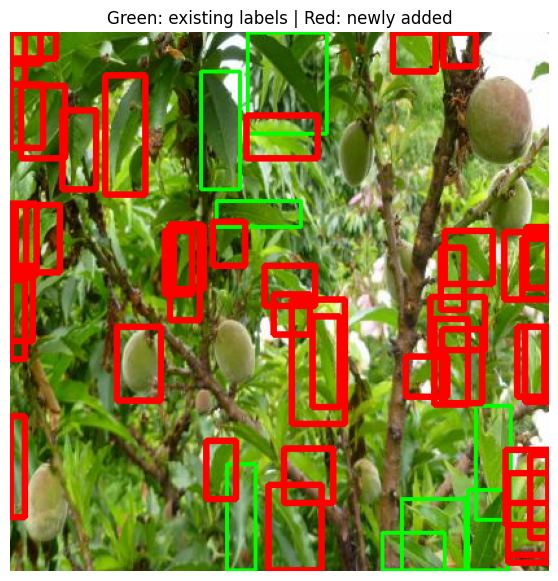

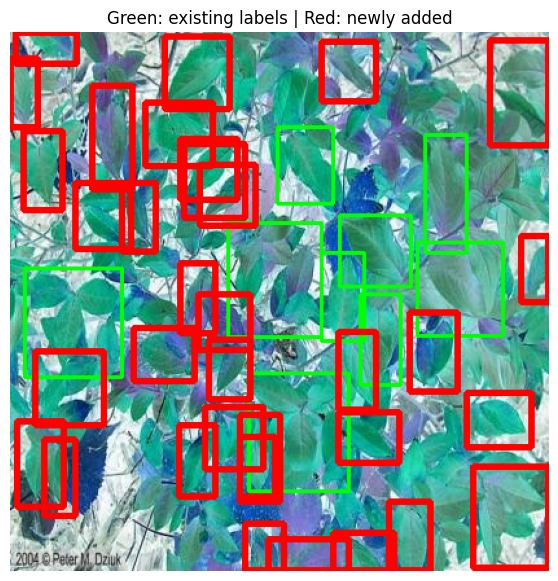

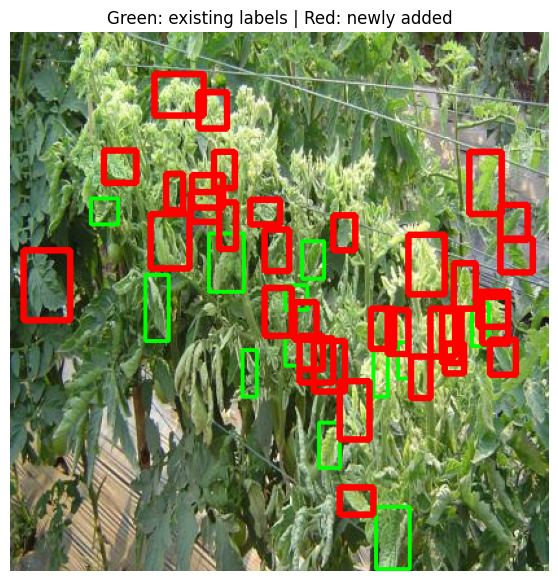

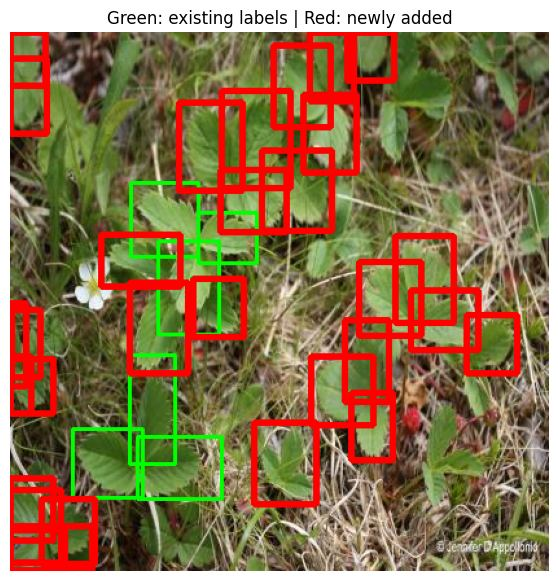

In [92]:
train_img_dir = "/kaggle/working/train/images"
train_lbl_dir = "/kaggle/working/train/labels"
cand_path = "/kaggle/working/missing_label_candidates.csv"

cand = pd.read_csv(cand_path)
new_boxes = cand[cand["keep"] == 1].copy()

if len(new_boxes) == 0:
    print("No new boxes were added (keep=1 is empty).")
else:
    # pick 4 images with most added boxes
    top_imgs = (new_boxes.groupby("image")
                .size()
                .sort_values(ascending=False)
                .head(4)
                .index.tolist())

    def _read_yolo(lbl_path):
        if (not os.path.exists(lbl_path)) or os.path.getsize(lbl_path) == 0:
            return []
        out = []
        with open(lbl_path, "r") as f:
            for line in f:
                p = line.strip().split()
                if len(p) != 5:
                    continue
                out.append([float(x) for x in p])
        return out

    def _yolo_to_xyxy(row, W, H):
        cls, xc, yc, bw, bh = row
        x1 = (xc - bw/2) * W
        y1 = (yc - bh/2) * H
        x2 = (xc + bw/2) * W
        y2 = (yc + bh/2) * H
        return int(cls), int(x1), int(y1), int(x2), int(y2)

    for fname in top_imgs:
        img_path = os.path.join(train_img_dir, fname)
        img = cv2.imread(img_path)
        if img is None:
            continue
        H, W = img.shape[:2]

        # read current labels (after append)
        lbl_path = os.path.join(train_lbl_dir, Path(fname).stem + ".txt")
        gt = _read_yolo(lbl_path)

        vis = img.copy()

        # draw all current GT boxes in green
        for row in gt:
            _, x1,y1,x2,y2 = _yolo_to_xyxy(row, W, H)
            x1 = max(0, min(x1, W-1)); y1 = max(0, min(y1, H-1))
            x2 = max(0, min(x2, W-1)); y2 = max(0, min(y2, H-1))
            if x2 > x1 and y2 > y1:
                cv2.rectangle(vis, (x1,y1), (x2,y2), (0,255,0), 2)

        # draw only newly-added boxes in red (from candidates CSV)
        sub = new_boxes[new_boxes["image"] == fname]
        for _, r in sub.iterrows():
            x1,y1,x2,y2 = int(r.x1),int(r.y1),int(r.x2),int(r.y2)
            x1 = max(0, min(x1, W-1)); y1 = max(0, min(y1, H-1))
            x2 = max(0, min(x2, W-1)); y2 = max(0, min(y2, H-1))
            if x2 > x1 and y2 > y1:
                cv2.rectangle(vis, (x1,y1), (x2,y2), (0,0,255), 3)

        plt.figure(figsize=(7,7))
        plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.title("Green: existing labels | Red: newly added")
        plt.show()


## **RUN 2**

**Deleting last run model**

In [93]:
p = "/kaggle/working/yolo11n.pt"
if os.path.exists(p):
    os.remove(p)
    print("Deleted:", p)
else:
    print("Not found:", p)

Deleted: /kaggle/working/yolo11n.pt


**Importing model again and training**

In [94]:
# Load the YOLOv11n model weights
model = YOLO("yolo11n.pt")

In [95]:
# Train the model
results = model.train(

    optimizer="auto",
    data=data_yaml,
    epochs=40,
    imgsz=640,
    batch=32,
    workers=4,
    device=[0, 1],

    # augmentations
    fliplr=0.5,
    flipud=0,
    degrees=8.0,
    translate=0.1,
    scale=0.3,
    shear=0.0,
    perspective=0.0,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    mosaic=0.7,
    mixup=0.0,
    copy_paste=0.0,
    close_mosaic=0,

    # training setup
    cos_lr=True,
    patience=5,
    project="/kaggle/working/yolo_runs",
    name="plantdoc_yolo11n2",
    exist_ok=False,
    save=True,
)


Ultralytics 8.4.13 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
                                                      CUDA:1 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=8.0, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.7, multi_scale=0.0, name=plantdoc_yolo11n2, nbs=64, nms=False, opse

**Displaying resullts**

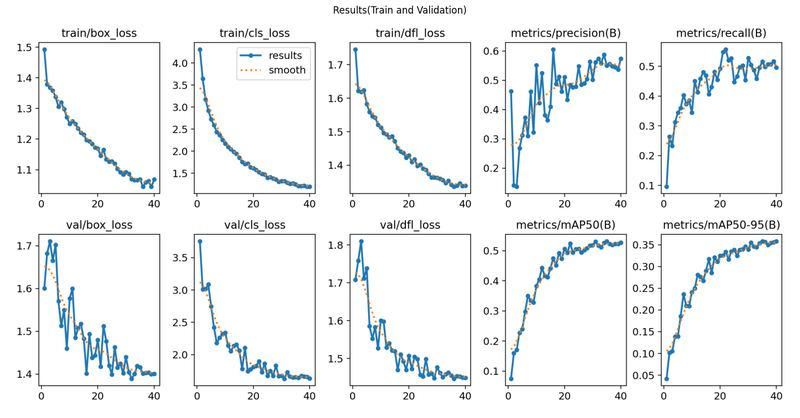

In [96]:
img_path = "/kaggle/working/yolo_runs/plantdoc_yolo11n2/results.png"
img = Image.open(img_path)

plt.figure(figsize=(18, 18))
plt.imshow(img)
plt.axis("off")
plt.title("Results(Train and Validation)")
plt.show()

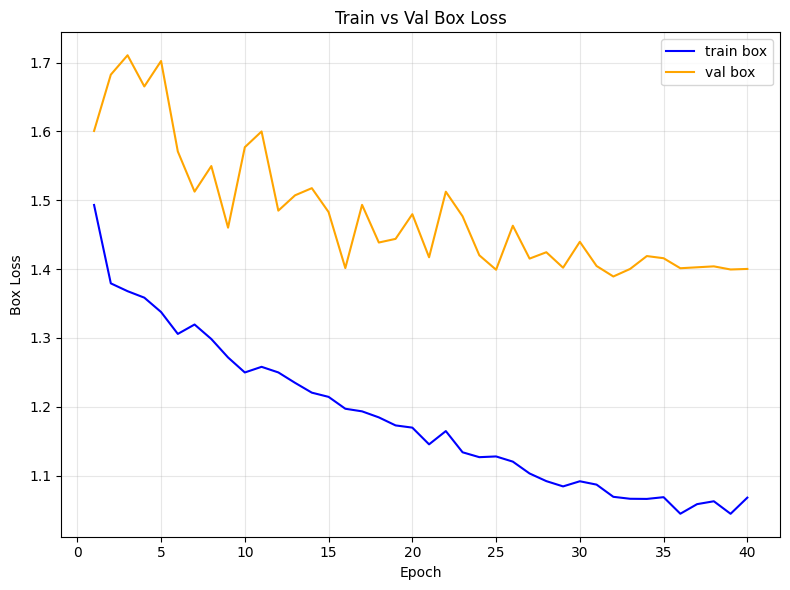

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n2/train_vs_val_box_loss.png


In [97]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n2")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Train vs Val Box Loss
plt.figure(figsize=(8, 6))

# Plot train and val box loss
plt.plot(x, df["train/box_loss"], label="train box", color='blue')
plt.plot(x, df["val/box_loss"], label="val box", color='orange')

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("Box Loss")
plt.title("Train vs Val Box Loss")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "train_vs_val_box_loss.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


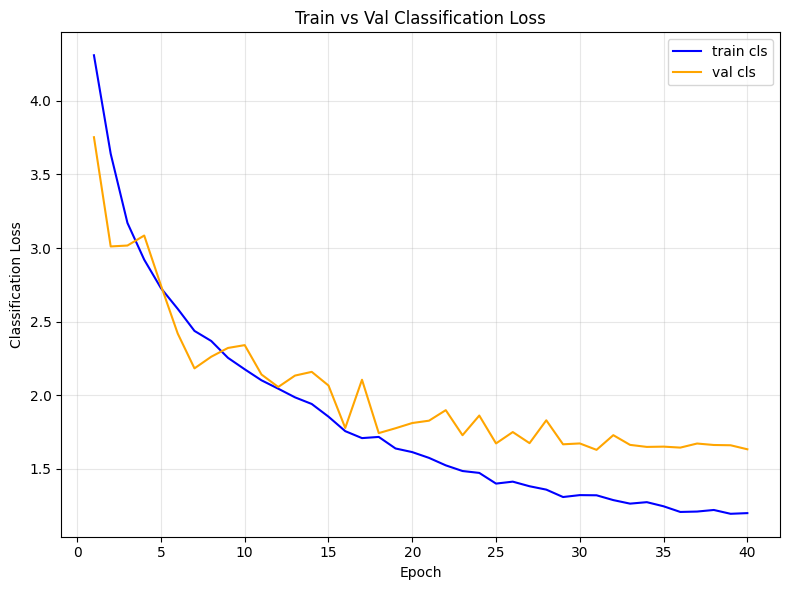

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n2/train_vs_val_cls_loss.png


In [98]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n2")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Train vs Val Classification Loss
plt.figure(figsize=(8, 6))

# Plot train and val classification loss
plt.plot(x, df["train/cls_loss"], label="train cls", color='blue')
plt.plot(x, df["val/cls_loss"], label="val cls", color='orange')

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("Classification Loss")
plt.title("Train vs Val Classification Loss")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "train_vs_val_cls_loss.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


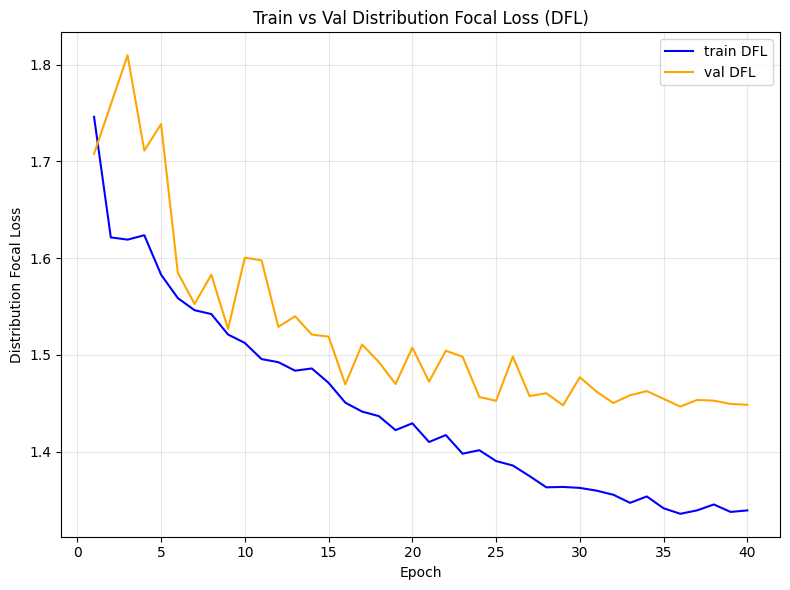

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n2/train_vs_val_dfl_loss.png


In [99]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n2")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Train vs Val DFL Loss (Distribution Focal Loss)
plt.figure(figsize=(8, 6))

# Plot train and val DFL loss
plt.plot(x, df["train/dfl_loss"], label="train DFL", color='blue')
plt.plot(x, df["val/dfl_loss"], label="val DFL", color='orange')

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("Distribution Focal Loss")
plt.title("Train vs Val Distribution Focal Loss (DFL)")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "train_vs_val_dfl_loss.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


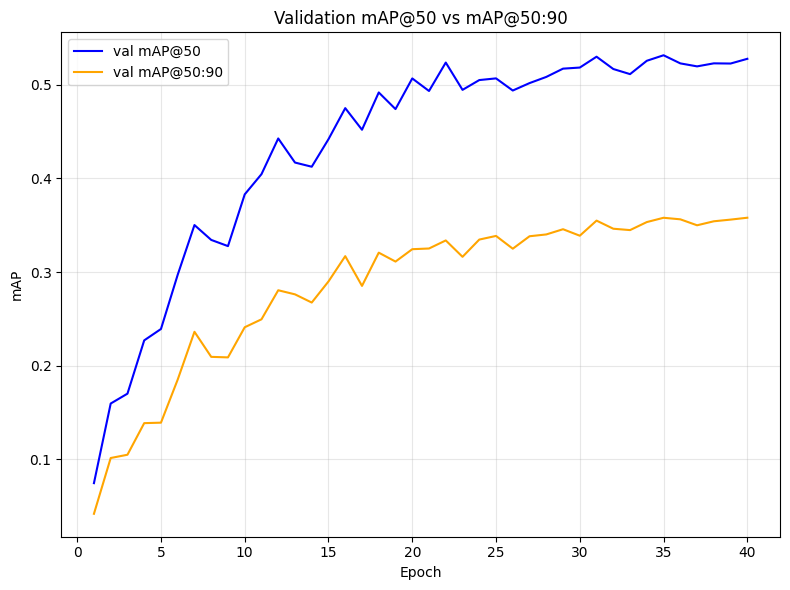

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n2/val_mAP50_vs_mAP50_95.png


In [100]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n2/")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Val mAP@50 and mAP@50:90
plt.figure(figsize=(8, 6))

# Plot val mAP@50 and val mAP@50:90 (use correct columns for val mAP)
plt.plot(x, df['metrics/mAP50(B)'], label="val mAP@50", color='blue')  # Validation mAP@50
plt.plot(x, df['metrics/mAP50-95(B)'], label="val mAP@50:90", color='orange')  # Validation mAP@50:95

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("Validation mAP@50 vs mAP@50:90")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "val_mAP50_vs_mAP50_95.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


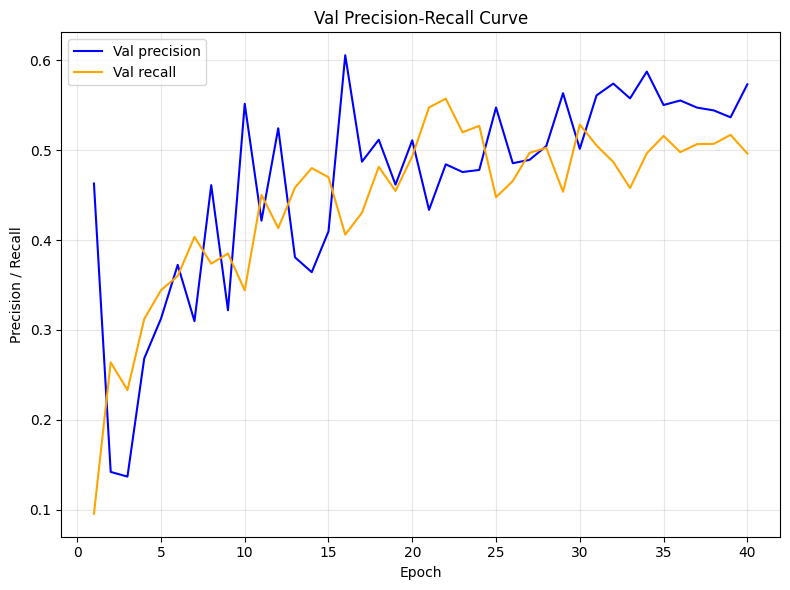

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n2/train_vs_val_pr_curve.png


In [101]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n2/")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Train Precision-Recall Curve
plt.figure(figsize=(8, 6))

# Plot train PR (Precision-Recall) curve
plt.plot(x, df["metrics/precision(B)"], label="Val precision", color='blue')
plt.plot(x, df["metrics/recall(B)"], label="Val recall", color='orange')

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("Precision / Recall")
plt.title("Val Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "train_vs_val_pr_curve.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


In [103]:
DATA = "/kaggle/working/data.yaml"
WEIGHTS = "/kaggle/working/yolo_runs/plantdoc_yolo11n2/weights/best.pt"

model = YOLO(WEIGHTS)
metrics = model.val(
    data=DATA,
    split='test',
    imgsz=640,
    conf=0.25,
    iou=0.50,
    plots=True
)
print(metrics)

Ultralytics 8.4.13 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,587,417 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1409.8±154.4 MB/s, size: 61.8 KB)
val: Scanning /kaggle/working/test/labels.cache... 238 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 238/238 83.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.4it/s 3.4s0.1s
                   all        238        454      0.577      0.522      0.572      0.469
       Apple Scab Leaf         10         13      0.676      0.462      0.543      0.453
            Apple leaf          9         10      0.731        0.7      0.803      0.648
       Apple rust leaf         10         11      0.774      0.625      0.757      0.689
      Bell_pepper leaf          8         11      0.477      0.665      0.411      0.345
 Bell_pepper leaf spot          9         15 

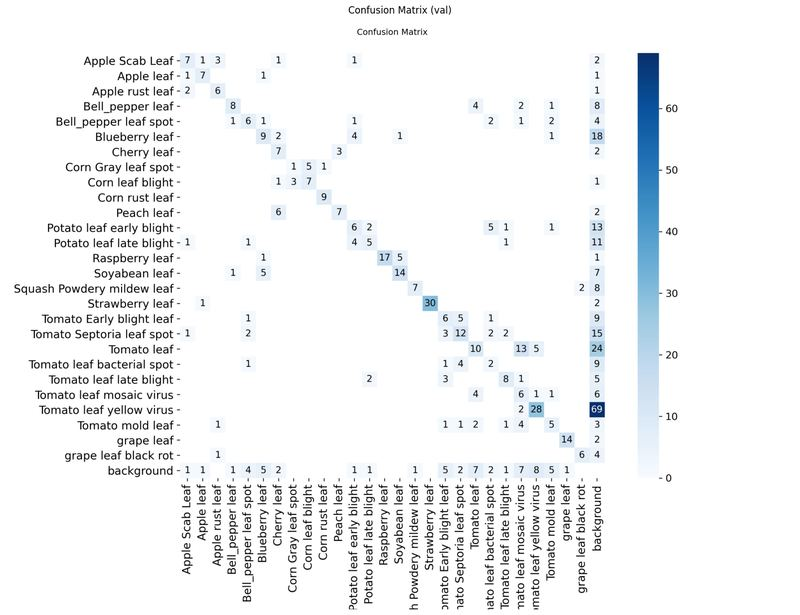

In [104]:
img_path = "/kaggle/working/runs/detect/val2/confusion_matrix.png"
img = Image.open(img_path)

plt.figure(figsize=(18, 18))
plt.imshow(img)
plt.axis("off")
plt.title("Confusion Matrix (val)")
plt.show()


In [105]:
# grab confusion matrix from ultralytics result
cm_obj = getattr(metrics, "confusion_matrix", None)
if cm_obj is None and hasattr(model, "validator") and model.validator is not None:
    cm_obj = getattr(model.validator, "confusion_matrix", None)

cm = cm_obj.matrix

names = model.names
if isinstance(names, dict):
    names = [names[i] for i in range(len(names))]

nc = len(names)
bg = nc

tp = int(np.diag(cm)[:nc].sum())
wrong_class = int(cm[:nc, :nc].sum() - np.diag(cm)[:nc].sum())

# rows = predicted, cols = ground-truth, last row/col = background
bg_as_target = int(cm[:nc, bg].sum())   # background column -> predicted object (FP / extra detections)
target_as_bg = int(cm[bg, :nc].sum())   # background row    -> missed objects (FN)

total_gt = int(cm[:, :nc].sum())

print("Total GT objects:", total_gt)
print("TP:", tp)
print("Wrong class:", wrong_class)
print("Background predicted as target (FP):", bg_as_target)
print("Target predicted as background (FN):", target_as_bg)
print("TP + Wrong + FN =", tp + wrong_class + target_as_bg)

Total GT objects: 454
TP: 250
Wrong class: 149
Background predicted as target (FP): 227
Target predicted as background (FN): 55
TP + Wrong + FN = 454


## **Filling new detections for RUN 3**

In [106]:
SRC_IMG_DIR = "/kaggle/working/train/images"
SRC_LBL_DIR = "/kaggle/working/train/labels"
DATA_YAML_IN = "/kaggle/working/data.yaml"

# model used for mining
MINE_WEIGHTS = "/kaggle/working/yolo_runs/plantdoc_yolo11n2/weights/best.pt"

# only cut predictions that are confident
PRED_CONF = 0.25

# if pred overlaps a GT object more than this
IOU_MATCH = 0.10

MAX_CUTS_PER_IMAGE = 80

# shrink mined box
SHRINK_FRAC = 0.20

# output train set
OUT_ROOT = "/kaggle/working/train_cutout_shrink"
OUT_IMG_DIR = os.path.join(OUT_ROOT, "images")
OUT_LBL_DIR = os.path.join(OUT_ROOT, "labels")
DATA_YAML_OUT = "/kaggle/working/data_cutout_shrink.yaml"

os.makedirs(OUT_IMG_DIR, exist_ok=True)
os.makedirs(OUT_LBL_DIR, exist_ok=True)

def read_yolo(lbl_path):
    if (not os.path.exists(lbl_path)) or os.path.getsize(lbl_path) == 0:
        return []
    out = []
    with open(lbl_path, "r") as f:
        for line in f:
            p = line.strip().split()
            if len(p) == 5:
                out.append([float(x) for x in p])
    return out

def yolo_to_xyxy(row, W, H):
    cls, xc, yc, bw, bh = row
    x1 = (xc - bw/2) * W
    y1 = (yc - bh/2) * H
    x2 = (xc + bw/2) * W
    y2 = (yc + bh/2) * H
    return int(cls), np.array([x1, y1, x2, y2], dtype=np.float32)

def best_iou(box, boxes):
    if boxes.size == 0:
        return 0.0
    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    a1 = np.maximum(0, box[2] - box[0]) * np.maximum(0, box[3] - box[1])
    a2 = np.maximum(0, boxes[:, 2] - boxes[:, 0]) * np.maximum(0, boxes[:, 3] - boxes[:, 1])
    return float((inter / (a1 + a2 - inter + 1e-9)).max())

def clamp_xyxy(x1, y1, x2, y2, W, H):
    x1 = max(0, min(int(round(x1)), W - 1))
    y1 = max(0, min(int(round(y1)), H - 1))
    x2 = max(0, min(int(round(x2)), W))
    y2 = max(0, min(int(round(y2)), H))
    if x2 <= x1 or y2 <= y1:
        return None
    return x1, y1, x2, y2

def shrink_box(x1, y1, x2, y2, W, H, shrink=0.10):
    bw = x2 - x1
    bh = y2 - y1
    dx = (bw * shrink) / 2.0
    dy = (bh * shrink) / 2.0
    nx1 = x1 + dx
    ny1 = y1 + dy
    nx2 = x2 - dx
    ny2 = y2 - dy
    return clamp_xyxy(nx1, ny1, nx2, ny2, W, H)

# list images
img_paths = sorted(
    glob.glob(os.path.join(SRC_IMG_DIR, "*.jpg")) +
    glob.glob(os.path.join(SRC_IMG_DIR, "*.jpeg")) +
    glob.glob(os.path.join(SRC_IMG_DIR, "*.png"))
)
if not img_paths:
    raise FileNotFoundError("No images found in " + SRC_IMG_DIR)

mine_model = YOLO(MINE_WEIGHTS)

changed = 0
copied = 0
total_cuts = 0

for img_path in tqdm(img_paths, desc="cutout (shrink 10%)"):
    fname = Path(img_path).name
    stem = Path(img_path).stem

    src_lbl = os.path.join(SRC_LBL_DIR, stem + ".txt")
    out_lbl = os.path.join(OUT_LBL_DIR, stem + ".txt")

    # labels stay exactly the same
    if os.path.exists(src_lbl):
        shutil.copy2(src_lbl, out_lbl)
    else:
        open(out_lbl, "a").close()

    out_img = os.path.join(OUT_IMG_DIR, fname)

    img = cv2.imread(img_path)
    if img is None:
        shutil.copy2(img_path, out_img)
        copied += 1
        continue

    H, W = img.shape[:2]

    # GT boxes to protect labeled objects
    gt_rows = read_yolo(src_lbl)
    gt_xyxy = []
    for r in gt_rows:
        _, b = yolo_to_xyxy(r, W, H)
        gt_xyxy.append(b)
    gt_xyxy = np.array(gt_xyxy, dtype=np.float32) if gt_xyxy else np.zeros((0, 4), dtype=np.float32)

    pred = mine_model.predict(source=img_path, conf=PRED_CONF, iou=0.6, imgsz=640, device=0, verbose=False)[0]
    if pred.boxes is None or len(pred.boxes) == 0:
        shutil.copy2(img_path, out_img)
        copied += 1
        continue

    confs = pred.boxes.conf.cpu().numpy()
    order = np.argsort(-confs)

    # fill color = average color of image
    fill = img.mean(axis=(0, 1)).astype(np.uint8).tolist()

    cuts_done = 0
    for j in order:
        if cuts_done >= MAX_CUTS_PER_IMAGE:
            break

        x1, y1, x2, y2 = pred.boxes.xyxy[j].cpu().numpy().astype(float)

        bb = clamp_xyxy(x1, y1, x2, y2, W, H)
        if bb is None:
            continue
        x1, y1, x2, y2 = bb

        # shrink the mined box
        bb2 = shrink_box(x1, y1, x2, y2, W, H, shrink=SHRINK_FRAC)
        if bb2 is None:
            continue
        xa, ya, xb, yb = bb2

        # skip if it overlaps real GT objects
        iou = best_iou(np.array([xa, ya, xb, yb], dtype=np.float32), gt_xyxy)
        if iou >= IOU_MATCH:
            continue

        img[ya:yb, xa:xb] = fill
        cuts_done += 1

    if cuts_done > 0:
        cv2.imwrite(out_img, img)
        changed += 1
        total_cuts += cuts_done
    else:
        shutil.copy2(img_path, out_img)
        copied += 1

print("images changed:", changed)
print("images copied:", copied)
print("total cutout patches:", total_cuts)
print("saved train:", OUT_ROOT)

# create yaml that points train
with open(DATA_YAML_IN, "r") as f:
    data = yaml.safe_load(f)

base = data.get("path", None)

def to_abs(p):
    if p is None:
        return None
    p = str(p)
    if os.path.isabs(p):
        return p
    if base:
        return os.path.join(str(base), p)
    return p

data.pop("path", None)
data["train"] = OUT_IMG_DIR
if "val" in data:
    data["val"] = to_abs(data["val"])
if "test" in data:
    data["test"] = to_abs(data["test"])

with open(DATA_YAML_OUT, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("saved:", DATA_YAML_OUT)
print("use this for run3: data=DATA_YAML_OUT")


cutout (shrink 10%): 100%|██████████| 4863/4863 [01:47<00:00, 45.32it/s]

images changed: 1251
images copied: 3612
total cutout patches: 4570
saved train: /kaggle/working/train_cutout_shrink
saved: /kaggle/working/data_cutout_shrink.yaml
use this for run3: data=DATA_YAML_OUT


In [ ]:
import os, glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import random

SRC_IMG_DIR = "/kaggle/working/train/images"
SRC_LBL_DIR = "/kaggle/working/train/labels"

# pick first cutout folder that exists
cands = [
    "/kaggle/working/train_cutout_all/images",
    "/kaggle/working/train_cutout_shrink10/images",
]
OUT_IMG_DIR = None
for c in cands:
    if os.path.isdir(c):
        OUT_IMG_DIR = c
        break

if OUT_IMG_DIR is None:
    raise FileNotFoundError("cutout images folder not found. check OUT_ROOT name.")

print("before:", SRC_IMG_DIR)
print("after :", OUT_IMG_DIR)

N_SHOW = 20
SEED = 7

def list_imgs(folder):
    exts = ("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG")
    files = []
    for e in exts:
        files += glob.glob(os.path.join(folder, e))
    return files

def read_yolo_txt(lbl_path):
    if (not os.path.exists(lbl_path)) or os.path.getsize(lbl_path) == 0:
        return []
    rows = []
    with open(lbl_path, "r") as f:
        for line in f:
            p = line.strip().split()
            if len(p) == 5:
                rows.append([float(x) for x in p])
    return rows

def yolo_to_xyxy(row, W, H):
    _, xc, yc, bw, bh = row
    x1 = (xc - bw/2) * W
    y1 = (yc - bh/2) * H
    x2 = (xc + bw/2) * W
    y2 = (yc + bh/2) * H
    x1 = max(0, min(int(round(x1)), W - 1))
    y1 = max(0, min(int(round(y1)), H - 1))
    x2 = max(0, min(int(round(x2)), W))
    y2 = max(0, min(int(round(y2)), H))
    if x2 <= x1 or y2 <= y1:
        return None
    return x1, y1, x2, y2

def draw_gt_boxes(img_bgr, img_name, color=(0, 0, 255), thickness=2):
    stem = Path(img_name).stem
    lbl_path = os.path.join(SRC_LBL_DIR, stem + ".txt")
    rows = read_yolo_txt(lbl_path)
    if not rows:
        return img_bgr

    H, W = img_bgr.shape[:2]
    out = img_bgr.copy()
    for r in rows:
        bb = yolo_to_xyxy(r, W, H)
        if bb is None:
            continue
        x1, y1, x2, y2 = bb
        cv2.rectangle(out, (x1, y1), (x2, y2), color, thickness)
    return out

def resize_keep_ratio(img_bgr, target_w=520, target_h=520):
    h, w = img_bgr.shape[:2]
    if h == 0 or w == 0:
        return img_bgr

    scale = min(target_w / w, target_h / h)
    nw = max(1, int(w * scale))
    nh = max(1, int(h * scale))

    resized = cv2.resize(img_bgr, (nw, nh), interpolation=cv2.INTER_AREA)

    out = np.zeros((target_h, target_w, 3), dtype=resized.dtype)
    y0 = (target_h - nh) // 2
    x0 = (target_w - nw) // 2
    out[y0:y0+nh, x0:x0+nw] = resized
    return out

src_list = list_imgs(SRC_IMG_DIR)
out_list = list_imgs(OUT_IMG_DIR)

print("src images:", len(src_list))
print("out images:", len(out_list))

src_imgs = {Path(p).name: p for p in src_list}
out_imgs = {Path(p).name: p for p in out_list}

common = sorted(set(src_imgs) & set(out_imgs))
print("common names:", len(common))

if not common:
    src_stems = {}
    for p in src_list:
        src_stems.setdefault(Path(p).stem, p)
    out_stems = {}
    for p in out_list:
        out_stems.setdefault(Path(p).stem, p)

    common_stems = sorted(set(src_stems) & set(out_stems))
    print("common stems:", len(common_stems))
    if not common_stems:
        raise FileNotFoundError("no matches between SRC and OUT (names/stems).")

    pairs = [(src_stems[s], out_stems[s]) for s in common_stems]
else:
    pairs = [(src_imgs[n], out_imgs[n]) for n in common]

# detect changed images
changed_pairs = []
for p1, p2 in pairs:
    a = cv2.imread(p1)
    b = cv2.imread(p2)
    if a is None or b is None or a.shape != b.shape:
        continue
    if float(cv2.absdiff(a, b).mean()) > 1.0:
        changed_pairs.append((p1, p2))

print("changed pairs:", len(changed_pairs))

if not changed_pairs:
    print("matches found but they look identical (maybe no cutouts happened).")
else:
    rng = random.Random(SEED)
    rng.shuffle(changed_pairs)
    sample = changed_pairs[:N_SHOW]

    SHOW_W, SHOW_H = 520, 520

    fig, axes = plt.subplots(len(sample), 2, figsize=(12, 3.6 * len(sample)))
    if len(sample) == 1:
        axes = np.array([axes])

    for i, (p_before, p_after) in enumerate(sample):
        name = Path(p_before).name

        before = cv2.imread(p_before)
        after  = cv2.imread(p_after)
        if before is None or after is None:
            continue

        diff = cv2.absdiff(before, after)
        diff_g = cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY)
        mask = (diff_g > 25).astype(np.uint8) * 255

        k = np.ones((7, 7), np.uint8)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k, iterations=1)
        mask = cv2.dilate(mask, k, iterations=1)

        cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        vis_before = draw_gt_boxes(before, name, color=(0, 0, 255), thickness=2)
        vis_after  = draw_gt_boxes(after,  name, color=(0, 0, 255), thickness=2)

        for c in cnts:
            x, y, w, h = cv2.boundingRect(c)
            if w * h < 300:
                continue
            cv2.rectangle(vis_before, (x, y), (x + w, y + h), (0, 255, 0), 3)
            cv2.rectangle(vis_after,  (x, y), (x + w, y + h), (0, 255, 0), 3)

        vis_before = resize_keep_ratio(vis_before, SHOW_W, SHOW_H)
        vis_after  = resize_keep_ratio(vis_after,  SHOW_W, SHOW_H)

        axes[i, 0].imshow(cv2.cvtColor(vis_before, cv2.COLOR_BGR2RGB))
        axes[i, 0].axis("off")
        axes[i, 0].set_title("Before (red=GT, green=cutout)")

        axes[i, 1].imshow(cv2.cvtColor(vis_after, cv2.COLOR_BGR2RGB))
        axes[i, 1].axis("off")
        axes[i, 1].set_title("After (red=GT, green=cutout)")

    plt.tight_layout()
    plt.show()


In [107]:
data_yaml = DATA_YAML_OUT

## **RUN 3**

**Deleting last run model**

In [108]:
p = "/kaggle/working/yolo11n.pt"
if os.path.exists(p):
    os.remove(p)
    print("Deleted:", p)
else:
    print("Not found:", p)

Deleted: /kaggle/working/yolo11n.pt


**Importing model again and training**

In [109]:
# Load the YOLOv11n model weights
model = YOLO("yolo11n.pt")

In [110]:
# Train the model
results = model.train(

    optimizer="auto",
    data=data_yaml,
    epochs=40,
    imgsz=640,
    batch=32,
    workers=4,
    device=[0, 1],

    # augmentations
    fliplr=0.5,
    flipud=0,
    degrees=8.0,
    translate=0.1,
    scale=0.3,
    shear=0.0,
    perspective=0.0,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    mosaic=0.7,
    mixup=0.0,
    copy_paste=0.0,
    close_mosaic=0,

    # training setup
    cos_lr=True,
    patience=5,
    project="/kaggle/working/yolo_runs",
    name="plantdoc_yolo11n3",
    exist_ok=False,
    save=True,
)


Ultralytics 8.4.13 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
                                                      CUDA:1 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data_cutout_shrink.yaml, degrees=8.0, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.7, multi_scale=0.0, name=plantdoc_yolo11n3, nbs=64, n

**Displaying results**

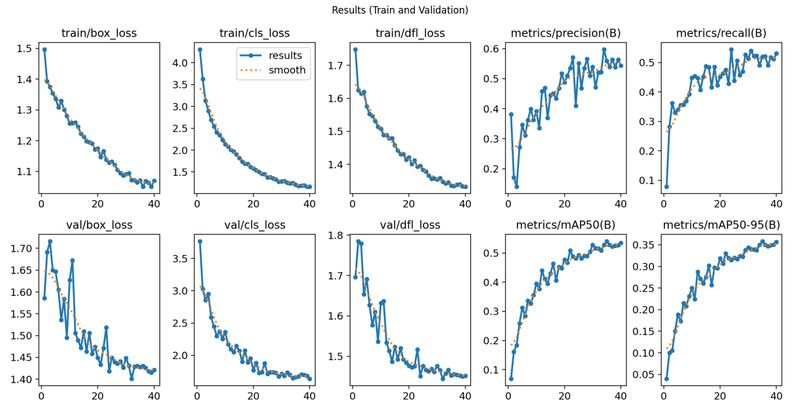

In [111]:
img_path = "/kaggle/working/yolo_runs/plantdoc_yolo11n3/results.png"

if not os.path.exists(img_path):
    raise FileNotFoundError(f"results.png not found at: {img_path}")

img = Image.open(img_path)

plt.figure(figsize=(18, 18))
plt.imshow(img)
plt.axis("off")
plt.title("Results (Train and Validation)")
plt.show()


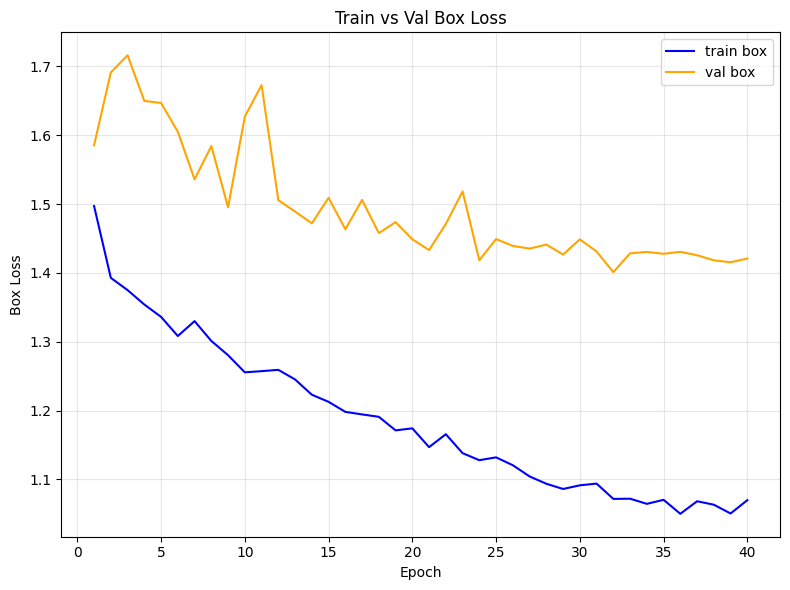

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n3/train_vs_val_box_loss.png


In [112]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n3")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Train vs Val Box Loss
plt.figure(figsize=(8, 6))

# Plot train and val box loss
plt.plot(x, df["train/box_loss"], label="train box", color='blue')
plt.plot(x, df["val/box_loss"], label="val box", color='orange')

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("Box Loss")
plt.title("Train vs Val Box Loss")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "train_vs_val_box_loss.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


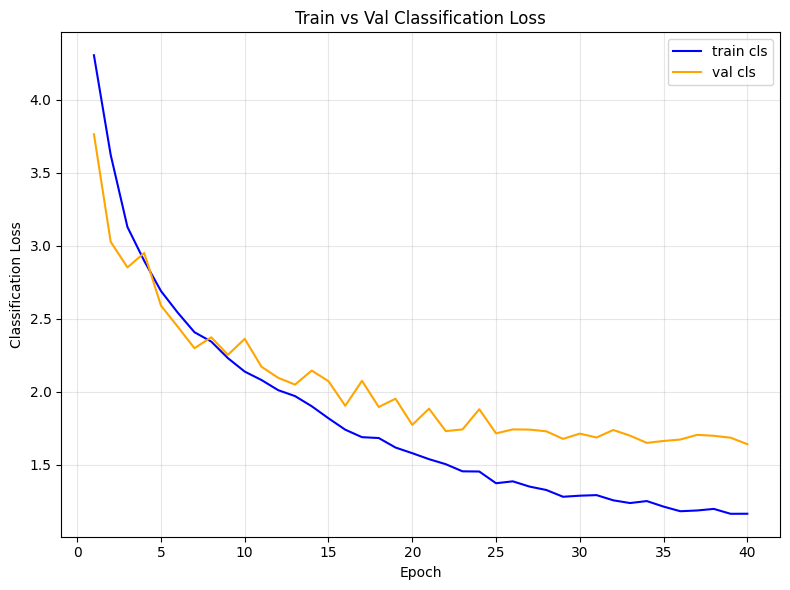

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n3/train_vs_val_cls_loss.png


In [113]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n3")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Train vs Val Classification Loss
plt.figure(figsize=(8, 6))

# Plot train and val classification loss
plt.plot(x, df["train/cls_loss"], label="train cls", color='blue')
plt.plot(x, df["val/cls_loss"], label="val cls", color='orange')

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("Classification Loss")
plt.title("Train vs Val Classification Loss")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "train_vs_val_cls_loss.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


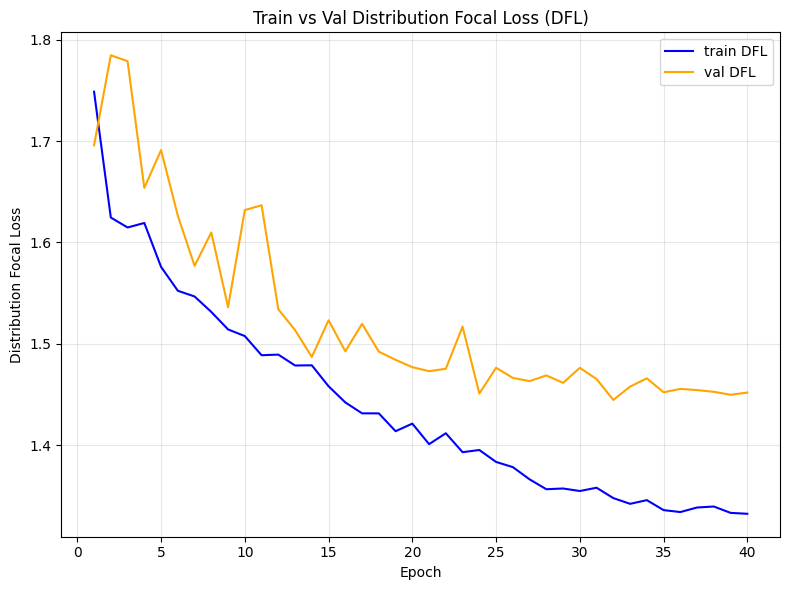

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n3/train_vs_val_dfl_loss.png


In [114]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n3")


# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Train vs Val DFL Loss (Distribution Focal Loss)
plt.figure(figsize=(8, 6))

# Plot train and val DFL loss
plt.plot(x, df["train/dfl_loss"], label="train DFL", color='blue')
plt.plot(x, df["val/dfl_loss"], label="val DFL", color='orange')

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("Distribution Focal Loss")
plt.title("Train vs Val Distribution Focal Loss (DFL)")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "train_vs_val_dfl_loss.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


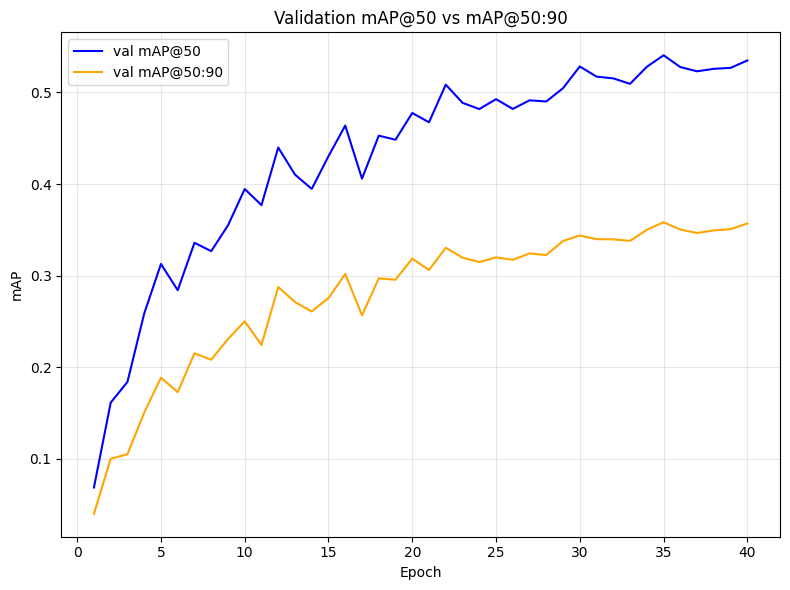

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n3/val_mAP50_vs_mAP50_95.png


In [115]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n3/")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Val mAP@50 and mAP@50:90
plt.figure(figsize=(8, 6))

# Plot val mAP@50 and val mAP@50:90
plt.plot(x, df['metrics/mAP50(B)'], label="val mAP@50", color='blue')           # Validation mAP@50
plt.plot(x, df['metrics/mAP50-95(B)'], label="val mAP@50:90", color='orange')   # Validation mAP@50:95

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("Validation mAP@50 vs mAP@50:90")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "val_mAP50_vs_mAP50_95.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


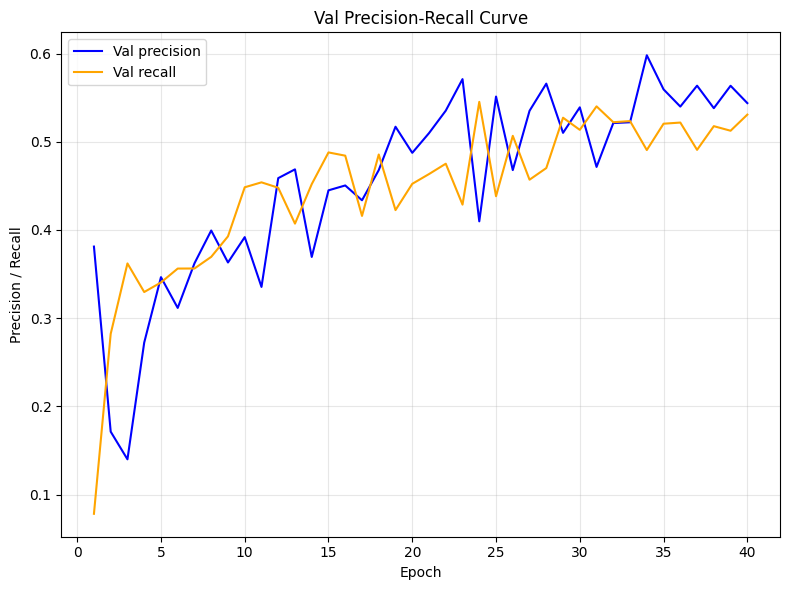

Saved: /kaggle/working/yolo_runs/plantdoc_yolo11n3/val_precision_recall_over_epochs.png


In [116]:
RUN = Path("/kaggle/working/yolo_runs/plantdoc_yolo11n3/")

# Read the results from the CSV file
df = pd.read_csv(RUN / "results.csv")
x = df["epoch"] if "epoch" in df.columns else range(len(df))

# Create the plot for Val Precision-Recall Curve (over epochs)
plt.figure(figsize=(8, 6))

# Plot val precision and val recall over epochs
plt.plot(x, df["metrics/precision(B)"], label="Val precision", color='blue')
plt.plot(x, df["metrics/recall(B)"], label="Val recall", color='orange')

# Set labels and title
plt.xlabel("Epoch")
plt.ylabel("Precision / Recall")
plt.title("Val Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image to your results folder
out_path = RUN / "val_precision_recall_over_epochs.png"
plt.tight_layout()
plt.savefig(out_path, dpi=200)

# Display the plot
plt.show()

print("Saved:", out_path)


In [117]:
DATA = "/kaggle/working/data.yaml"
WEIGHTS = "/kaggle/working/yolo_runs/plantdoc_yolo11n3/weights/best.pt"

model = YOLO(WEIGHTS)
metrics = model.val(
    data=DATA,
    split='test',
    imgsz=640,
    conf=0.25,
    iou=0.50,
    plots=True
)
print(metrics)

Ultralytics 8.4.13 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,587,417 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1629.1±480.0 MB/s, size: 61.8 KB)
val: Scanning /kaggle/working/test/labels.cache... 238 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 238/238 99.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.4it/s 3.4s0.1s
                   all        238        454      0.529      0.584      0.558      0.449
       Apple Scab Leaf         10         13       0.58      0.638      0.629      0.517
            Apple leaf          9         10      0.665        0.7      0.713      0.567
       Apple rust leaf         10         11      0.607      0.636      0.653       0.56
      Bell_pepper leaf          8         11      0.404      0.818      0.456      0.382
 Bell_pepper leaf spot          9         15 

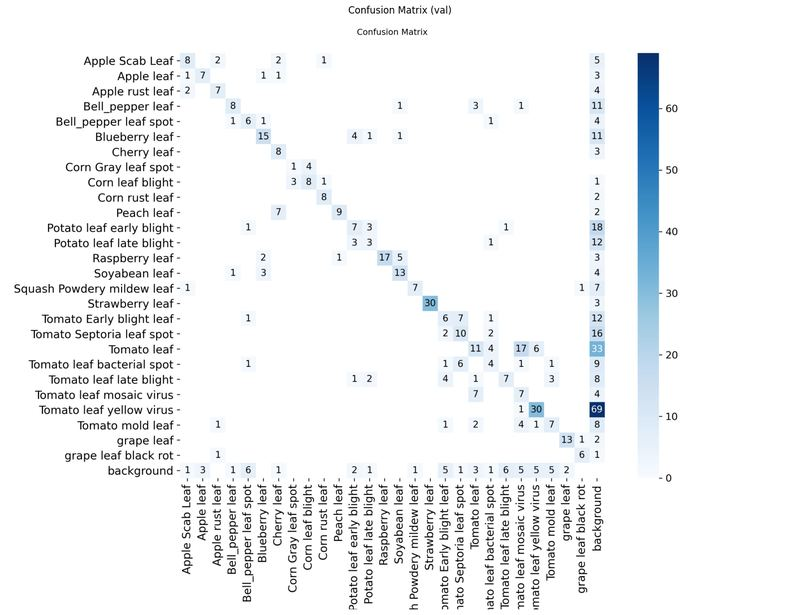

In [118]:
img_path = "/kaggle/working/runs/detect/val3/confusion_matrix.png"

if not os.path.exists(img_path):
    raise FileNotFoundError(f"confusion_matrix.png not found at: {img_path}")

img = Image.open(img_path)

plt.figure(figsize=(18, 18))
plt.imshow(img)
plt.axis("off")
plt.title("Confusion Matrix (val)")
plt.show()


In [119]:
# grab confusion matrix from ultralytics result
cm_obj = getattr(metrics, "confusion_matrix", None)
if cm_obj is None and hasattr(model, "validator") and model.validator is not None:
    cm_obj = getattr(model.validator, "confusion_matrix", None)

cm = cm_obj.matrix

names = model.names
if isinstance(names, dict):
    names = [names[i] for i in range(len(names))]

nc = len(names)
bg = nc  # last index is background

tp = int(np.diag(cm)[:nc].sum())
wrong_class = int(cm[:nc, :nc].sum() - np.diag(cm)[:nc].sum())

# rows = predicted, cols = ground-truth, last row/col = background
bg_as_target = int(cm[:nc, bg].sum())   # background column -> predicted object (FP / extra detections)
target_as_bg = int(cm[bg, :nc].sum())   # background row    -> missed objects (FN)

total_gt = int(cm[:, :nc].sum())

print("Total GT objects:", total_gt)
print("TP:", tp)
print("Wrong class:", wrong_class)
print("Background predicted as target (FP):", bg_as_target)
print("Target predicted as background (FN):", target_as_bg)
print("TP + Wrong + FN =", tp + wrong_class + target_as_bg)

Total GT objects: 454
TP: 263
Wrong class: 142
Background predicted as target (FP): 255
Target predicted as background (FN): 49
TP + Wrong + FN = 454




In [120]:
DATA_YAML = "/kaggle/working/data.yaml"
WEIGHTS  = "/kaggle/working/yolo_runs/plantdoc_yolo11n3/weights/best.pt"
SPLIT = "test"

N_SHOW = 50
IMGSZ = 640
DEVICE = 0

CONF_THRES = 0.25
PRED_NMS_IOU = 0.6
MATCH_IOU = 0.50

ROW_H = 4.2
FIG_W = 14

assert os.path.exists(WEIGHTS), f"WEIGHTS not found: {WEIGHTS}"
model = YOLO(WEIGHTS)

names = model.names
if isinstance(names, dict):
    names = [names[i] for i in range(len(names))]

def _resolve_path(base, p):
    if p is None:
        return None
    p = str(p)
    if os.path.isabs(p):
        return p
    return os.path.join(str(base), p) if base else p

def load_split_images(data_yaml, split="test"):
    with open(data_yaml, "r") as f:
        data = yaml.safe_load(f)

    base = data.get("path", None)
    entry = data.get(split, None)
    if entry is None:
        raise ValueError(f"'{split}:' not found in {data_yaml}")

    split_path = _resolve_path(base, entry)

    if os.path.isfile(split_path) and split_path.lower().endswith(".txt"):
        with open(split_path, "r") as f:
            imgs = [ln.strip() for ln in f if ln.strip()]
        imgs = [(_resolve_path(base, p) if not os.path.isabs(p) else p) for p in imgs]
        return imgs

    if os.path.isdir(split_path):
        imgs = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            imgs += glob.glob(os.path.join(split_path, ext))
        return sorted(imgs)

    imgs = sorted(glob.glob(split_path))
    if len(imgs) == 0:
        raise FileNotFoundError(f"No images found for {split}: {entry} -> {split_path}")
    return imgs

def img_to_label_path(img_path):
    p = img_path.replace("/images/", "/labels/")
    return str(Path(p).with_suffix(".txt"))

def read_yolo_label(lbl_path):
    if (not os.path.exists(lbl_path)) or os.path.getsize(lbl_path) == 0:
        return []
    rows = []
    with open(lbl_path, "r") as f:
        for line in f:
            s = line.strip().split()
            if len(s) != 5:
                continue
            rows.append([float(x) for x in s])
    return rows

def yolo_to_xyxy(row, W, H):
    cls, xc, yc, bw, bh = row
    x1 = (xc - bw / 2) * W
    y1 = (yc - bh / 2) * H
    x2 = (xc + bw / 2) * W
    y2 = (yc + bh / 2) * H
    x1 = max(0, min(x1, W - 1)); y1 = max(0, min(y1, H - 1))
    x2 = max(0, min(x2, W - 1)); y2 = max(0, min(y2, H - 1))
    return int(cls), float(x1), float(y1), float(x2), float(y2)

def iou_matrix(gt_xyxy, pr_xyxy):
    if gt_xyxy.size == 0 or pr_xyxy.size == 0:
        return np.zeros((gt_xyxy.shape[0], pr_xyxy.shape[0]), dtype=np.float32)

    gt = gt_xyxy[:, None, :]
    pr = pr_xyxy[None, :, :]

    ix1 = np.maximum(gt[..., 0], pr[..., 0])
    iy1 = np.maximum(gt[..., 1], pr[..., 1])
    ix2 = np.minimum(gt[..., 2], pr[..., 2])
    iy2 = np.minimum(gt[..., 3], pr[..., 3])

    iw = np.maximum(0.0, ix2 - ix1)
    ih = np.maximum(0.0, iy2 - iy1)
    inter = iw * ih

    gt_area = np.maximum(0.0, gt[..., 2] - gt[..., 0]) * np.maximum(0.0, gt[..., 3] - gt[..., 1])
    pr_area = np.maximum(0.0, pr[..., 2] - pr[..., 0]) * np.maximum(0.0, pr[..., 3] - pr[..., 1])
    union = gt_area + pr_area - inter + 1e-9

    return (inter / union).astype(np.float32)

def greedy_match(gt_xyxy, pr_xyxy, thr=0.5):
    G = gt_xyxy.shape[0]
    P = pr_xyxy.shape[0]
    if G == 0 and P == 0:
        return [], [], []
    if G == 0:
        return [], [], list(range(P))
    if P == 0:
        return [], list(range(G)), []

    iou = iou_matrix(gt_xyxy, pr_xyxy)
    gi, pi = np.where(iou >= thr)
    if gi.size == 0:
        return [], list(range(G)), list(range(P))

    pairs = np.stack([gi, pi, iou[gi, pi]], axis=1)
    pairs = pairs[np.argsort(-pairs[:, 2])]

    used_g, used_p = set(), set()
    matches = []
    for g, p, v in pairs:
        g = int(g); p = int(p)
        if g in used_g or p in used_p:
            continue
        used_g.add(g); used_p.add(p)
        matches.append((g, p, float(v)))

    unmatched_gt = [g for g in range(G) if g not in used_g]
    unmatched_pr = [p for p in range(P) if p not in used_p]
    return matches, unmatched_gt, unmatched_pr

def draw_box(img, x1, y1, x2, y2, color, text="", thickness=3):
    H, W = img.shape[:2]
    x1 = max(0, min(int(x1), W - 1)); y1 = max(0, min(int(y1), H - 1))
    x2 = max(0, min(int(x2), W - 1)); y2 = max(0, min(int(y2), H - 1))
    if x2 <= x1 or y2 <= y1:
        return

    cv2.rectangle(img, (x1, y1), (x2, y2), color, thickness)

    if text:
        font = cv2.FONT_HERSHEY_SIMPLEX
        fs = 0.65
        th = 2
        (tw, thh), _ = cv2.getTextSize(text, font, fs, th)
        pad = 4
        y_text = max(thh + 10, y1 - 8)
        cv2.rectangle(img, (x1, y_text - thh - pad), (x1 + tw + pad * 2, y_text + pad), (0, 0, 0), -1)
        cv2.putText(img, text, (x1 + pad, y_text), font, fs, color, th, cv2.LINE_AA)

COL_GT    = (0, 255, 0)
COL_FN    = (255, 0, 255)
COL_TP    = (255, 255, 0)
COL_WRONG = (0, 165, 255)
COL_FP    = (0, 0, 255)

img_paths = load_split_images(DATA_YAML, split=SPLIT)
to_show = img_paths[:min(N_SHOW, len(img_paths))]
if len(to_show) == 0:
    raise ValueError("No images found. Check data.yaml paths.")

preds = model.predict(
    source=to_show,
    conf=CONF_THRES,
    iou=PRED_NMS_IOU,
    imgsz=IMGSZ,
    device=DEVICE,
    verbose=False
)

n = len(preds)
fig, axes = plt.subplots(nrows=n, ncols=2, figsize=(FIG_W, max(6, ROW_H * n)))
if n == 1:
    axes = np.array([axes])

for row_i, r in enumerate(preds):
    img_path = r.path
    img = cv2.imread(img_path)
    if img is None:
        continue
    H, W = img.shape[:2]

    lbl_path = img_to_label_path(img_path)
    gt_rows = read_yolo_label(lbl_path)
    gt_list = [yolo_to_xyxy(row, W, H) for row in gt_rows]
    gt_xyxy = np.array([[x1, y1, x2, y2] for (c, x1, y1, x2, y2) in gt_list], dtype=np.float32)
    gt_cls  = np.array([c for (c, _, _, _, _) in gt_list], dtype=np.int32)

    vis_gt = img.copy()
    for (gcls, x1, y1, x2, y2) in gt_list:
        cname = names[gcls] if gcls < len(names) else str(gcls)
        draw_box(vis_gt, x1, y1, x2, y2, COL_GT, text=f"{cname}", thickness=3)

    if r.boxes is None or len(r.boxes) == 0:
        pr_xyxy = np.zeros((0, 4), dtype=np.float32)
        pr_cls  = np.zeros((0,), dtype=np.int32)
        pr_conf = np.zeros((0,), dtype=np.float32)
    else:
        pr_xyxy = r.boxes.xyxy.cpu().numpy().astype(np.float32)
        pr_cls  = r.boxes.cls.cpu().numpy().astype(np.int32)
        pr_conf = r.boxes.conf.cpu().numpy().astype(np.float32)

    matches, un_gt, un_pr = greedy_match(gt_xyxy, pr_xyxy, thr=MATCH_IOU)

    tp = 0
    wrong = 0
    fp = len(un_pr)
    fn = len(un_gt)

    vis_pred = img.copy()

    un_gt_set = set(un_gt)
    for gi, (gcls, x1, y1, x2, y2) in enumerate(gt_list):
        cname = names[gcls] if gcls < len(names) else str(gcls)
        if gi in un_gt_set:
            draw_box(vis_pred, x1, y1, x2, y2, COL_FN, text=f"FN {cname}", thickness=4)
        else:
            draw_box(vis_pred, x1, y1, x2, y2, COL_GT, text=f"GT {cname}", thickness=2)

    for (gi, pi, iou_val) in matches:
        gcls = int(gt_cls[gi])
        pcls = int(pr_cls[pi])
        conf = float(pr_conf[pi])

        gname = names[gcls] if gcls < len(names) else str(gcls)
        pname = names[pcls] if pcls < len(names) else str(pcls)

        x1, y1, x2, y2 = pr_xyxy[pi]
        if pcls == gcls:
            tp += 1
            draw_box(vis_pred, x1, y1, x2, y2, COL_TP, text=f"TP {pname} {conf:.2f}", thickness=3)
        else:
            wrong += 1
            draw_box(vis_pred, x1, y1, x2, y2, COL_WRONG, text=f"WRONG {pname} (GT {gname})", thickness=4)

    if gt_xyxy.shape[0] > 0 and pr_xyxy.shape[0] > 0:
        iou_all = iou_matrix(gt_xyxy, pr_xyxy)
        best_iou_per_pred = iou_all.max(axis=0)
    else:
        best_iou_per_pred = np.zeros((pr_xyxy.shape[0],), dtype=np.float32)

    for pi in un_pr:
        pcls = int(pr_cls[pi])
        conf = float(pr_conf[pi])
        pname = names[pcls] if pcls < len(names) else str(pcls)
        x1, y1, x2, y2 = pr_xyxy[pi]
        biou = float(best_iou_per_pred[pi]) if pi < len(best_iou_per_pred) else 0.0
        draw_box(vis_pred, x1, y1, x2, y2, COL_FP, text=f"FP {pname} {conf:.2f} IoU {biou:.2f}", thickness=4)

    axes[row_i, 0].imshow(cv2.cvtColor(vis_gt, cv2.COLOR_BGR2RGB))
    axes[row_i, 0].axis("off")
    axes[row_i, 0].set_title(Path(img_path).name)

    axes[row_i, 1].imshow(cv2.cvtColor(vis_pred, cv2.COLOR_BGR2RGB))
    axes[row_i, 1].axis("off")
    axes[row_i, 1].set_title(f"TP {tp}  WRONG {wrong}  FP {fp}  FN {fn}")

plt.tight_layout()
plt.show()